In [10]:
import numpy as np
import pandas as pd
from astropy.io import fits
from astropy.table import Table
import os

print(os.getcwd())

path_old1 = '../data/raw/Multiwave_6_12_26.fits'
path_old2 = '../data/raw/Multiwave_UMAP_6_22_26.csv'
path_csc = '../data/raw/csc_spec_fits.csv'
path_desi = '../data/raw/Multiwave_7_8_26.csv'
path = '../data/raw/Multiwave_UMAP_6_26_26.csv'

""" 
with fits.open(path) as hdul:
    table = Table(hdul[1].data)
    df = table.to_pandas()
"""

# ['Unnamed: 0.1', 'Unnamed: 0', 'name', 'non_agn', 'zErr_normgal', 'z_code_normgal', 
# 'opt_r', 'r_code_normgal', 'opt_g', 'g_code_normgal']


df = pd.read_csv(path)
df["name"] = df["name"].astype("string").str.strip()

df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df = df.set_index('name')
df = df.rename({'IR_agn': 'ir_agn'}, axis=1)


df.shape

c:\dev\ml-directory\projects\astro\notebooks


C:\Users\I\AppData\Local\Temp\ipykernel_15828\1889062198.py:25: DtypeWarning: Columns (0: conf_flag, 1: extent_flag, 2: PS21P_objID, 3: LEG21P_OBJID, 4: SDSS_CLASS, 5: SDSS_SUBCLASS, 6: AGNDB_spec_class, 7: AGNDB_gen_class, 8: AGNDB_SED_class, 9: AGNDB_xray_class, 10: AGNDB_image_class, 11: AGNDB_best_class, 12: xray_agn, 13: optical_agn, 14: IR_agn, 15: z_code_normgal, 16: r_code_normgal, 17: g_code_normgal) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


(170196, 170)

In [11]:
# Cross-match CSC
# Gamma spectral fit

spec = pd.read_csv(path_csc)
spec['name'] = (
    spec['name']
    .astype('string')
    .str.strip()
    .str.replace('2CXO ', '2CXO_', regex=False)
)

print(spec.shape)
print("Spectral fit columns: ", spec.columns.tolist())

# Merge
df = df.merge(spec, on="name", how="left", validate="many_to_one")
display(df.shape)


(166557, 17)
Spectral fit columns:  ['name', 'flux_powlaw', 'flux_powlaw_lolim', 'flux_powlaw_hilim', 'powlaw_gamma', 'powlaw_gamma_lolim', 'powlaw_gamma_hilim', 'powlaw_gamma_rhat', 'powlaw_nh', 'powlaw_nh_lolim', 'powlaw_nh_hilim', 'powlaw_nh_rhat', 'powlaw_ampl', 'powlaw_ampl_lolim', 'powlaw_ampl_hilim', 'powlaw_ampl_rhat', 'powlaw_stat']


C:\Users\I\AppData\Local\Temp\ipykernel_15828\2534224446.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df = df.merge(spec, on="name", how="left", validate="many_to_one")


(170196, 187)

In [12]:
# Cross-match DESI
# DESI

df_desi = pd.read_csv(path_desi)
df_desi["name"] = df_desi["name"].astype("string").str.strip()

print("DESI shape:", df_desi.shape)
print("DESI columns:", df_desi.columns.tolist())

desi_cols = [
    "name",
    "DESI_TARGETID",
    "DESI_Z",
    "DESI_ZERR",
    "DESI_ZWARN",
    "DESI_SPECTYPE",
    "DESI_SUBTYPE",
    "combo_Z",
    "z_source",
    "high_quality_z",
    "combo_SPECTYPE",
    "spectype_source",
    "ir_agn",
]

# Reduced dataset
desi_small = df_desi[desi_cols].copy()

# Renaming ir_agn to have no conflicts with current "ir_agn" in dataset
desi_small = desi_small.rename({"ir_agn": "ir_agn_desi"}, axis=1)


print("Before: \n", df["ir_agn"].value_counts())


df = df.merge(desi_small, on="name", how="left", validate="many_to_one")
df["ir_agn"] = (
    df["ir_agn"].fillna(False).astype(bool)
    | df["ir_agn_desi"].fillna(False).astype(bool) # + 1235 sources
    | df["combo_Z"].notna().astype(bool) # + 23219 sources
)

print("After: \n", df["ir_agn"].value_counts())

print("\nFinal shape:", df.shape)
print("DESI matches:", df["DESI_TARGETID"].notna().sum())
print("Sources with combo_Z:", df["combo_Z"].notna().sum())

DESI shape: (32260, 208)
DESI columns: ['Unnamed: 0.3', 'Unnamed: 0.2', 'Unnamed: 0.1', 'Unnamed: 0', 'name', 'ra', 'dec', 'gal_l', 'gal_b', 'err_ellipse_r0', 'err_ellipse_r1', 'err_ellipse_ang', 'significance', 'likelihood_class', 'conf_flag', 'extent_flag', 'flux_aper_b', 'flux_aper_lolim_b', 'flux_aper_hilim_b', 'flux_aper_h', 'flux_aper_lolim_h', 'flux_aper_hilim_h', 'flux_aper_m', 'flux_aper_lolim_m', 'flux_aper_hilim_m', 'flux_aper_s', 'flux_aper_lolim_s', 'flux_aper_hilim_s', 'flux_aper_u', 'flux_aper_lolim_u', 'flux_aper_hilim_u', 'flux_aper_w', 'flux_aper_lolim_w', 'flux_aper_hilim_w', 'hard_hm', 'hard_hm_lolim', 'hard_hm_hilim', 'var_inter_hard_prob_hm', 'var_inter_hard_sigma_hm', 'hard_hs', 'hard_hs_lolim', 'hard_hs_hilim', 'var_inter_hard_prob_hs', 'var_inter_hard_sigma_hs', 'hard_ms', 'hard_ms_lolim', 'hard_ms_hilim', 'var_inter_hard_prob_ms', 'var_inter_hard_sigma_ms', 'var_intra_index_b', 'var_intra_index_h', 'var_intra_index_m', 'var_intra_index_s', 'var_intra_index_u',

In [13]:
# Fixing bool columns
bool_cols = ['conf_flag', 'extent_flag', 'xray_agn', 'optical_agn', 'ir_agn']
df[bool_cols] = df[bool_cols].fillna(False).astype(bool)


# Treating ' ' as NaN
object_cols = df.select_dtypes(include='object').columns

df[object_cols] = df[object_cols].astype('string').apply(lambda col: col.str.strip())
df[object_cols] = df[object_cols].replace("", np.nan)


df.shape

C:\Users\I\AppData\Local\Temp\ipykernel_15828\1913031806.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  object_cols = df.select_dtypes(include='object').columns


(170196, 199)

In [14]:
agn_cols = ["xray_agn", "optical_agn", "ir_agn"]
neg_col = "non_agn"

for col in agn_cols:
    if col in df.columns:
        print(df[col].value_counts(dropna=False), "\n")

df["agn_class"] = (
    df["xray_agn"].fillna(False).astype(bool) |
    df["optical_agn"].fillna(False).astype(bool) |
    df["ir_agn"].fillna(False).astype(bool)
)

print(df["agn_class"].value_counts(dropna=False))

xray_agn
False    149033
True      21163
Name: count, dtype: int64 

optical_agn
False    156705
True      13491
Name: count, dtype: int64 

ir_agn
False    137821
True      32375
Name: count, dtype: int64 

agn_class
False    137060
True      33136
Name: count, dtype: int64


C:\Users\I\AppData\Local\Temp\ipykernel_15828\915934276.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["agn_class"] = (


In [15]:
# Feature augmentation: WISE, optical colors, X-ray / optical flux ratio


# Adding WISE / IR features
df['WISE_W1_W2'] = df['WISE_w1mpro'] - df['WISE_w2mpro']
df['WISE_W2_W3'] = df['WISE_w2mpro'] - df['WISE_w3mpro']

# Mateos wedge boundaries
x = df['WISE_W2_W3']
y = df['WISE_W1_W2']

mateos_wedge_mask = (
    (y <= 0.315*x + 0.796) &
    (y >= 0.315*x - 0.222) &
    (y >= -3.172*x + 7.264)
)

df["mateos_wedge"] = mateos_wedge_mask
print(df["mateos_wedge"].value_counts())

# Stern criterion
# df["wise_stern"] = df["WISE_W1_W2"] >= 0.8
# print(df["wise_stern"].value_counts())


'''
These are the WISE magnitudes we subtract to get colors. Colors in astronomy refer to magnitudes or fluxes in two bands being subtracted from each other.
The WISE color-color diagram is in the IR regime.
'''

# optical colors
df["PS_g_r"] = df["PS21P_g"] - df["PS21P_r"]
df["PS_r_i"] = df["PS21P_r"] - df["PS21P_i"]

df["LEG_G_R"] = df["LEG21P_G"] - df["LEG21P_R"]
df["LEG_R_Z"] = df["LEG21P_R"] - df["LEG21P_Z"]


# optical-to-IR colors
df["PS_r_W1"] = df["PS21P_r"] - df["WISE_w1mpro"]
df["PS_i_W2"] = df["PS21P_i"] - df["WISE_w2mpro"]


# X-ray flux / optical flux relation
for col in ["flux_aper_b", "flux_aper_h", "flux_aper_s"]:
    df[f"log_{col}"] = np.log10(df[col].where(df[col] > 0))

# Legacy ad hoc ratio formulas -- kept under _legacy names so existing downstream
# cells (silver score, UMAP highlight plots) don't silently break. Superseded by
# the systematic xray_ratio_{b,h,s}_<band> feature set built later in the notebook.
df["xray_opt_r_relation_legacy"] = df["log_flux_aper_b"] + 0.4 * df["PS21P_r"]
df["xray_opt_g_relation_legacy"] = df["log_flux_aper_b"] + 0.4 * df["PS21P_g"]


df = df.copy()
df.describe()

C:\Users\I\AppData\Local\Temp\ipykernel_15828\3734812855.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['WISE_W1_W2'] = df['WISE_w1mpro'] - df['WISE_w2mpro']
C:\Users\I\AppData\Local\Temp\ipykernel_15828\3734812855.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['WISE_W2_W3'] = df['WISE_w2mpro'] - df['WISE_w3mpro']
C:\Users\I\AppData\Local\Temp\ipykernel_15828\3734812855.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perfo

mateos_wedge
False    153060
True      17136
Name: count, dtype: int64


,ra,dec,gal_l,gal_b,err_ellipse_r0,err_ellipse_r1,err_ellipse_ang,significance,flux_aper_b,flux_aper_lolim_b,...,PS_r_i,LEG_G_R,LEG_R_Z,PS_r_W1,PS_i_W2,log_flux_aper_b,log_flux_aper_h,log_flux_aper_s,xray_opt_r_relation_legacy,xray_opt_g_relation_legacy
count,170196.000000,170196.000000,166557.000000,166557.000000,166557.000000,166557.000000,166557.000000,170196.000000,1.640560e+05,1.640560e+05,...,70459.000000,108372.000000,108372.000000,24234.000000,24234.000000,150474.000000,145887.000000,125000.000000,64772.000000,64772.000000
mean,163.702560,6.068684,183.570830,10.550394,1.914456,1.344876,84.084279,6.617441,6.342688e-14,5.285497e-14,...,-74.837181,0.902838,0.594151,-40.465384,-8.953730,-13.889235,-14.059102,-14.559594,-51.894255,-93.804944
std,96.587338,36.896440,96.337707,50.559120,2.522913,1.821505,54.258902,10.195499,3.659509e-12,3.032646e-12,...,348.390891,6.361833,5.482133,209.038725,117.536646,0.601417,0.567986,0.725166,129.282812,167.980213
min,0.001488,-86.643650,0.000841,-89.595725,0.293730,0.293730,0.000000,1.040000,0.000000e+00,0.000000e+00,...,-1023.486300,-41.649190,-36.459900,-1017.005000,-1015.512000,-17.618762,-17.525193,-18.286813,-416.303143,-416.127984
25%,81.093354,-21.131111,101.452093,-38.278631,0.490724,0.399150,37.410592,3.578947,4.023149e-15,2.538027e-15,...,0.023001,0.253280,0.253590,3.572225,4.281250,-14.267272,-14.417743,-15.031828,-6.456964,-7.818104
50%,173.744968,7.380546,180.687733,28.899282,0.995547,0.673998,84.845147,4.545455,1.090716e-14,7.724287e-15,...,0.259500,0.609630,0.674510,4.449450,4.992851,-13.901816,-14.061106,-14.566848,-5.512699,-5.532088
75%,218.685248,34.173576,267.729801,54.879801,2.219096,1.474126,129.769750,6.706975,2.708830e-14,2.041714e-14,...,0.509199,1.105668,1.141983,5.102424,5.563251,-13.528798,-13.704438,-14.117109,-5.126368,-5.066357
max,359.999948,89.391568,359.995000,89.692287,50.409077,43.824388,179.998690,1324.362393,1.317826e-09,1.096135e-09,...,1022.877001,39.571270,40.063210,14.645500,14.867600,-8.880142,-10.581723,-8.918685,-0.983342,-0.043869


# Magnitude -> Flux Conversion

Following Yang et al. 2022 (`references/notes/yang2022.md`, section 2): convert optical/NIR/IR
magnitudes to flux density (Jy) via a per-survey zero-point, then log10, so all photometric
features share the same physical scale as the X-ray fluxes (which are already log10'd as
`log_flux_aper_b/h/s`). This cell only sanity-checks two columns (one AB, one Vega system)
before applying the conversion to every magnitude column.

In [ ]:
# Zero-point table (Jy) per magnitude column -- see src/features.py for the
# conversion logic and CLAUDE.md ("Photometric units and zero-points") for the sources.
import sys
from pathlib import Path

_project_root = str(Path("..").resolve())
if _project_root not in sys.path:
    sys.path.append(_project_root)

import matplotlib.pyplot as plt
from src.features import (
    ZERO_POINT_JY,
    mag_to_flux_jy,
    apply_mag_to_flux_conversion,
    cross_check_mag_zero_point,
)

zp_table = pd.DataFrame({
    "column": list(ZERO_POINT_JY.keys()),
    "zero_point_jy": list(ZERO_POINT_JY.values()),
    "system": ["AB"] * 7 + ["Vega"] * 6 + ["Vega (approx)"] * 1,
})
display(zp_table)

**Zero-point sources & caveats**

- AB system (`PS21P_*`, `LEG21P_*`): flat 3631 Jy by definition of the AB magnitude system.
- WISE (Vega): Cutri et al. 2011 / Jarrett et al. 2011 WISE All-Sky Explanatory Supplement zero-points.
- 2MASS (Vega): Cohen, Wheaton & Megeath (2003) absolute calibration.
- `GAIA21P_g` (Vega-like): Gaia DR3 VEGAMAG zero-point, **approximate**. Gaia's photometric
  calibration has a known color term that introduces roughly ±0.05 mag of residual scatter in G,
  and the exact zero-point differs slightly between DR2/EDR3/DR3 -- treat `GAIA21P_g` fluxes as
  good to only ~5%, not exact.
- Columns **not** present in this catalog release, so not in the table above: `PS21P_y`, Gaia
  `BP`/`RP`, WISE `W4`. If a future catalog version adds any of these, this table needs a
  corresponding zero-point entry before converting them -- it will silently skip anything not
  listed here.

WISE_w1mpro zero-point: 309.54 Jy (Vega)
Non-positive sentinel values masked to NaN: 485

Before (magnitude, raw incl. sentinel):
count    37742.000000
mean         1.411255
std        114.166965
min       -999.000000
25%         13.498250
50%         15.228000
75%         15.958000
max         18.891000
Name: WISE_w1mpro, dtype: float64

After (flux, Jy):
count    37257.000000
mean         0.030512
std          0.655681
min          0.000009
25%          0.000127
50%          0.000246
75%          0.001070
max         90.098338
Name: WISE_w1mpro, dtype: float64

After (log10 flux, Jy) -- this is what would enter the model:
count    37257.000000
mean        -3.283002
std          0.931489
min         -5.065683
25%         -3.896483
50%         -3.609283
75%         -2.970483
max          1.954717
Name: WISE_w1mpro, dtype: float64


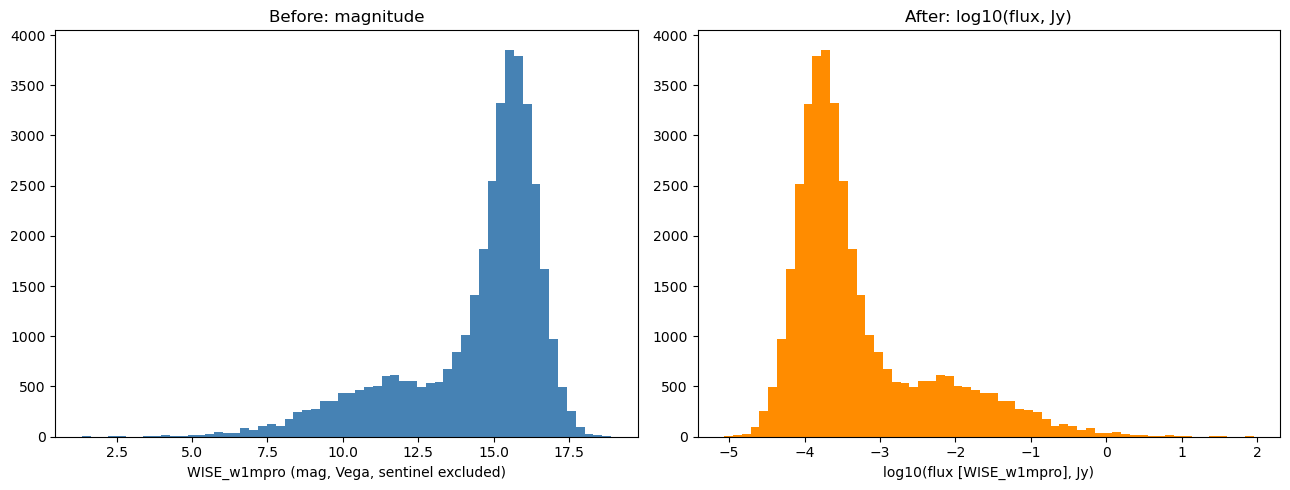

In [17]:
# Sanity check 1: WISE W1 (Vega system) -- before (magnitude) vs after (flux, Jy)
col = "WISE_w1mpro"
zp = ZERO_POINT_JY[col]

mag_before = df[col]
n_sentinel = (mag_before <= 0).sum()
flux_after_jy = mag_to_flux_jy(mag_before, zp)
log_flux_after = np.log10(flux_after_jy.where(flux_after_jy > 0))

print(f"{col} zero-point: {zp} Jy (Vega)")
print(f"Non-positive sentinel values masked to NaN: {n_sentinel}")
print("\nBefore (magnitude, raw incl. sentinel):")
print(mag_before.describe())
print("\nAfter (flux, Jy):")
print(flux_after_jy.describe())
print("\nAfter (log10 flux, Jy) -- this is what would enter the model:")
print(log_flux_after.describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(mag_before[mag_before > 0].dropna(), bins=60, color="steelblue")
axes[0].set_xlabel(f"{col} (mag, Vega, sentinel excluded)")
axes[0].set_title("Before: magnitude")

axes[1].hist(log_flux_after.dropna(), bins=60, color="darkorange")
axes[1].set_xlabel(f"log10(flux [{col}], Jy)")
axes[1].set_title("After: log10(flux, Jy)")

plt.tight_layout()
plt.show()

PS21P_r zero-point: 3631.0 Jy (AB)
Non-positive sentinel values masked to NaN: 8083

Before (magnitude, raw incl. sentinel):
count    70459.000000
mean       -96.901597
std        324.746235
min       -999.000000
25%         18.378050
50%         20.458599
75%         21.387950
max         25.252001
Name: PS21P_r, dtype: float64

After (flux, Jy):
count    6.237600e+04
mean     1.136403e-02
std      2.572332e-01
min      2.878896e-07
25%      9.401048e-06
50%      1.879430e-05
75%      6.040267e-05
max      2.749326e+01
Name: PS21P_r, dtype: float64

After (log10 flux, Jy) -- this is what would enter the model:
count    62376.000000
mean        -4.438738
std          0.917959
min         -6.540774
25%         -5.026824
50%         -4.725974
75%         -4.218944
max          1.439226
Name: PS21P_r, dtype: float64


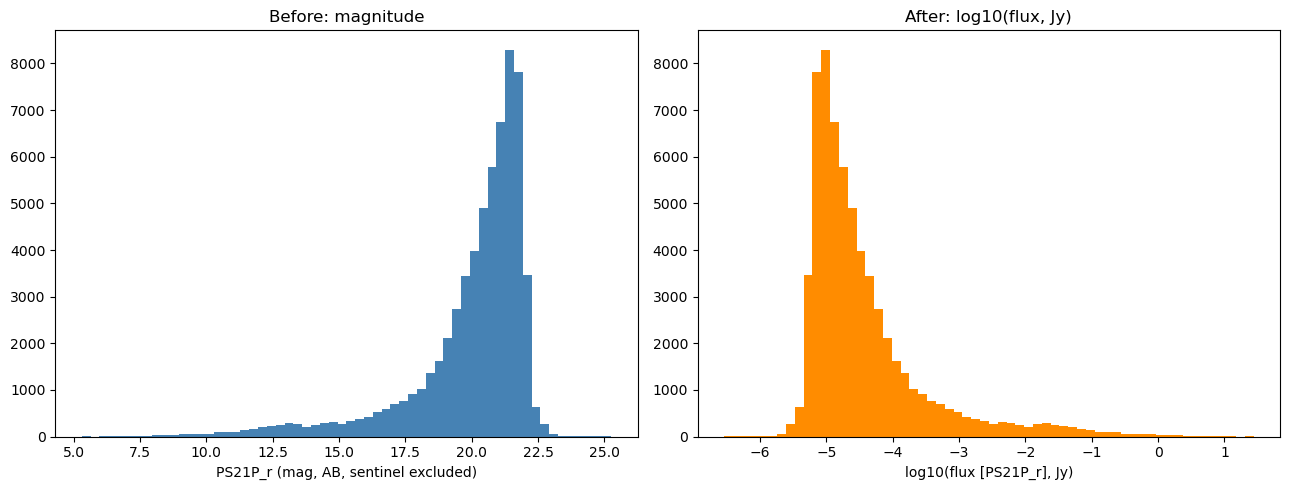

In [18]:
# Sanity check 2: PS21P_r (AB system) -- before (magnitude) vs after (flux, Jy)
col = "PS21P_r"
zp = ZERO_POINT_JY[col]

mag_before = df[col]
n_sentinel = (mag_before <= 0).sum()
flux_after_jy = mag_to_flux_jy(mag_before, zp)
log_flux_after = np.log10(flux_after_jy.where(flux_after_jy > 0))

print(f"{col} zero-point: {zp} Jy (AB)")
print(f"Non-positive sentinel values masked to NaN: {n_sentinel}")
print("\nBefore (magnitude, raw incl. sentinel):")
print(mag_before.describe())
print("\nAfter (flux, Jy):")
print(flux_after_jy.describe())
print("\nAfter (log10 flux, Jy) -- this is what would enter the model:")
print(log_flux_after.describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(mag_before[mag_before > 0].dropna(), bins=60, color="steelblue")
axes[0].set_xlabel(f"{col} (mag, AB, sentinel excluded)")
axes[0].set_title("Before: magnitude")

axes[1].hist(log_flux_after.dropna(), bins=60, color="darkorange")
axes[1].set_xlabel(f"log10(flux [{col}], Jy)")
axes[1].set_title("After: log10(flux, Jy)")

plt.tight_layout()
plt.show()

# Magnitude -> Flux Conversion (full batch)

In [ ]:
# Apply the magnitude -> flux conversion to every column in the zero-point table.
# SDSS_CALIBFLUX_* and log_flux_aper_* are already fluxes and are skipped entirely
# (see src/features.py for the per-band diagnostic + sentinel-masking logic).
df = apply_mag_to_flux_conversion(df)

# Cross-check utility (regression test for future conversions)

In [ ]:
# AB-system cross-check: PS21P_r (mag, AB) vs SDSS_CALIBFLUX_r (already a flux, AB nanomaggies)
# cross_check_mag_zero_point is imported from src.features (see zero-point table cell above).
_ = cross_check_mag_zero_point(df, "PS21P_r", "SDSS_CALIBFLUX_r", label="PS21P_r vs SDSS r (AB)")

In [21]:
# No independent survey in this catalog re-observes the WISE bands (3.4/4.6/12 micron),
# so a same-band cross-survey check like the PS21P_r/SDSS one above isn't available here.
# As a next-best Vega-system spot-check, compare our zero-point-derived flux against the
# flux implied by the WISE Explanatory Supplement's published Vega->AB magnitude offsets
# (delta_m = 2.699 / 3.339 / 5.174 for W1/W2/W3) combined with the standard 3631 Jy AB
# zero-point. These offsets come from a different calibration reference than the
# Jarrett et al. 2011 zero-points used above, so a few-percent difference is expected
# paper-to-paper scatter, not evidence of an error.

WISE_VEGA_TO_AB_OFFSET = {"WISE_w1mpro": 2.699, "WISE_w2mpro": 3.339, "WISE_w3mpro": 5.174}

for col, offset in WISE_VEGA_TO_AB_OFFSET.items():
    mag_valid = df[col].where(df[col] > 0)

    flux_from_zp = mag_to_flux_jy(mag_valid, ZERO_POINT_JY[col])
    flux_from_ab_offset = 3631.0 * 10 ** (-0.4 * (mag_valid + offset))

    pct_diff = (flux_from_zp - flux_from_ab_offset) / flux_from_ab_offset * 100
    print(f"{col}: zero-point flux vs Vega->AB-offset flux differ by "
          f"{pct_diff.median():+.2f}% (n={mag_valid.notna().sum()})")

WISE_w1mpro: zero-point flux vs Vega->AB-offset flux differ by +2.40% (n=37257)
WISE_w2mpro: zero-point flux vs Vega->AB-offset flux differ by +2.46% (n=37257)
WISE_w3mpro: zero-point flux vs Vega->AB-offset flux differ by +2.39% (n=37255)


# X-ray / Multiwavelength Flux-Ratio Features

In [22]:
# Systematic X-ray/optical and X-ray/IR flux-ratio features: log10(F_x) - log10(F_band)
# for every converted MW band against X-ray broadband (b), hard (h), and soft (s).
# This generalizes/replaces the ad hoc xray_opt_r_relation (kept as xray_opt_r_relation_legacy
# in the feature-augmentation cell above so nothing downstream silently breaks).

XRAY_LOG_FLUX_COLS = {"b": "log_flux_aper_b", "h": "log_flux_aper_h", "s": "log_flux_aper_s"}

ratio_cols_created = []
for mw_col in ZERO_POINT_JY:
    mw_log_flux_col = f"log_flux_{mw_col}"
    for xband, x_col in XRAY_LOG_FLUX_COLS.items():
        ratio_col = f"xray_ratio_{xband}_{mw_col}"
        df[ratio_col] = df[x_col] - df[mw_log_flux_col]
        ratio_cols_created.append(ratio_col)

print(f"Created {len(ratio_cols_created)} X-ray/MW flux-ratio columns.")

Created 42 X-ray/MW flux-ratio columns.


# Batch Summary

In [23]:
new_flux_cols = [f"flux_jy_{c}" for c in ZERO_POINT_JY] + [f"log_flux_{c}" for c in ZERO_POINT_JY]
all_new_cols = new_flux_cols + ratio_cols_created

summary = pd.DataFrame({
    "column": all_new_cols,
    "median": [df[c].median() for c in all_new_cols],
})

print(f"Total new columns created: {len(all_new_cols)}")
display(summary)

Total new columns created: 70


,column,median
0,flux_jy_PS21P_g,0.000015
1,flux_jy_PS21P_r,0.000019
2,flux_jy_PS21P_i,0.000022
3,flux_jy_PS21P_z,0.000031
4,flux_jy_LEG21P_G,0.000004
...,...,...
65,xray_ratio_h_2MASS21P_k_m,-11.580175
66,xray_ratio_s_2MASS21P_k_m,-11.967807
67,xray_ratio_b_GAIA21P_g,-9.135378
68,xray_ratio_h_GAIA21P_g,-9.293619


# Raw Magnitude Column Sentinel Masking

In [ ]:
# Extend the mag <= 0 -> NaN sentinel rule (already applied to the derived flux/log-flux
# columns above) to the underlying RAW magnitude columns themselves. X (the UMAP feature
# matrix, built below) and X_all (the supervised classifier feature matrix, built later)
# both select numeric columns directly from df -- so until now, only the derived columns
# were masked, and the raw -999/-9 sentinels were silently feeding the SimpleImputer median,
# StandardScaler mean/std, and PCA components computed on these columns before any
# conversion happens. This must run upstream of both X and X_all construction.

for col in ZERO_POINT_JY:
    old_min = df[col].min()
    old_n_sentinel = int((df[col] <= 0).sum())

    df[col] = df[col].where(df[col] > 0)

    new_min = df[col].min()
    new_n_nan = int(df[col].isna().sum())

    print(f"{col:16s} | old_min={old_min:9.2f} sentinel_count={old_n_sentinel:6d} | "
          f"new_min={new_min:9.3f} nan_count={new_n_nan:6d}")

$1e42<=L_{X}<=1e43: 1918
IR AGN in subset: 272


(-1.15, 3.1)

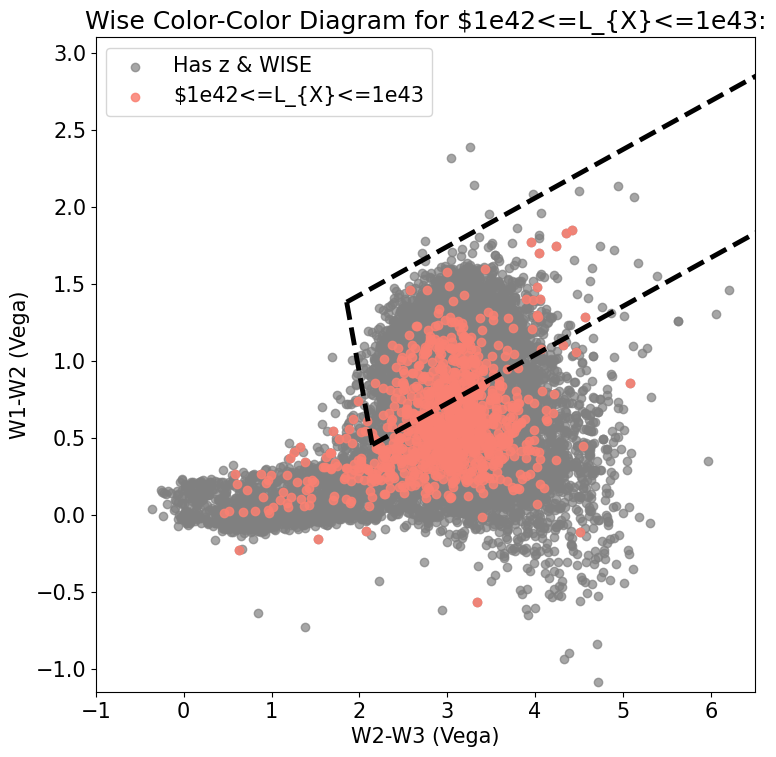

In [24]:
# WISE color color diagram
import matplotlib.pyplot as plt

plt.figure(figsize=(8.5,8.5))
plt.rcParams.update({'font.size': 15})


'''
Defining the IR AGN in our subset, I'd recommend doing something like db['lum_sub']=db['name'].isin(db_sub['name']), which will return true if it's 
contained in the subset which makes for easy filtering
'''

df_z_w = df.dropna(subset=['WISE_w1mpro', 'Rec_Z'])

# luminosity subset
lum_mask = (df['CSC_b_lum']>=1e42) & (df['CSC_b_lum']<=1e43)
df_sub = df[lum_mask]
print(r'$1e42<=L_{X}<=1e43:', len(df_sub))

x_sub = df_sub['WISE_W2_W3']
y_sub = df_sub['WISE_W1_W2']

wedge_mask_sub = (
    (y_sub <= 0.315*x_sub + 0.796) &
    (y_sub >= 0.315*x_sub - 0.222) &
    (y_sub >= -3.172*x_sub + 7.264)
)

df_sub['inside_wise_wedge'] = wedge_mask_sub


dub_sub_ir=df_sub[df_sub['inside_wise_wedge']]
print('IR AGN in subset:', len(dub_sub_ir))

#Physical boundaries of the wedge, easier to plot the endpoints than the actual function
plt.plot([1.855, 8.587], [1.380, 3.501], c='black', linestyle='--', linewidth=3.5)
plt.plot([2.147, 8.587], [0.454, 2.483], c='black', linestyle='--', linewidth=3.5)
plt.plot([1.855, 2.147], [1.380, 0.454], c='black', linestyle='--', linewidth=3.5)


plt.scatter(df_z_w['WISE_w2mpro']-df_z_w['WISE_w3mpro'], df_z_w['WISE_w1mpro']-df_z_w['WISE_w2mpro'], color='gray', alpha=0.7, label='Has z & WISE')
plt.scatter(x_sub, y_sub, color='salmon', alpha=0.85, label=(r'$1e42<=L_{X}<=1e43'))
plt.xlabel('W2-W3 (Vega)')
plt.ylabel('W1-W2 (Vega)')
plt.title('Wise Color-Color Diagram for ' + r'$1e42<=L_{X}<=1e43:')
plt.legend(loc='upper left')
plt.xlim(-1, 6.5)
plt.ylim(-1.15, 3.1)

In [25]:
# Gamma CSC spectral fit

spectral_candidates = [
    c for c in df.columns
    if any(key in c.lower() for key in [
        "gamma",
        "spectral",
        "powlaw",
        "powerlaw",
        "photon_index",
        "pl_index",
    ])
]

print(spectral_candidates)

df["powlaw_gamma"] = pd.to_numeric(df["powlaw_gamma"], errors="coerce")
df["has_csc_spectral_fit"] = df["powlaw_gamma"] > 0  # non-NaN values >0

print("Sources with CSC power-law spectral fit:", df["has_csc_spectral_fit"].sum())

['flux_powlaw', 'flux_powlaw_lolim', 'flux_powlaw_hilim', 'powlaw_gamma', 'powlaw_gamma_lolim', 'powlaw_gamma_hilim', 'powlaw_gamma_rhat', 'powlaw_nh', 'powlaw_nh_lolim', 'powlaw_nh_hilim', 'powlaw_nh_rhat', 'powlaw_ampl', 'powlaw_ampl_lolim', 'powlaw_ampl_hilim', 'powlaw_ampl_rhat', 'powlaw_stat']
Sources with CSC power-law spectral fit: 17811


In [26]:
# combo_Z redshift DESI

# If columns are bool - fine. If it's string "False"/"True", carefully check
def to_bool_safe(s):
    if pd.api.types.is_bool_dtype(s):
        return s.fillna(False)
    return (
        s.astype("string")
        .str.strip()
        .str.lower()
        .isin(["true", "t", "1", "yes", "y"])
    )
for col in agn_cols + [neg_col]:
    df[col] = to_bool_safe(df[col])
    


df["has_combo_z"] = (
    pd.to_numeric(df["combo_Z"], errors="coerce")
    .gt(0)
)



# Если high_quality_z существует, сохраняем более строгую версию
if "high_quality_z" in df.columns:
    df["has_high_quality_combo_z"] = (
        df["has_combo_z"]
        & to_bool_safe(df["high_quality_z"])
    )
else:
    df["has_high_quality_combo_z"] = df["has_combo_z"]

"""
# CSC gamma/spectral fit:
# non-NaN and > 0 означает, что fit действительно присутствует
if spectral_fit_col in df.columns:
    spectral_values = pd.to_numeric(
        df[spectral_fit_col],
        errors="coerce"
    )

    df["has_csc_spectral_fit"] = spectral_values.gt(0)

else:
    raise KeyError(
        f"Spectral-fit column {spectral_fit_col!r} was not found. "
        "Run the spectral_candidates search and insert its real name."
    )
"""

print("Sources with combo_Z:", df["has_combo_z"].sum())
print(
    "Sources with high-quality combo_Z:",
    df["has_high_quality_combo_z"].sum()
)
print(
    "Sources with CSC spectral fit:",
    df["has_csc_spectral_fit"].sum()
)

Sources with combo_Z: 31773
Sources with high-quality combo_Z: 27335
Sources with CSC spectral fit: 17811


In [27]:
# =====================
# Gold labels
# =====================

# 1. Positive marker: confirmed AGN
df["agn_positive"] = df[agn_cols].any(axis=1)

# 2. Negative marker: confirmed non-AGN / galaxies
df["agn_negative"] = df[neg_col]

# 3. Conflict marker: if object is simultaneously marked as AGN and non-AGN
df["label_conflict"] = df["agn_positive"] & df["agn_negative"]
print("Label conflicts:", (df["agn_positive"] & df["agn_negative"]).sum())

df["agn_negative"] = df["agn_negative"] & ~df["agn_positive"] # priority to positive labels

 


# =====================
# Silver labels
# =====================

# 4. Silver score
df["silver_score"] = 0.0

# 1. WISE color
df.loc[df["mateos_wedge"].fillna(False), "silver_score"] += 0.35
# df.loc[df["wise_stern"].fillna(False), "silver_score"] += 0.25

# 2. CSC Gamma spectral fit
df.loc[df["has_csc_spectral_fit"], "silver_score"] += 0.35


# 3. High X-ray-to-optical proxy
q80_r = df["xray_opt_r_relation_legacy"].quantile(0.80) 
df.loc[df["xray_opt_r_relation_legacy"] >= q80_r, "silver_score"] += 0.15

# 4. Redshift is supporting evidence, not AGN evidence by itself
df.loc[df["has_high_quality_combo_z"], "silver_score"] += 0.15


# X-ray luminosity
# df.loc[df["CSC_b_lum"].between(1e42, 1e43), "silver_score"] += 0.20

# Finalizing
df["silver_score"] = df["silver_score"].clip(0, 1)
df["silver_agn"] = (
    (df["silver_score"] >= 0.01) &
    ~df["agn_positive"] &
    ~df["agn_negative"]
)

print(df["silver_agn"].value_counts())


# UMAP
df["label_3class"] = np.select(
    [
        df["agn_positive"],
        df["agn_negative"],
        df["silver_agn"]
    ],
    [
        2,   # confirmed AGN
        0,   # confirmed non-AGN
        1,   # AGNs from silver dataset
    ],
    default=-1  # unlabeled
).astype("int8")

# Defragmentation of dataset
df = df.copy()
df_umap_base = df.copy()



# ML 
df["label_source"] = "unlabeled"

df.loc[df["agn_negative"], "label_source"] = "negative"
df.loc[df["silver_agn"], "label_source"] = "silver"
df.loc[df["agn_positive"], "label_source"] = "gold"

df["train_label"] = -1

df.loc[df["agn_negative"], "train_label"] = 0
df.loc[df["silver_agn"], "train_label"] = 1
df.loc[df["agn_positive"], "train_label"] = 1

df["sample_weight"] = 0.

df.loc[df["agn_negative"], "sample_weight"] = 1.
df.loc[df["agn_positive"], "sample_weight"] = 1.
df.loc[df["silver_agn"], "sample_weight"] = (
    0.3 +
    0.7*df.loc[df["silver_agn"], "silver_score"]
)


# Defragmentation of dataset
df = df.copy()
df_train = df.copy()

print(df["label_3class"].value_counts().sort_index())
print(df["label_source"].value_counts())
#anchor1

Label conflicts: 2510
silver_agn
False    147232
True      22964
Name: count, dtype: int64
label_3class
-1    108059
 0      6037
 1     22964
 2     33136
Name: count, dtype: int64
label_source
unlabeled    108059
gold          33136
silver        22964
negative       6037
Name: count, dtype: int64


In [12]:
for col in df.columns:
    print(col, end=' ')
    
df.shape

name ra dec gal_l gal_b err_ellipse_r0 err_ellipse_r1 err_ellipse_ang significance likelihood_class conf_flag extent_flag flux_aper_b flux_aper_lolim_b flux_aper_hilim_b flux_aper_h flux_aper_lolim_h flux_aper_hilim_h flux_aper_m flux_aper_lolim_m flux_aper_hilim_m flux_aper_s flux_aper_lolim_s flux_aper_hilim_s flux_aper_u flux_aper_lolim_u flux_aper_hilim_u flux_aper_w flux_aper_lolim_w flux_aper_hilim_w hard_hm hard_hm_lolim hard_hm_hilim var_inter_hard_prob_hm var_inter_hard_sigma_hm hard_hs hard_hs_lolim hard_hs_hilim var_inter_hard_prob_hs var_inter_hard_sigma_hs hard_ms hard_ms_lolim hard_ms_hilim var_inter_hard_prob_ms var_inter_hard_sigma_ms var_intra_index_b var_intra_index_h var_intra_index_m var_intra_index_s var_intra_index_u var_intra_index_w var_inter_index_b var_inter_index_h var_inter_index_m var_inter_index_s var_inter_index_u var_inter_index_w PS21P_objID PS21P_ra PS21P_dec Sep_PS21P_CSC21P PS21P_g PS21P_r PS21P_i PS21P_z GAIA21P_source_id GAIA21P_ra GAIA21P_dec Sep_

(170196, 226)

# UMAP Part

We prepare data, perform PCA to reduce noise and unnecesarry columns, and then plot it against data, NaN values, observations by source, etc.

# Reduced Dataset Case

*!* Run this cell only if we need to do UMAP on reduced (without NaN values) subset

In [28]:
display(df_umap_base.shape)

df_umap_base['combo_g']=df_umap_base['PS21P_g'].combine_first(df_umap_base['LEG21P_G'])
df_umap_base['combo_r']=df_umap_base['PS21P_r'].combine_first(df_umap_base['LEG21P_R'])
df_umap_base['combo_z_mag']=df_umap_base['PS21P_z'].combine_first(df_umap_base['LEG21P_Z'])


df_umap_base = df_umap_base.dropna(subset=['significance', 'flux_aper_b', 'flux_aper_lolim_b', 'flux_aper_hilim_b', 'flux_aper_h','flux_aper_lolim_h',
'flux_aper_hilim_h','flux_aper_s','flux_aper_lolim_s','flux_aper_hilim_s','flux_aper_m','flux_aper_lolim_m','flux_aper_hilim_m','combo_g','combo_r','combo_z_mag','WISE_w1mpro', 
'WISE_w1snr','WISE_w2mpro', 'WISE_w2snr','WISE_w3mpro', 'WISE_w3snr', "hard_hs", "hard_hs_lolim", "hard_hs_hilim"])

df_sample = df_umap_base.copy()

reduced_cols = ['significance', 'flux_aper_b', 'flux_aper_lolim_b', 'flux_aper_hilim_b', 'flux_aper_h','flux_aper_lolim_h',
'flux_aper_hilim_h','flux_aper_s','flux_aper_lolim_s','flux_aper_hilim_s','flux_aper_m','flux_aper_lolim_m','flux_aper_hilim_m','combo_g','combo_r','combo_z_mag','WISE_w1mpro', 
'WISE_w1snr','WISE_w2mpro', 'WISE_w2snr','WISE_w3mpro', 'WISE_w3snr', "hard_hs", "hard_hs_lolim", "hard_hs_hilim"]



df_umap_base = df_umap_base[reduced_cols]

display(df_umap_base.shape)

X_pca = df_umap_base.copy()


(170196, 293)

(28632, 25)

# General UMAP case

For general case, we avoid the previous cell, and run all the cells except previous one.
Here we do data imputation, adding missing indicators to dataset.

In [ ]:
exclude_cols = [
    "name",
    "col1",
    
    # AGN labels
    "xray_agn",
    "optical_agn",
    "ir_agn",
    "agn_class",
    "agn_positive",
    
    # non-AGN labels
    "non_agn",
    "agn_negative",
    
    # derived labels
    "label_3class",
    "label_conflict",
    "silver_score",
    "silver_agn",
    "binary_target",
    
    # training info
    "train_label", "train_weight", "label_source", "sample_weight",
    
    # masks
    "mateos_wedge",
    "wise_stern",

    # class / metadata columns
    "likelihood_class",
    "SDSS_CLASS",
    "SDSS_SUBCLASS",
    "2MASS21P_designation"
]

exclude_cols = [c for c in exclude_cols if c in df_umap_base.columns]

X = df_umap_base.drop(columns=exclude_cols, errors="ignore")
print(X.shape)

X = X.select_dtypes(include=[np.number]).copy()
print(X.shape)


display(X.head(20))

In [ ]:
# Dropping sparse features
feature_missing_percent = X.isna().mean() * 100

display(
    feature_missing_percent.sort_values(ascending=False).head(10)
)

max_feature_missing = 90

keep_cols = feature_missing_percent[feature_missing_percent <= max_feature_missing].index
X = X[keep_cols].copy()

print(X.shape)

In [ ]:
# Special column processing (big data): ['CSC_b_lum']
num = X.select_dtypes(include=[np.number])
summary = pd.DataFrame({
    "dtype": num.dtypes,
    "missing_pct": num.isna().mean() * 100,
    "min": num[num != 0].min(),
    "max": num.max(),
    "max_abs": num.abs().max(),
    "median": num.median(),
    "mean": num.mean(),
    "std": num.std(),
    "nunique": num.nunique()
}).sort_values("max_abs", ascending=False)

display(summary.head(50))


big_cols = summary[summary["max_abs"] > 1e20].index.tolist()
display(big_cols)

for col in big_cols: 
    X.loc[X[col] <= 0, col] = np.nan
    X[col + "_log10"] = np.log10(X[col])
    X = X.drop(columns=col)

X = X.copy()

In [ ]:
# Imputing and encoding missing data
from sklearn.impute import SimpleImputer

sample_size = len(df_umap_base) # we can adjust however we want

df_sample = df_umap_base.sample(
    n=min(sample_size, len(df_umap_base)),
    random_state=42
).sort_index().copy()

X_sample = X.loc[df_sample.index].copy()

print(df_sample.shape)
print(X_sample.shape)



missing_indicators = X_sample.isna().astype("int8")
missing_indicators.columns = [f"{col}_missing" for col in X_sample.columns]

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_sample)


X_umap_input = np.hstack([
    X_imputed,
    missing_indicators.values
]).astype("float32")

print(X_umap_input.shape)

In [ ]:
# PCA before UMAP
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# We can also use RobustScaler (instead of StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_umap_input).astype("float32")

# Checking most optimal parameters
for n in [10, 20, 30, 50, 100]: 
    pca = PCA(n_components=n, random_state=42)
    X_pca = pca.fit_transform(X_scaled).astype("float32")

    print(
        n,
        pca.explained_variance_ratio_.sum()
    )

n_pca = min(50, X_scaled.shape[1]) # we can adjust; max_n_cols = 216

pca = PCA(n_components=n_pca, random_state=42)
X_pca = pca.fit_transform(X_scaled).astype("float32")

# Wrap as a DataFrame (index/columns) so downstream cells shared with the "Reduced Dataset
# Case" branch (where X_pca is already a DataFrame) work uniformly on either branch.
X_pca = pd.DataFrame(
    X_pca,
    index=df_sample.index,
    columns=[f"pca_{i}" for i in range(X_pca.shape[1])],
)

print(X_pca.shape)
print("Explained variance:", pca.explained_variance_ratio_.sum())


# UMAP itself

In [29]:
import time
import umap
import pandas as pd
import matplotlib.pyplot as plt

neighbors_list = [15, 20, 50, 100]

umap_results = {}
embeddings = {}

for n_neighbors in neighbors_list:
    print(f"Running UMAP with n_neighbors={n_neighbors}")

    reducer = umap.UMAP(
        n_neighbors=n_neighbors,
        min_dist=0.1,
        n_components=2,
        metric="euclidean",
        random_state=42,
        low_memory=True,
    )

    start = time.perf_counter()
    runtime = time.perf_counter() - start

    embedding = reducer.fit_transform(X_pca)
    embeddings[n_neighbors] = embedding

    result = df_sample.copy()
    result["UMAP1"] = embedding[:, 0]
    result["UMAP2"] = embedding[:, 1]
    result["NaN_percent"] = X_pca.isna().mean(axis=1) * 100


    umap_results[n_neighbors] = result

    print(
        f"n_neighbors={n_neighbors}: "
        f"shape={embedding.shape}, time={runtime:.1f} sec"
    )

Running UMAP with n_neighbors=15


c:\Users\I\miniforge3\envs\quant\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\I\miniforge3\envs\quant\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


n_neighbors=15: shape=(28632, 2), time=0.0 sec
Running UMAP with n_neighbors=20


c:\Users\I\miniforge3\envs\quant\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\I\miniforge3\envs\quant\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


n_neighbors=20: shape=(28632, 2), time=0.0 sec
Running UMAP with n_neighbors=50


c:\Users\I\miniforge3\envs\quant\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\I\miniforge3\envs\quant\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


n_neighbors=50: shape=(28632, 2), time=0.0 sec
Running UMAP with n_neighbors=100


c:\Users\I\miniforge3\envs\quant\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\I\miniforge3\envs\quant\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


n_neighbors=100: shape=(28632, 2), time=0.0 sec


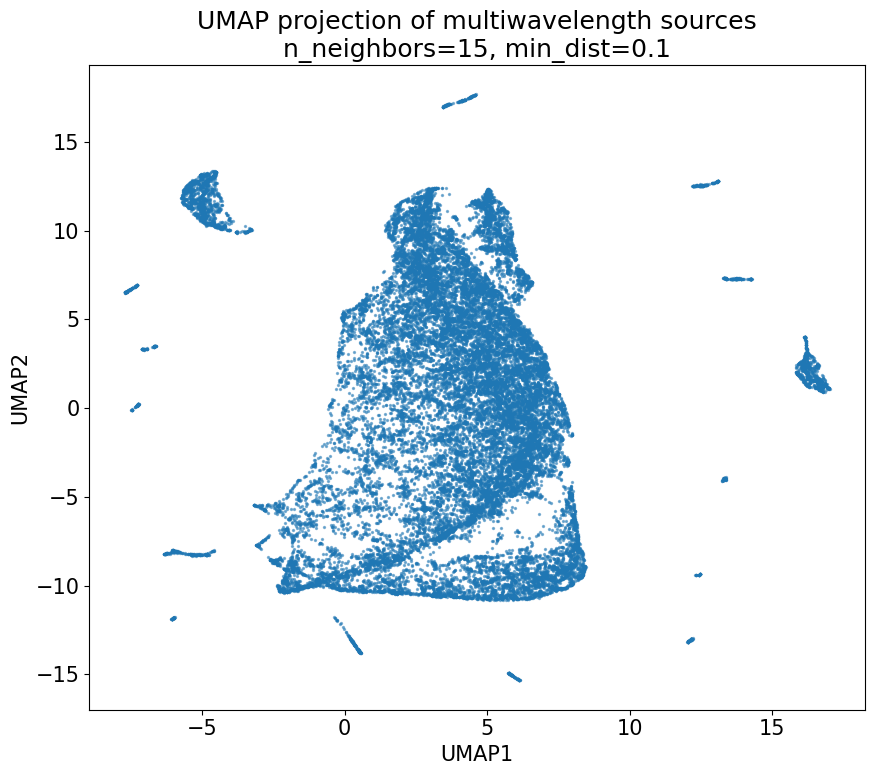

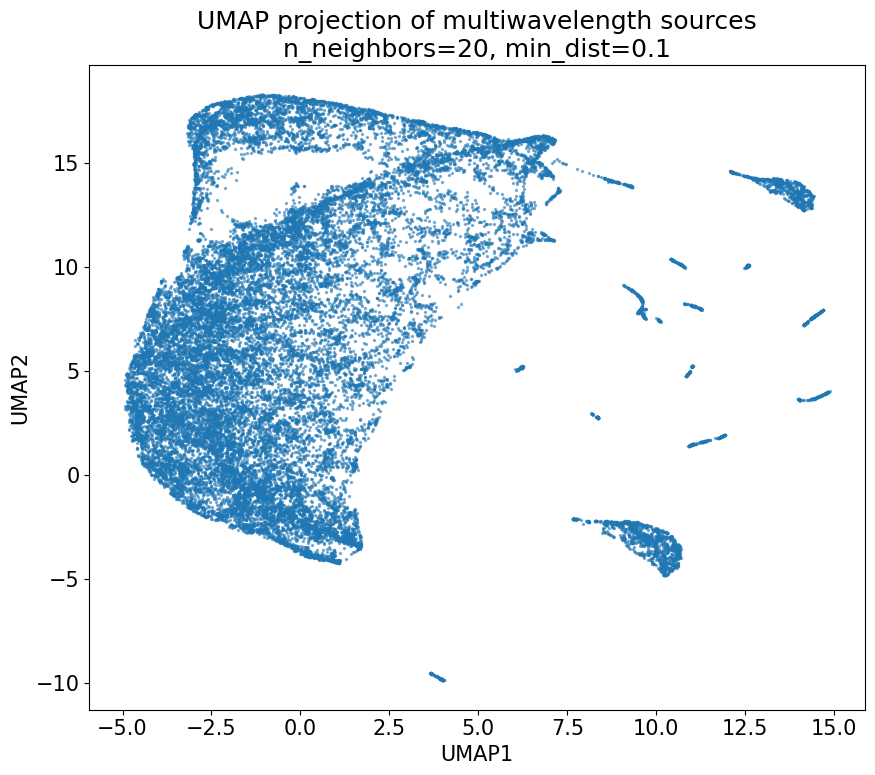

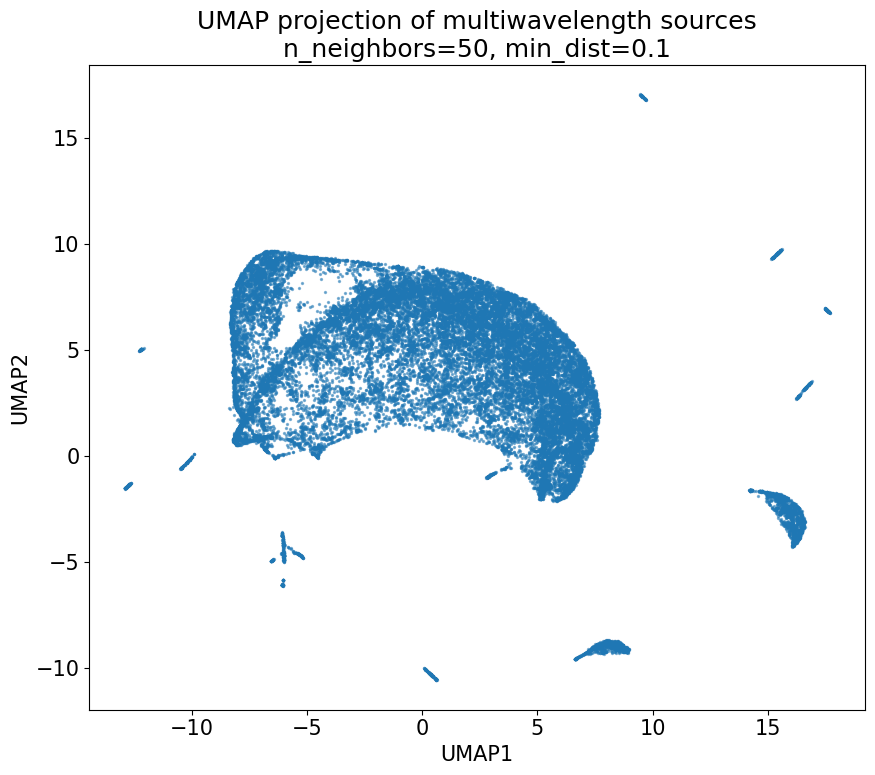

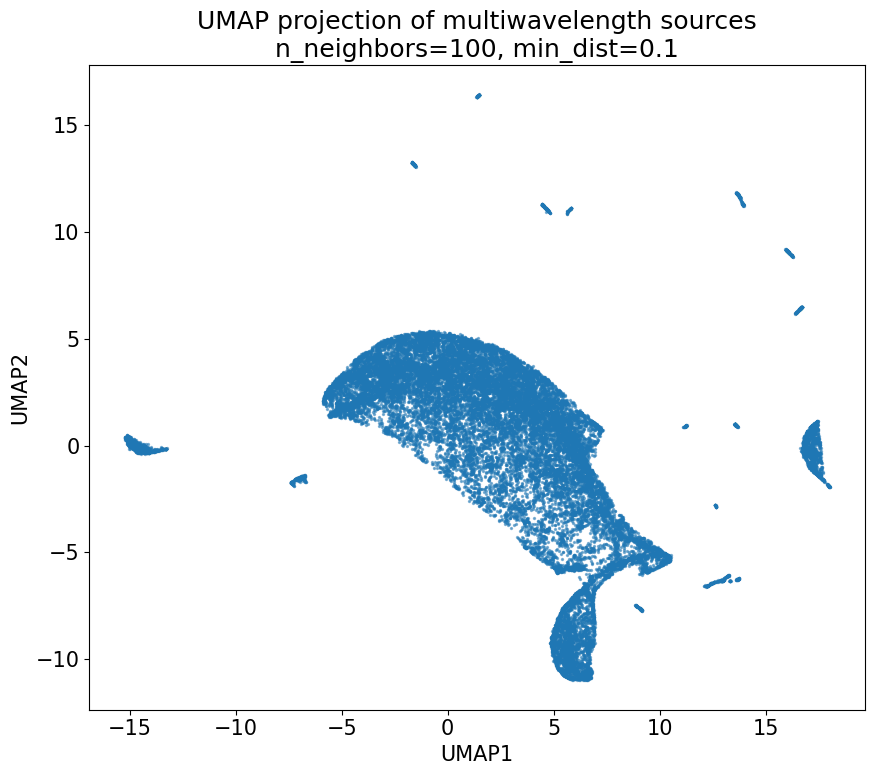

In [30]:
for n_neighbors in neighbors_list:
    result = umap_results[n_neighbors]

    plt.figure(figsize=(9, 8))

    plt.scatter(
        result["UMAP1"],
        result["UMAP2"],
        s=2,
        alpha=0.5,
    )

    plt.xlabel("UMAP1")
    plt.ylabel("UMAP2")
    plt.title(
        f"UMAP projection of multiwavelength sources\n"
        f"n_neighbors={n_neighbors}, min_dist=0.1"
    )

    plt.tight_layout()
    plt.show()

# Plots common

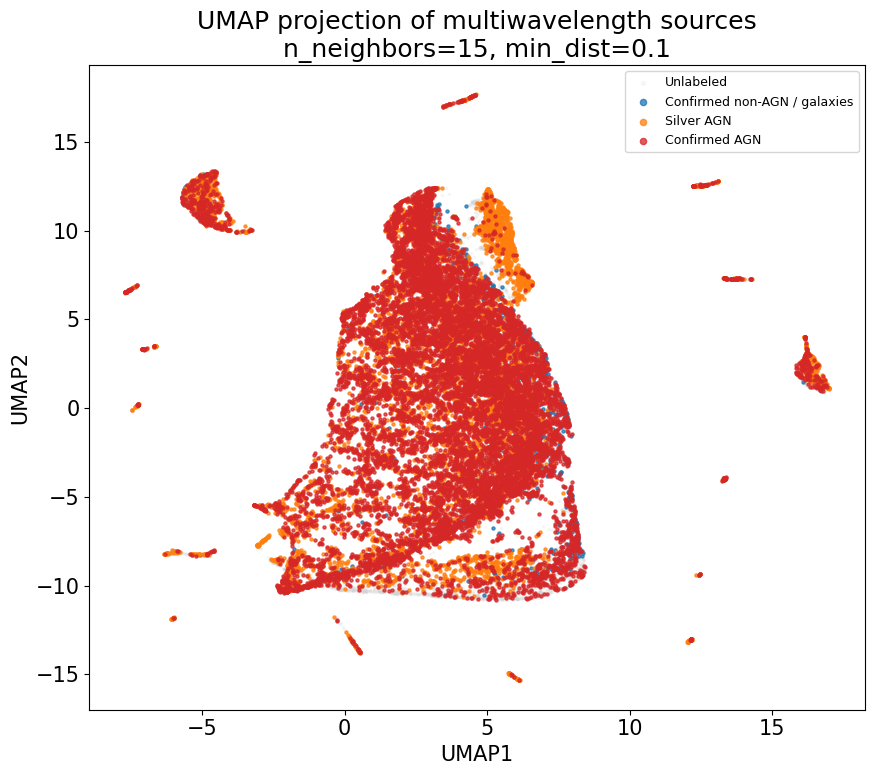

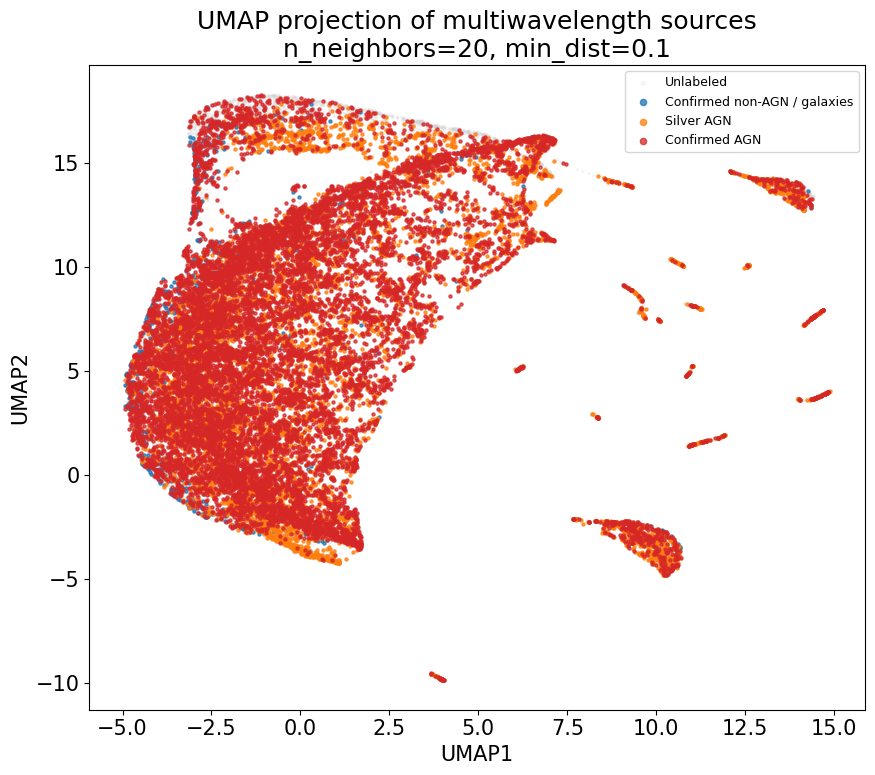

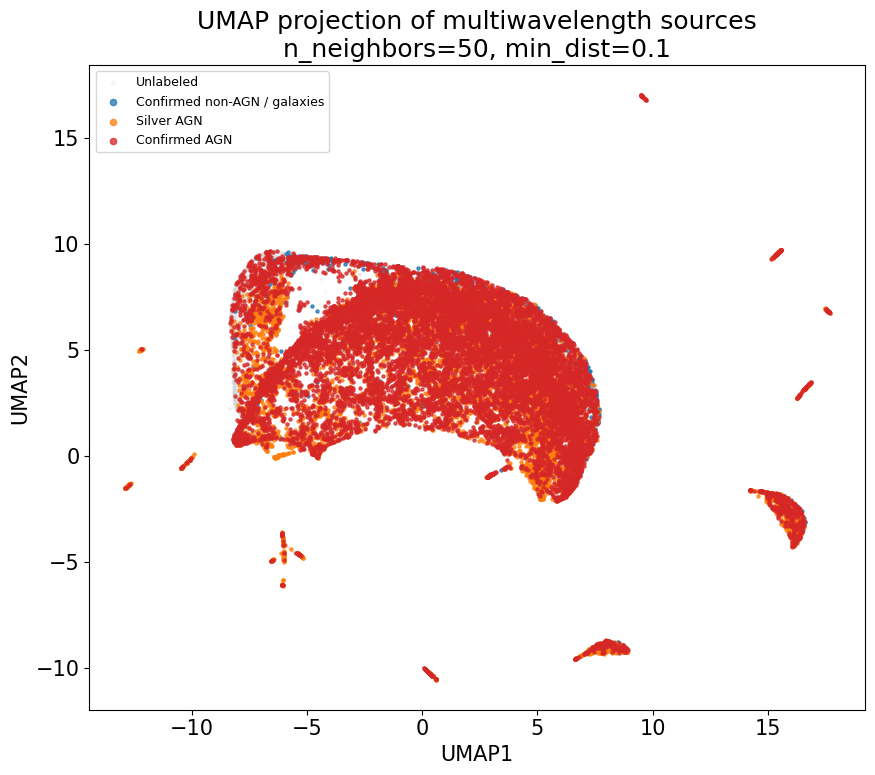

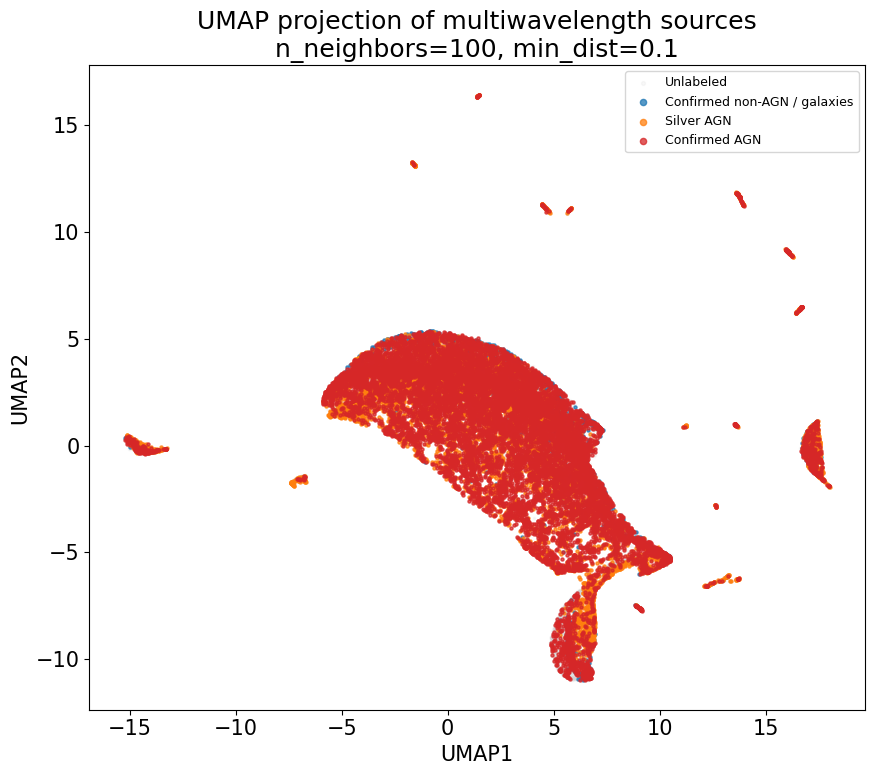

In [31]:
for n_neighbors in neighbors_list:
    plt.figure(figsize=(9, 8))
    result = umap_results[n_neighbors]

    mask_agn = result["label_3class"] == 2
    mask_nonagn = result["label_3class"] == 0
    mask_unlabeled = result["label_3class"] == -1
    mask_silver = result["label_3class"] == 1


    plt.scatter(
        result.loc[mask_unlabeled, "UMAP1"],
        result.loc[mask_unlabeled, "UMAP2"],
        s=2,
        alpha=0.15,
        color="lightgray",
        label="Unlabeled",
    )

    plt.scatter(
        result.loc[mask_nonagn, "UMAP1"],
        result.loc[mask_nonagn, "UMAP2"],
        s=5,
        alpha=0.75,
        color="tab:blue",
        label="Confirmed non-AGN / galaxies",
    )

    plt.scatter(
        result.loc[mask_silver, "UMAP1"],
        result.loc[mask_silver, "UMAP2"],
        s=5,
        alpha=0.75,
        color="tab:orange",
        label="Silver AGN",
    )

    plt.scatter(
        result.loc[mask_agn, "UMAP1"],
        result.loc[mask_agn, "UMAP2"],
        s=5,
        alpha=0.75,
        color="tab:red",
        label="Confirmed AGN",
    )

    plt.xlabel("UMAP1")
    plt.ylabel("UMAP2")

    plt.title(
        "UMAP projection of multiwavelength sources\n"
        f"n_neighbors={n_neighbors}, min_dist=0.1"
    )

    plt.legend(
        fontsize=9,
        markerscale=2,
    )

    plt.tight_layout()
    plt.show()

# Plot separate (AGNs, galaxies, silver sample)

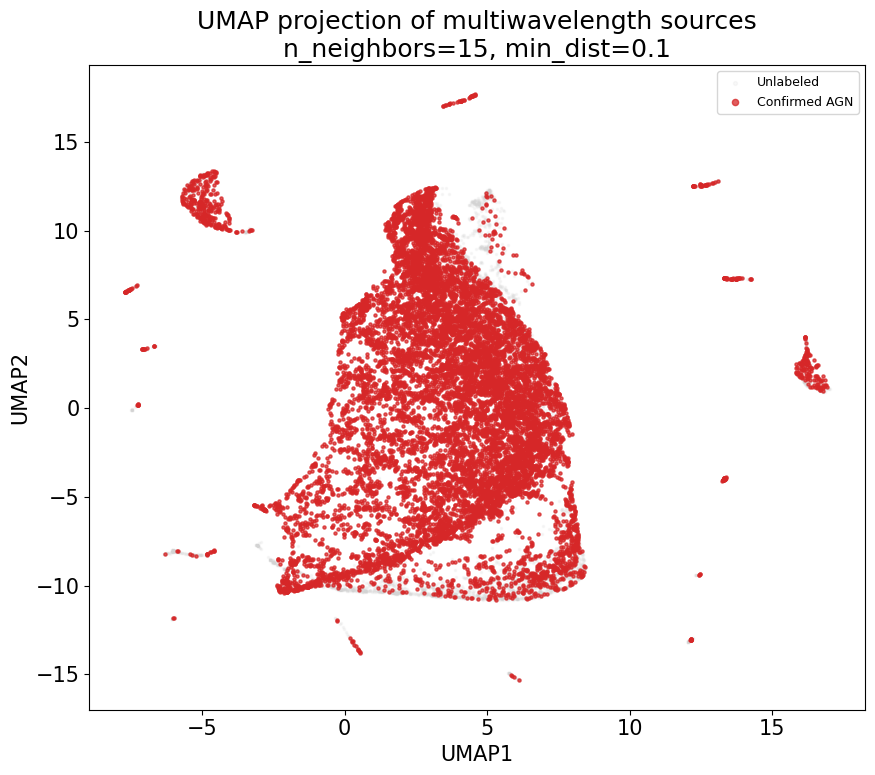

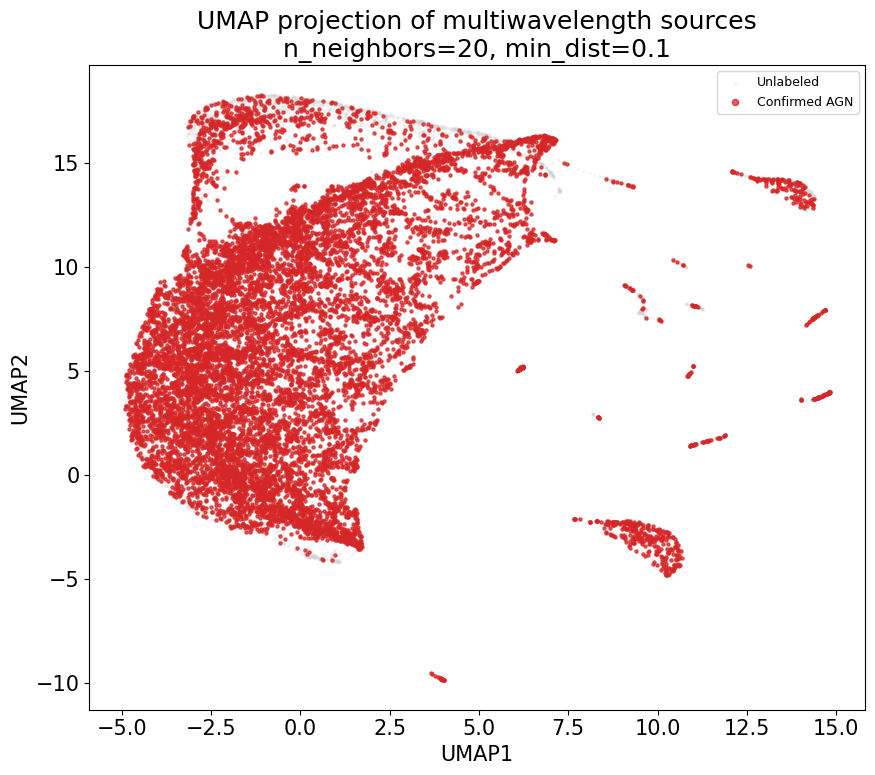

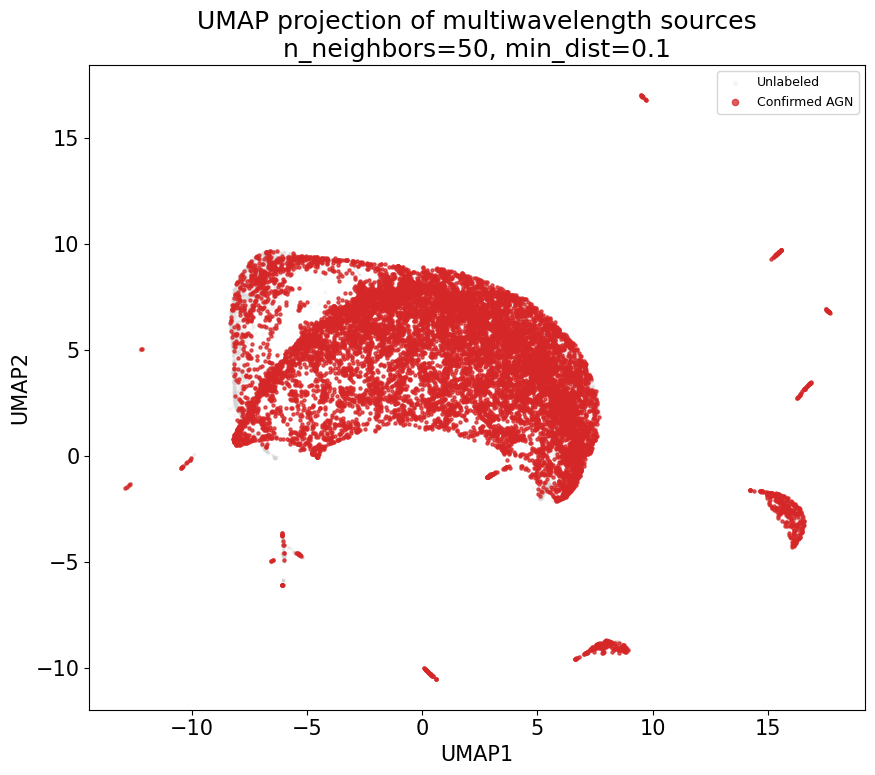

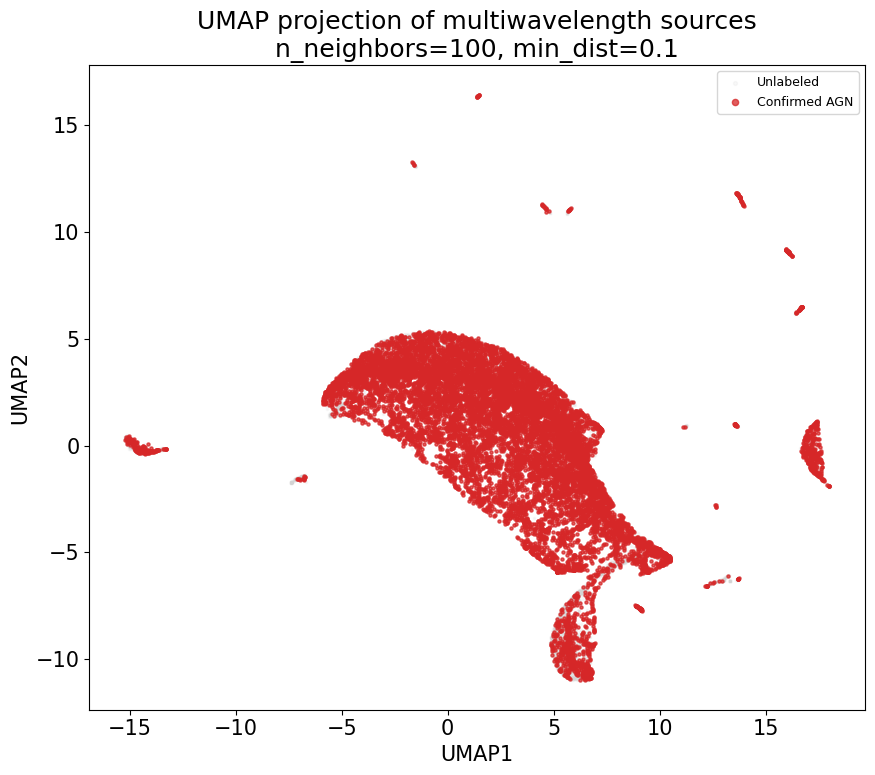

In [32]:
for n_neighbors in neighbors_list:
    plt.figure(figsize=(9, 8))
    result = umap_results[n_neighbors]

    mask_agn = result["label_3class"] == 2
    mask_unlabeled = result["label_3class"] == -1


    plt.scatter(
        result.loc[mask_unlabeled, "UMAP1"],
        result.loc[mask_unlabeled, "UMAP2"],
        s=2,
        alpha=0.15,
        color="lightgray",
        label="Unlabeled",
    )

    plt.scatter(
        result.loc[mask_agn, "UMAP1"],
        result.loc[mask_agn, "UMAP2"],
        s=5,
        alpha=0.75,
        color="tab:red",
        label="Confirmed AGN",
    )

    plt.xlabel("UMAP1")
    plt.ylabel("UMAP2")

    plt.title(
        "UMAP projection of multiwavelength sources\n"
        f"n_neighbors={n_neighbors}, min_dist=0.1"
    )

    plt.legend(
        fontsize=9,
        markerscale=2,
    )

    plt.tight_layout()
    plt.show()

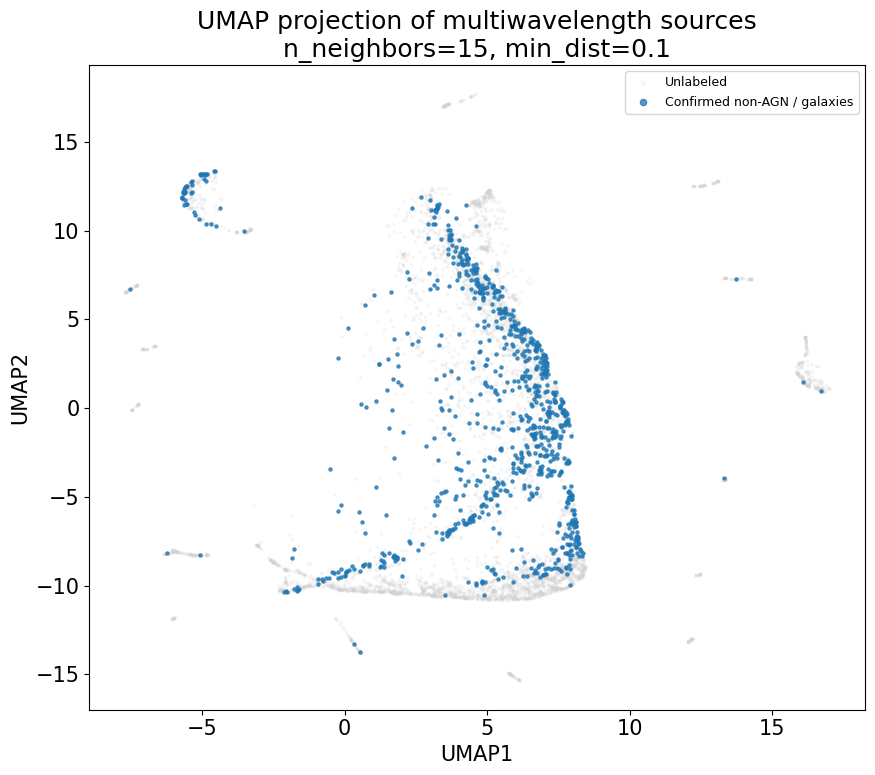

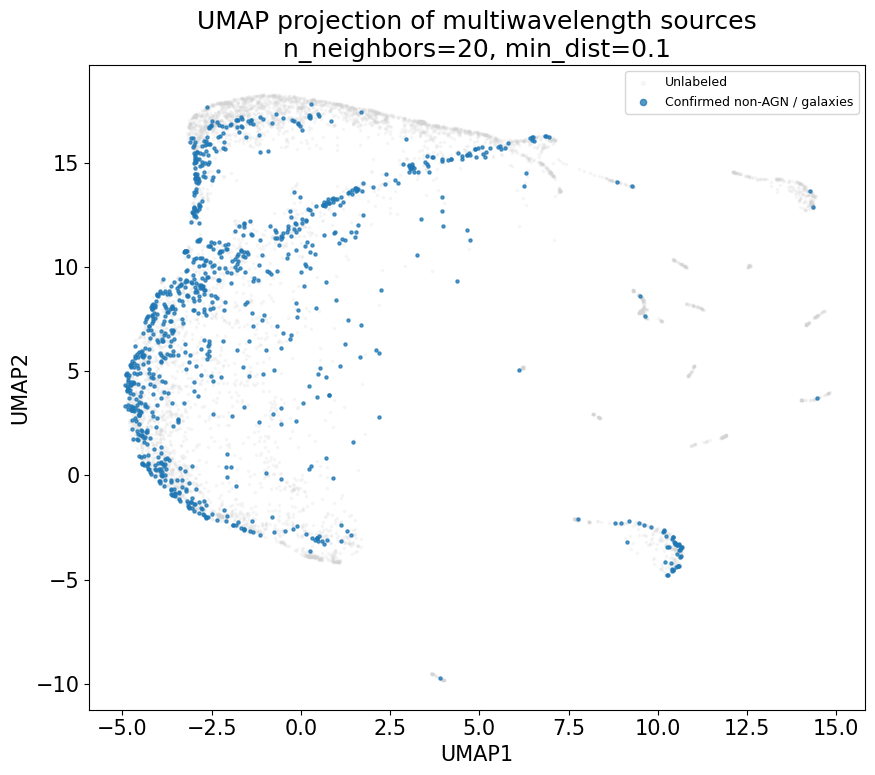

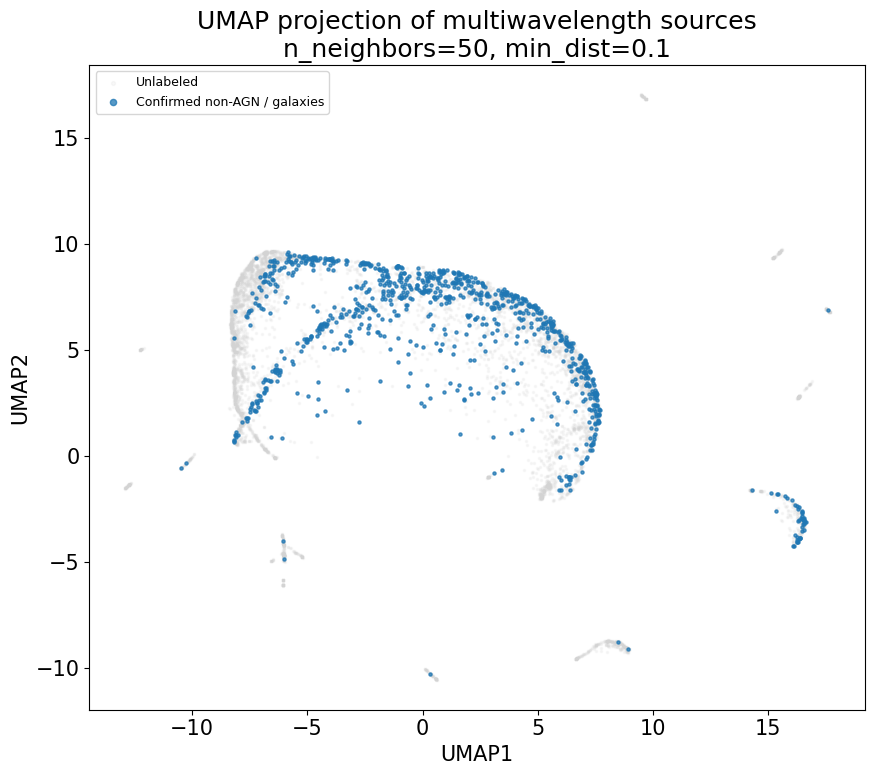

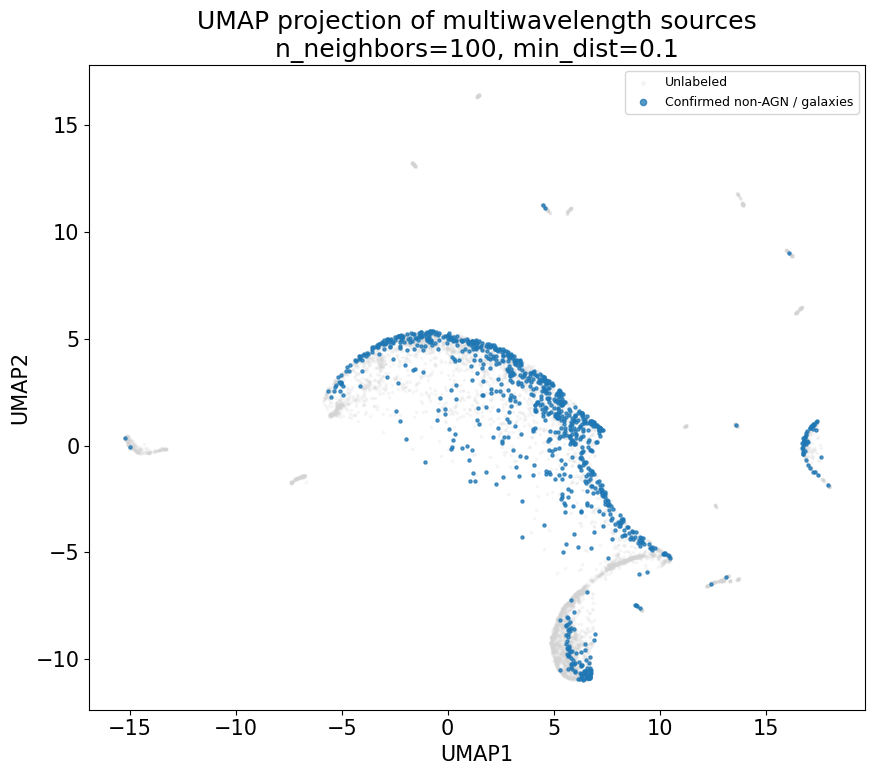

In [33]:
for n_neighbors in neighbors_list:
    plt.figure(figsize=(9, 8))
    result = umap_results[n_neighbors]

    mask_nonagn = result["label_3class"] == 0
    mask_unlabeled = result["label_3class"] == -1


    plt.scatter(
        result.loc[mask_unlabeled, "UMAP1"],
        result.loc[mask_unlabeled, "UMAP2"],
        s=2,
        alpha=0.15,
        color="lightgray",
        label="Unlabeled",
    )

    plt.scatter(
        result.loc[mask_nonagn, "UMAP1"],
        result.loc[mask_nonagn, "UMAP2"],
        s=5,
        alpha=0.75,
        color="tab:blue",
        label="Confirmed non-AGN / galaxies",
    )

    plt.xlabel("UMAP1")
    plt.ylabel("UMAP2")

    plt.title(
        "UMAP projection of multiwavelength sources\n"
        f"n_neighbors={n_neighbors}, min_dist=0.1"
    )

    plt.legend(
        fontsize=9,
        markerscale=2,
    )

    plt.tight_layout()
    plt.show()

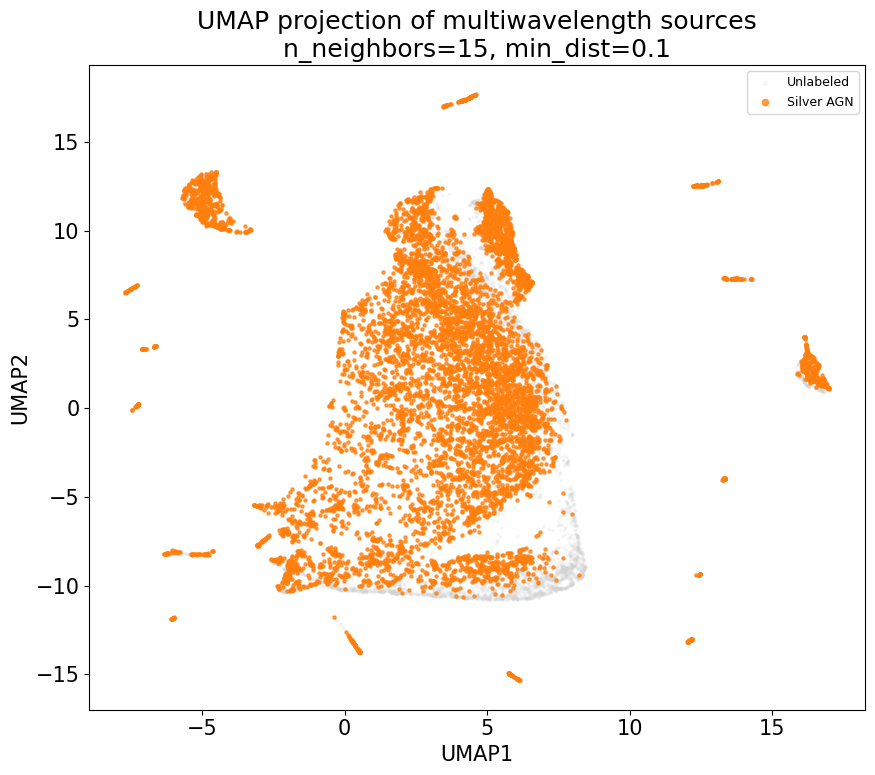

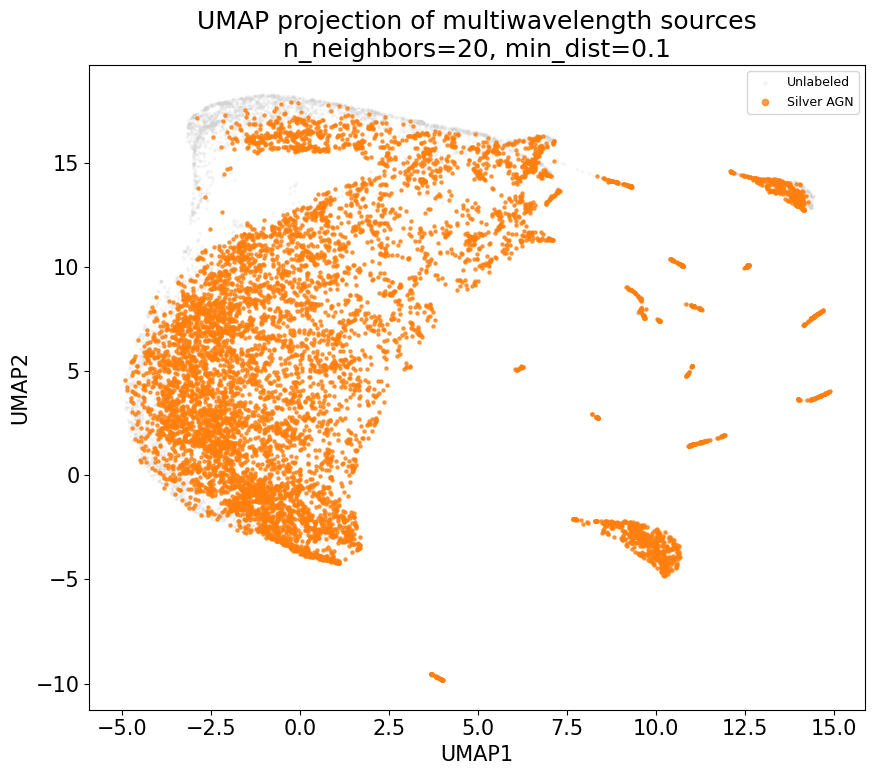

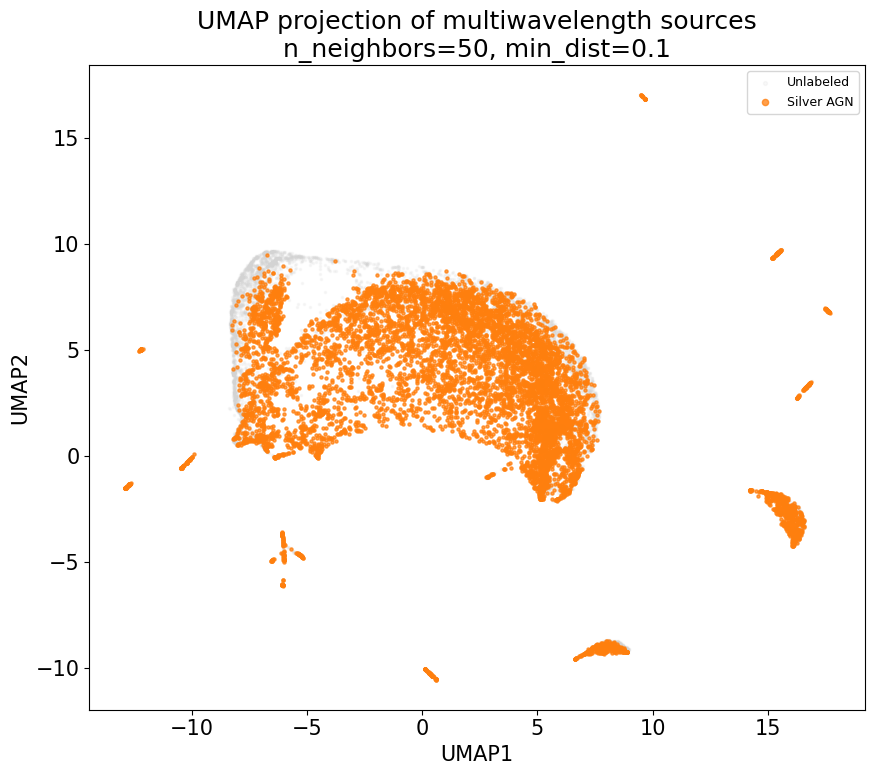

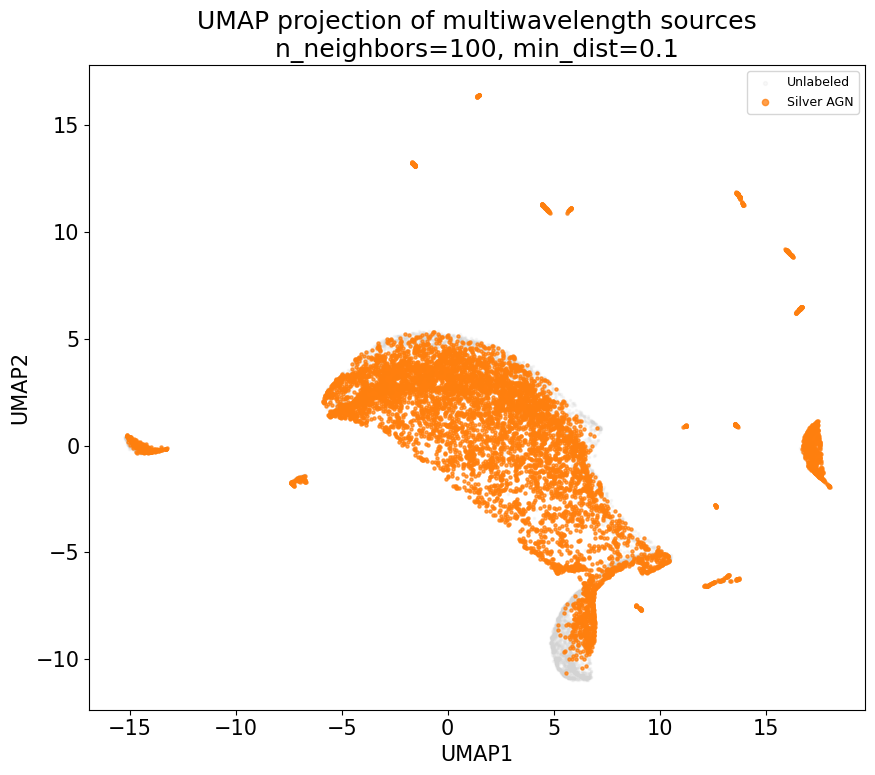

In [34]:
for n_neighbors in neighbors_list:
    plt.figure(figsize=(9, 8))
    result = umap_results[n_neighbors]

    mask_unlabeled = result["label_3class"] == -1
    mask_silver = result["label_3class"] == 1


    plt.scatter(
        result.loc[mask_unlabeled, "UMAP1"],
        result.loc[mask_unlabeled, "UMAP2"],
        s=2,
        alpha=0.15,
        color="lightgray",
        label="Unlabeled",
    )

    plt.scatter(
        result.loc[mask_silver, "UMAP1"],
        result.loc[mask_silver, "UMAP2"],
        s=5,
        alpha=0.75,
        color="tab:orange",
        label="Silver AGN",
    )

    plt.xlabel("UMAP1")
    plt.ylabel("UMAP2")

    plt.title(
        "UMAP projection of multiwavelength sources\n"
        f"n_neighbors={n_neighbors}, min_dist=0.1"
    )

    plt.legend(
        fontsize=9,
        markerscale=2,
    )

    plt.tight_layout()
    plt.show()

In [ ]:
print(type(X_pca))
print(X_pca.shape)

if isinstance(X_pca, pd.DataFrame):
    print(X_pca.columns.tolist())

<class 'pandas.DataFrame'>
(28632, 25)
['significance', 'flux_aper_b', 'flux_aper_lolim_b', 'flux_aper_hilim_b', 'flux_aper_h', 'flux_aper_lolim_h', 'flux_aper_hilim_h', 'flux_aper_s', 'flux_aper_lolim_s', 'flux_aper_hilim_s', 'flux_aper_m', 'flux_aper_lolim_m', 'flux_aper_hilim_m', 'combo_g', 'combo_r', 'combo_z_mag', 'WISE_w1mpro', 'WISE_w1snr', 'WISE_w2mpro', 'WISE_w2snr', 'WISE_w3mpro', 'WISE_w3snr', 'hard_hs', 'hard_hs_lolim', 'hard_hs_hilim']


# Data cleaning

In [35]:
X_features = X_pca.copy()
X_features = X_features.apply(
    pd.to_numeric,
    errors="coerce"
)

X_features = X_features.replace([np.inf, -np.inf], np.nan)

# Infinity -> NaN
X_features = X_features.replace([np.inf, -np.inf], np.nan)

# Missing photometry -> NaN
X_features = X_features.replace(-999, np.nan)

missing_indicators = (
    X_features.isna()
    .add_suffix("_missing")
    .astype("int8")
)

print("Shape:", X_features.shape)
print("Missing values:", X_features.isna().sum().sum())
print("Objects:", len(X_features))
print("Features:", X_features.shape[1])

Shape: (28632, 25)
Missing values: 3644
Objects: 28632
Features: 25


# Imputation

In [36]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_imputed_array = imputer.fit_transform(X_features)

X_imputed = pd.DataFrame(
    X_imputed_array,
    index=X_features.index,
    columns=X_features.columns,
)

assert len(X_imputed) == len(df_sample)
assert X_imputed.index.equals(df_sample.index)

print("Remaining missing values:", X_imputed.isna().sum().sum())

Remaining missing values: 0


In [37]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled_array = scaler.fit_transform(X_imputed)

X_scaled = pd.DataFrame(
    X_scaled_array,
    index=X_imputed.index,
    columns=X_imputed.columns,
)

print(X_scaled.shape)
print(X_scaled.mean().abs().mean(), X_scaled.std().mean())

(28632, 25)
1.336908293548062e-16 1.0000174634359322


# Cluster search with HDBSCAN 

In [38]:
import hdbscan
from sklearn.metrics import silhouette_score

hdbscan_configs = [
    {"min_cluster_size": 50,  "min_samples": 5},
    {"min_cluster_size": 50,  "min_samples": 10},
    {"min_cluster_size": 100, "min_samples": 10},
    {"min_cluster_size": 100, "min_samples": 20},
    {"min_cluster_size": 200, "min_samples": 10},
    {"min_cluster_size": 200, "min_samples": 20},
    {"min_cluster_size": 300, "min_samples": 20},
    {"min_cluster_size": 300, "min_samples": 30},
]

cluster_results = {}
summary_rows = []


# Grid search

for config in hdbscan_configs:

    mcs = config["min_cluster_size"]
    ms = config["min_samples"]

    key = f"mcs_{mcs}_ms_{ms}"

    print(f"Running {key}")

    clusterer = hdbscan.HDBSCAN(
        min_cluster_size=mcs,
        min_samples=ms,
        metric="euclidean",
        cluster_selection_method="eom",
        prediction_data=True,
        core_dist_n_jobs=-1,
    )

    labels = clusterer.fit_predict(X_scaled)

    valid_mask = labels != -1
    n_valid = valid_mask.sum()

    n_clusters = len(set(labels) - {-1})
    noise_fraction = (labels == -1).mean()

    cluster_counts = (
        pd.Series(labels[valid_mask])
        .value_counts()
        .sort_index()
    )

    largest_cluster_fraction = (
        cluster_counts.max() / n_valid
        if n_valid > 0
        else np.nan
    )

    smallest_cluster_size = (
        cluster_counts.min()
        if not cluster_counts.empty
        else np.nan
    )

    median_cluster_size = (
        cluster_counts.median()
        if not cluster_counts.empty
        else np.nan
    )

    if n_clusters >= 2 and n_valid > n_clusters:
        silhouette = silhouette_score(
            X_scaled.loc[valid_mask],
            labels[valid_mask],
            sample_size=min(10_000, n_valid),
            random_state=42,
        )
    else:
        silhouette = np.nan

    cluster_results[key] = {
        "model": clusterer,
        "labels": labels,
        "probabilities": clusterer.probabilities_,
        "cluster_counts": cluster_counts,
    }

    summary_rows.append({
        "configuration": key,
        "min_cluster_size": mcs,
        "min_samples": ms,
        "n_clusters": n_clusters,
        "noise_fraction": noise_fraction,
        "largest_cluster_fraction": largest_cluster_fraction,
        "smallest_cluster_size": smallest_cluster_size,
        "median_cluster_size": median_cluster_size,
        "silhouette": silhouette,
    })

Running mcs_50_ms_5
Running mcs_50_ms_10
Running mcs_100_ms_10
Running mcs_100_ms_20
Running mcs_200_ms_10
Running mcs_200_ms_20
Running mcs_300_ms_20
Running mcs_300_ms_30


In [60]:
for key in cluster_results:
    print(key)
    print(cluster_results[key]["cluster_counts"])
    print()

mcs_50_ms_5
0       67
1      221
2       60
3       77
4       95
5      133
6    27812
Name: count, dtype: int64

mcs_50_ms_10
0       57
1       65
2      209
3       94
4       77
5      128
6    27750
Name: count, dtype: int64

mcs_100_ms_10
0      274
1      128
2    27750
Name: count, dtype: int64

mcs_100_ms_20
0      233
1    27711
2      124
Name: count, dtype: int64

mcs_200_ms_10
0      274
1    28125
Name: count, dtype: int64

mcs_200_ms_20
0      233
1    27988
Name: count, dtype: int64

mcs_300_ms_20
0    18295
1     2492
Name: count, dtype: int64

mcs_300_ms_30
0     1981
1    14977
Name: count, dtype: int64



In [42]:
cluster_summary = pd.DataFrame(summary_rows)

cluster_summary = cluster_summary.sort_values(["silhouette", "largest_cluster_fraction", "noise_fraction",],
                                            ascending=[False, True, True]).reset_index(drop=True)

display(cluster_summary)

,configuration,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_fraction,smallest_cluster_size,median_cluster_size,silhouette
0,mcs_200_ms_20,200,20,2,0.014355,0.991744,233,14110.5,0.629866
1,mcs_200_ms_10,200,10,2,0.008138,0.990352,274,14199.5,0.624512
2,mcs_300_ms_30,300,30,2,0.407726,0.883182,1981,8479.0,0.583062
3,mcs_300_ms_20,300,20,2,0.273994,0.880117,2492,10393.5,0.533597
4,mcs_50_ms_10,50,10,7,0.008801,0.977801,57,94.0,0.451685
5,mcs_100_ms_10,100,10,3,0.016764,0.985720,128,274.0,0.450229
6,mcs_100_ms_20,100,20,3,0.019698,0.987281,124,233.0,0.450145
7,mcs_50_ms_5,50,5,7,0.005833,0.977060,60,95.0,0.449245


# Picking configuration

In [68]:
best_key = "mcs_50_ms_10"

cluster_labels = cluster_results[best_key]["labels"]
cluster_probabilities = cluster_results[best_key]["probabilities"]

df_clusters = df_sample.copy()

df_clusters["cluster"] = cluster_labels
df_clusters["cluster_probability"] = cluster_probabilities

print(df_clusters["cluster"].value_counts().sort_index())
print("Noise fraction:", (df_clusters["cluster"] == -1).mean())

display(
    pd.crosstab(
        df_clusters["cluster"],
        df_clusters["label_3class"],
        normalize="index",
    ).round(3)
)

features_with_clusters = X_features.copy()
features_with_clusters["cluster"] = cluster_labels

display(
    features_with_clusters
    .groupby("cluster")
    .median()
)

cluster
-1      252
 0       57
 1       65
 2      209
 3       94
 4       77
 5      128
 6    27750
Name: count, dtype: int64
Noise fraction: 0.008801341156747695


label_3class,-1,0,1,2
cluster,,,,
-1,0.131,0.000,0.528,0.341
0,0.333,0.000,0.632,0.035
1,0.492,0.000,0.400,0.108
2,0.651,0.010,0.268,0.072
3,0.457,0.000,0.500,0.043
4,0.442,0.000,0.429,0.130
5,0.422,0.016,0.469,0.094
6,0.211,0.034,0.292,0.463


,significance,flux_aper_b,flux_aper_lolim_b,flux_aper_hilim_b,flux_aper_h,flux_aper_lolim_h,flux_aper_hilim_h,flux_aper_s,flux_aper_lolim_s,flux_aper_hilim_s,...,combo_z_mag,WISE_w1mpro,WISE_w1snr,WISE_w2mpro,WISE_w2snr,WISE_w3mpro,WISE_w3snr,hard_hs,hard_hs_lolim,hard_hs_hilim
cluster,,,,,,,,,,,,,,,,,,,,,
-1,43.480216,9.582308e-13,9.419442e-13,9.872342e-13,4.104127e-13,3.770917e-13,4.368410e-13,1.417633e-13,1.327790e-13,1.523941e-13,...,13.802200,9.2075,44.05,8.9910,50.95,7.377,57.65,-0.234853,-0.247970,-0.195503
0,5.942061,1.964674e-14,1.504758e-14,2.553274e-14,1.480955e-14,9.873033e-15,1.974607e-14,1.750735e-15,1.095195e-15,2.161401e-15,...,20.705410,15.9560,20.00,14.9650,15.00,11.744,4.50,0.111181,-0.156777,0.321674
1,6.137174,3.259156e-14,2.456243e-14,3.820983e-14,1.218214e-14,8.118408e-15,1.958004e-14,5.925075e-15,4.105072e-15,9.135242e-15,...,-9.000000,15.1220,29.90,14.4350,20.70,11.519,5.30,-0.212367,-0.386633,-0.015615
2,6.091240,2.158494e-14,1.647043e-14,2.770068e-14,1.046852e-14,5.957579e-15,1.525762e-14,4.122665e-15,2.810584e-15,5.850656e-15,...,-9.000000,12.0400,46.50,11.9450,49.90,10.216,18.10,-0.238601,-0.449094,-0.003123
3,5.366126,2.164071e-14,1.528258e-14,2.663178e-14,1.222721e-14,8.356930e-15,1.878136e-14,3.060027e-15,1.072484e-15,4.806729e-15,...,20.630620,15.3510,30.95,14.6355,26.50,11.866,5.75,-0.007495,-0.207995,0.201124
4,6.800203,2.853923e-14,2.142722e-14,3.414050e-14,1.876889e-14,1.290262e-14,2.580722e-14,4.855854e-15,2.792559e-15,7.241478e-15,...,-9.000000,15.0280,33.80,14.1480,30.80,11.500,7.70,-0.037477,-0.210493,0.186758
5,6.554955,2.185367e-14,1.578641e-14,2.780078e-14,1.161029e-14,7.074323e-15,1.691508e-14,4.907170e-15,3.412827e-15,6.181207e-15,...,-9.000000,14.9285,33.90,14.2905,28.20,11.571,7.05,-0.187383,-0.366021,-0.046221
6,6.146750,3.036875e-14,2.354874e-14,3.703829e-14,1.759236e-14,1.107728e-14,2.424021e-14,6.053675e-15,3.767508e-15,8.722720e-15,...,19.334801,15.2840,29.80,14.4015,23.60,11.506,6.30,-0.224859,-0.396627,-0.033104


In [69]:
assert len(df_clusters) == len(X_features)
assert df_clusters.index.equals(X_features.index)

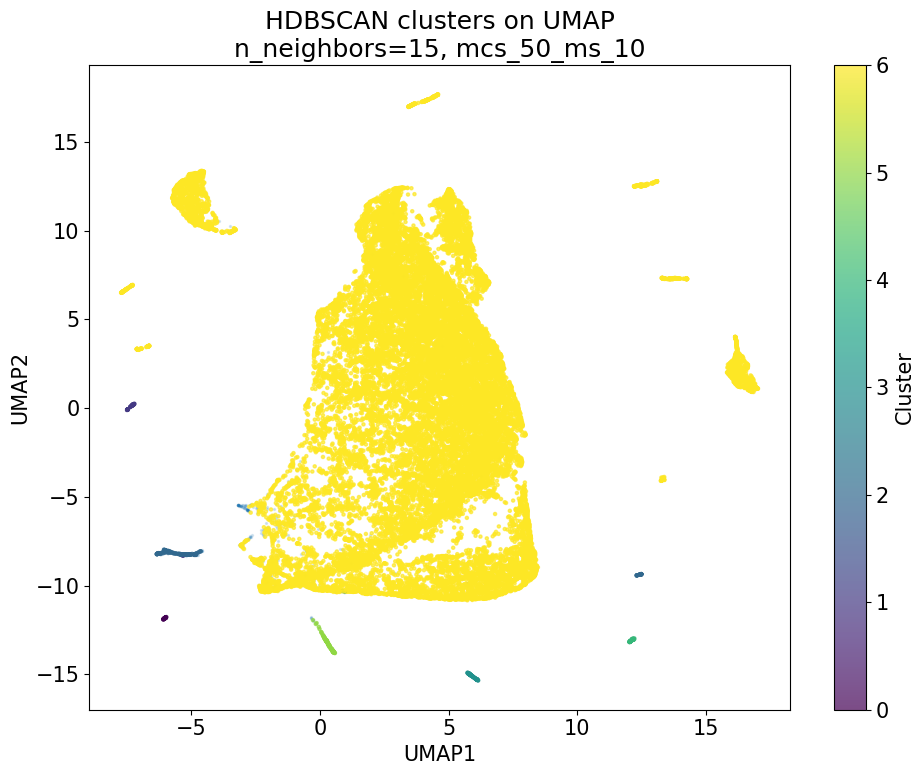

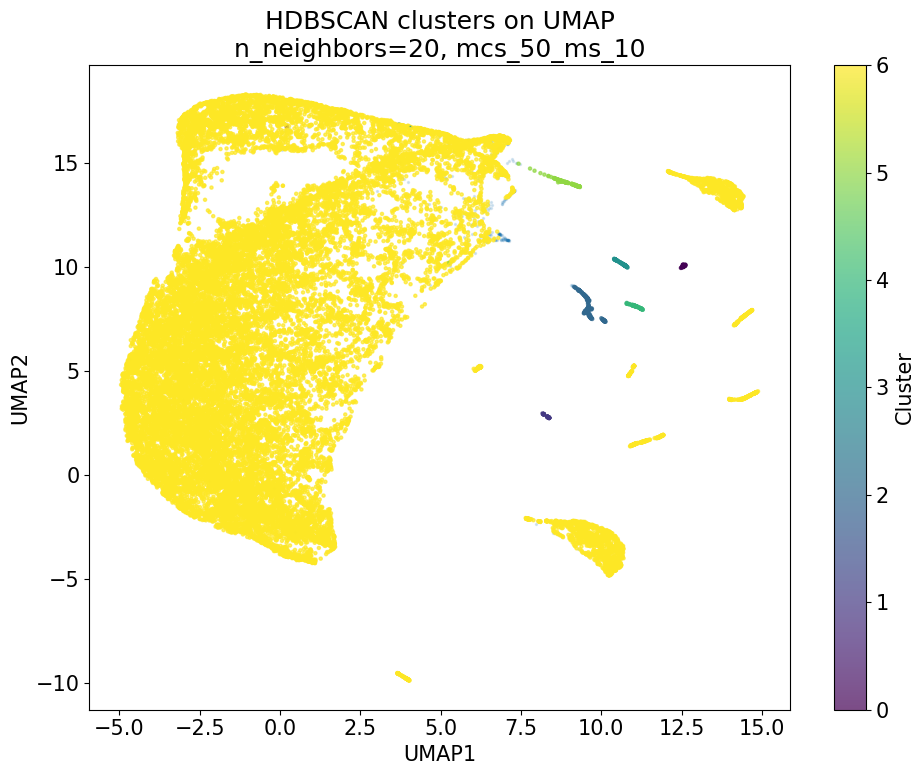

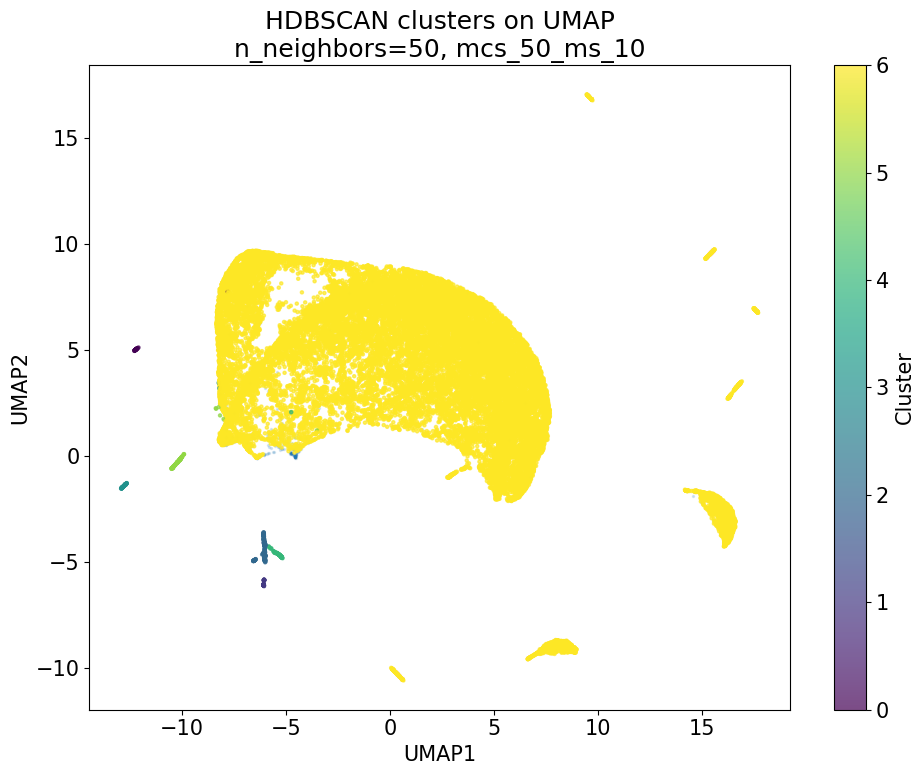

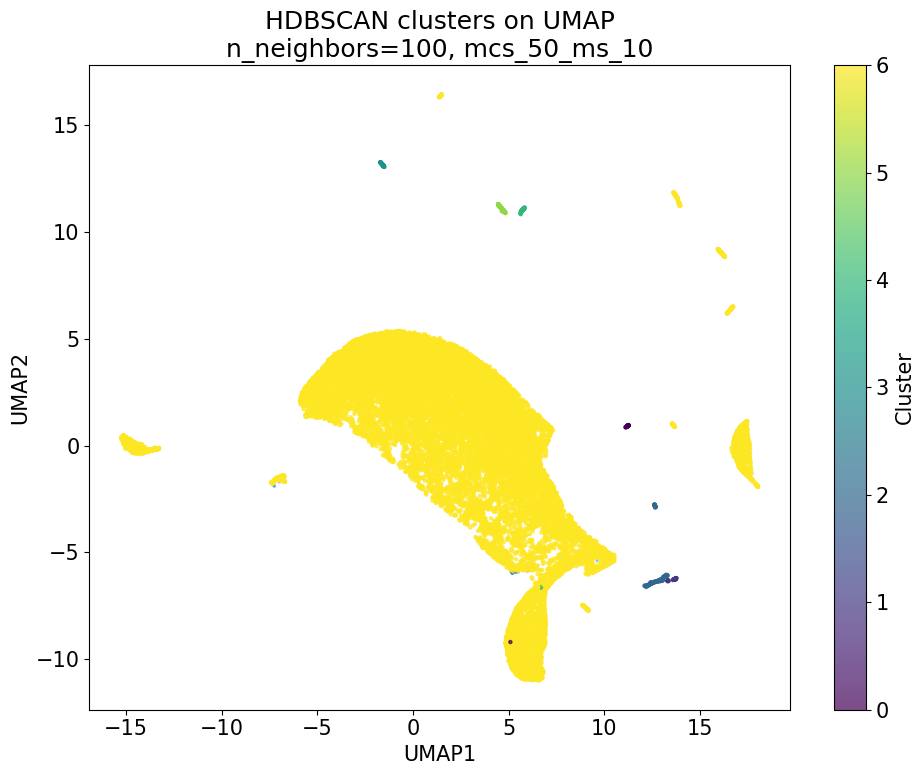

In [88]:
for n_neighbors in neighbors_list:
    result = umap_results[n_neighbors].copy()

    assert len(result) == len(cluster_labels)

    result["cluster"] = cluster_labels
    result["cluster_probability"] = cluster_probabilities

    noise_mask = result["cluster"] == -1

    plt.figure(figsize=(10, 8))

    plt.scatter(
        result.loc[noise_mask, "UMAP1"],
        result.loc[noise_mask, "UMAP2"],
        s=2,
        alpha=0.15,
        label="Noise",
    )

    scatter = plt.scatter(
        result.loc[~noise_mask, "UMAP1"],
        result.loc[~noise_mask, "UMAP2"],
        c=result.loc[~noise_mask, "cluster"],
        s=5,
        alpha=0.7,
    )

    plt.xlabel("UMAP1")
    plt.ylabel("UMAP2")

    plt.title(
        f"HDBSCAN clusters on UMAP\n"
        f"n_neighbors={n_neighbors}, {best_key}"
    )

    plt.colorbar(
        scatter,
        label="Cluster"
    )

    plt.tight_layout()
    plt.show()

In [71]:
cluster_sizes = (
    df_clusters
    .groupby("cluster")
    .agg(
        size=("cluster", "size"),
        mean_probability=(
            "cluster_probability",
            "mean"
        ),
        median_probability=(
            "cluster_probability",
            "median"
        ),
    )
    .sort_values(
        "size",
        ascending=False
    )
)

display(cluster_sizes)

,size,mean_probability,median_probability
cluster,,,
6,27750,0.897516,1.000000
-1,252,0.000000,0.000000
2,209,0.754318,0.831464
5,128,0.860270,0.865868
3,94,0.891383,1.000000
4,77,0.904891,1.000000
1,65,0.953755,1.000000
0,57,0.979764,1.000000


In [72]:
cluster_label_counts = pd.crosstab(
    df_clusters["cluster"],
    df_clusters["label_3class"],
)

display(cluster_label_counts)

label_3class,-1,0,1,2
cluster,,,,
-1,33,0,133,86
0,19,0,36,2
1,32,0,26,7
2,136,2,56,15
3,43,0,47,4
4,34,0,33,10
5,54,2,60,12
6,5855,930,8106,12859


In [73]:
cluster_label_fractions = pd.crosstab(
    df_clusters["cluster"],
    df_clusters["label_3class"],
    normalize="index",
).round(3)

display(cluster_label_fractions)

label_3class,-1,0,1,2
cluster,,,,
-1,0.131,0.000,0.528,0.341
0,0.333,0.000,0.632,0.035
1,0.492,0.000,0.400,0.108
2,0.651,0.010,0.268,0.072
3,0.457,0.000,0.500,0.043
4,0.442,0.000,0.429,0.130
5,0.422,0.016,0.469,0.094
6,0.211,0.034,0.292,0.463


In [74]:
features_with_clusters = X_features.copy()
features_with_clusters["cluster"] = cluster_labels

cluster_medians = (
    features_with_clusters
    .query("cluster != -1")
    .groupby("cluster")
    .median()
)

display(cluster_medians)

,significance,flux_aper_b,flux_aper_lolim_b,flux_aper_hilim_b,flux_aper_h,flux_aper_lolim_h,flux_aper_hilim_h,flux_aper_s,flux_aper_lolim_s,flux_aper_hilim_s,...,combo_z_mag,WISE_w1mpro,WISE_w1snr,WISE_w2mpro,WISE_w2snr,WISE_w3mpro,WISE_w3snr,hard_hs,hard_hs_lolim,hard_hs_hilim
cluster,,,,,,,,,,,,,,,,,,,,,
0,5.942061,1.964674e-14,1.504758e-14,2.553274e-14,1.480955e-14,9.873033e-15,1.974607e-14,1.750735e-15,1.095195e-15,2.161401e-15,...,20.705410,15.9560,20.00,14.9650,15.0,11.744,4.50,0.111181,-0.156777,0.321674
1,6.137174,3.259156e-14,2.456243e-14,3.820983e-14,1.218214e-14,8.118408e-15,1.958004e-14,5.925075e-15,4.105072e-15,9.135242e-15,...,-9.000000,15.1220,29.90,14.4350,20.7,11.519,5.30,-0.212367,-0.386633,-0.015615
2,6.091240,2.158494e-14,1.647043e-14,2.770068e-14,1.046852e-14,5.957579e-15,1.525762e-14,4.122665e-15,2.810584e-15,5.850656e-15,...,-9.000000,12.0400,46.50,11.9450,49.9,10.216,18.10,-0.238601,-0.449094,-0.003123
3,5.366126,2.164071e-14,1.528258e-14,2.663178e-14,1.222721e-14,8.356930e-15,1.878136e-14,3.060027e-15,1.072484e-15,4.806729e-15,...,20.630620,15.3510,30.95,14.6355,26.5,11.866,5.75,-0.007495,-0.207995,0.201124
4,6.800203,2.853923e-14,2.142722e-14,3.414050e-14,1.876889e-14,1.290262e-14,2.580722e-14,4.855854e-15,2.792559e-15,7.241478e-15,...,-9.000000,15.0280,33.80,14.1480,30.8,11.500,7.70,-0.037477,-0.210493,0.186758
5,6.554955,2.185367e-14,1.578641e-14,2.780078e-14,1.161029e-14,7.074323e-15,1.691508e-14,4.907170e-15,3.412827e-15,6.181207e-15,...,-9.000000,14.9285,33.90,14.2905,28.2,11.571,7.05,-0.187383,-0.366021,-0.046221
6,6.146750,3.036875e-14,2.354874e-14,3.703829e-14,1.759236e-14,1.107728e-14,2.424021e-14,6.053675e-15,3.767508e-15,8.722720e-15,...,19.334801,15.2840,29.80,14.4015,23.6,11.506,6.30,-0.224859,-0.396627,-0.033104


In [75]:
overall_median = X_features.median()

overall_iqr = (
    X_features.quantile(0.75)
    - X_features.quantile(0.25)
).replace(0, np.nan)

cluster_medians = (
    X_features
    .assign(cluster=cluster_labels)
    .query("cluster != -1")
    .groupby("cluster")
    .median()
)

cluster_profiles = (
    cluster_medians - overall_median
) / overall_iqr

display(cluster_profiles.round(2))

,significance,flux_aper_b,flux_aper_lolim_b,flux_aper_hilim_b,flux_aper_h,flux_aper_lolim_h,flux_aper_hilim_h,flux_aper_s,flux_aper_lolim_s,flux_aper_hilim_s,...,combo_z_mag,WISE_w1mpro,WISE_w1snr,WISE_w2mpro,WISE_w2snr,WISE_w3mpro,WISE_w3snr,hard_hs,hard_hs_lolim,hard_hs_hilim
cluster,,,,,,,,,,,,,,,,,,,,,
0,-0.04,-0.18,-0.17,-0.17,-0.08,-0.05,-0.10,-0.25,-0.20,-0.31,...,0.56,0.32,-0.54,0.29,-0.38,0.18,-0.20,0.55,0.42,0.52
1,-0.01,0.03,0.02,0.01,-0.15,-0.11,-0.11,-0.01,0.02,0.02,...,-11.22,-0.07,-0.01,0.03,-0.14,0.02,-0.11,0.02,0.01,0.02
2,-0.02,-0.15,-0.14,-0.14,-0.20,-0.19,-0.20,-0.11,-0.07,-0.14,...,-11.22,-1.51,0.90,-1.23,1.14,-0.94,1.34,-0.03,-0.10,0.04
3,-0.14,-0.15,-0.16,-0.15,-0.15,-0.10,-0.12,-0.17,-0.20,-0.19,...,0.53,0.04,0.05,0.13,0.12,0.27,-0.06,0.36,0.33,0.34
4,0.11,-0.03,-0.04,-0.04,0.03,0.06,0.03,-0.07,-0.08,-0.07,...,-11.22,-0.11,0.21,-0.12,0.31,0.01,0.16,0.31,0.33,0.32
5,0.06,-0.14,-0.15,-0.14,-0.17,-0.15,-0.17,-0.07,-0.03,-0.12,...,-11.22,-0.16,0.21,-0.05,0.19,0.06,0.09,0.06,0.05,-0.02
6,-0.01,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,-0.00,...,0.02,0.01,-0.01,0.01,-0.01,0.01,0.00,-0.00,-0.00,-0.00


# Classifiers for SHAP

In [76]:
valid_mask = cluster_labels != -1

X_cluster = X_imputed.loc[valid_mask].copy()

y_cluster = pd.Series(
    cluster_labels[valid_mask],
    index=X_cluster.index,
    name="cluster",
)

print("X_cluster:", X_cluster.shape)
print("Cluster sizes:")
print(y_cluster.value_counts().sort_index())

X_cluster: (28380, 25)
Cluster sizes:
cluster
0       57
1       65
2      209
3       94
4       77
5      128
6    27750
Name: count, dtype: int64


In [77]:
minimum_model_cluster_size = 100

cluster_counts = y_cluster.value_counts()

clusters_to_keep = cluster_counts[
    cluster_counts >= minimum_model_cluster_size
].index

model_mask = y_cluster.isin(clusters_to_keep)

X_cluster_model = X_cluster.loc[model_mask].copy()
y_cluster_model = y_cluster.loc[model_mask].copy()

print(y_cluster_model.value_counts().sort_index())

cluster
2      209
5      128
6    27750
Name: count, dtype: int64


In [78]:
# Train/test split for model training
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_cluster_model,
    y_cluster_model,
    test_size=0.25,
    stratify=y_cluster_model,
    random_state=42,
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (21065, 25)
Test: (7022, 25)


In [79]:
print("All classes:")
print(pd.Series(y_cluster_model).value_counts().sort_index())

print("\nTrain classes:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nUnique train classes:", np.unique(y_train))

All classes:
cluster
2      209
5      128
6    27750
Name: count, dtype: int64

Train classes:
cluster
2      157
5       96
6    20812
Name: count, dtype: int64

Unique train classes: [2 5 6]


In [ ]:
# Classifier 
from lightgbm import LGBMClassifier

# num_class must be set explicitly for objective="multiclass" -- the sklearn wrapper
# only auto-infers it when objective is left unset, so this keeps the cell robust to
# any HDBSCAN config that changes how many clusters survive the minimum_model_cluster_size filter.
num_class = len(np.unique(y_train))

cluster_model = LGBMClassifier(
    objective="multiclass",
    num_class=num_class,
    n_estimators=600,
    learning_rate=0.04,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=30,
    subsample=0.85,
    subsample_freq=1,
    colsample_bytree=0.85,
    reg_lambda=2.0,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

cluster_model.fit(
    X_train,
    y_train
)

In [83]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
)

y_pred = cluster_model.predict(X_test)

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0,
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           2       1.00      1.00      1.00        52
           5       1.00      1.00      1.00        32
           6       1.00      1.00      1.00      6938

    accuracy                           1.00      7022
   macro avg       1.00      1.00      1.00      7022
weighted avg       1.00      1.00      1.00      7022

Balanced accuracy: 1.0


In [84]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
)

y_pred = cluster_model.predict(X_test)

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0,
    )
)

print(
    "Balanced accuracy:",
    balanced_accuracy_score(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           2       1.00      1.00      1.00        52
           5       1.00      1.00      1.00        32
           6       1.00      1.00      1.00      6938

    accuracy                           1.00      7022
   macro avg       1.00      1.00      1.00      7022
weighted avg       1.00      1.00      1.00      7022

Balanced accuracy: 1.0


In [85]:
import shap

X_shap = X_test.sample(
    n=min(5000, len(X_test)),
    random_state=42,
)

explainer = shap.TreeExplainer(cluster_model)
shap_values = explainer(X_shap)

print("SHAP shape:", shap_values.values.shape)
print("Classes:", cluster_model.classes_)

print(shap_values.values.shape)
print(shap_values.base_values.shape)

SHAP shape: (5000, 25, 3)
Classes: [2 5 6]
(5000, 25, 3)
(5000, 3)


In [86]:
values = shap_values.values

if values.ndim == 3:
    global_importance = np.abs(
        values
    ).mean(axis=(0, 2))

elif values.ndim == 2:
    global_importance = np.abs(
        values
    ).mean(axis=0)

else:
    raise ValueError(
        f"Unexpected SHAP shape: {values.shape}"
    )

In [87]:
global_shap_importance = (
    pd.DataFrame({
        "feature": X_shap.columns,
        "mean_abs_shap": global_importance,
    })
    .sort_values(
        "mean_abs_shap",
        ascending=False,
    )
)

display(global_shap_importance.head(25))

,feature,mean_abs_shap
15,combo_z_mag,0.116710
13,combo_g,0.102588
12,flux_aper_hilim_m,0.028770
14,combo_r,0.028207
16,WISE_w1mpro,0.025580
20,WISE_w3mpro,0.024510
0,significance,0.019206
21,WISE_w3snr,0.017741
9,flux_aper_hilim_s,0.017355
17,WISE_w1snr,0.014871


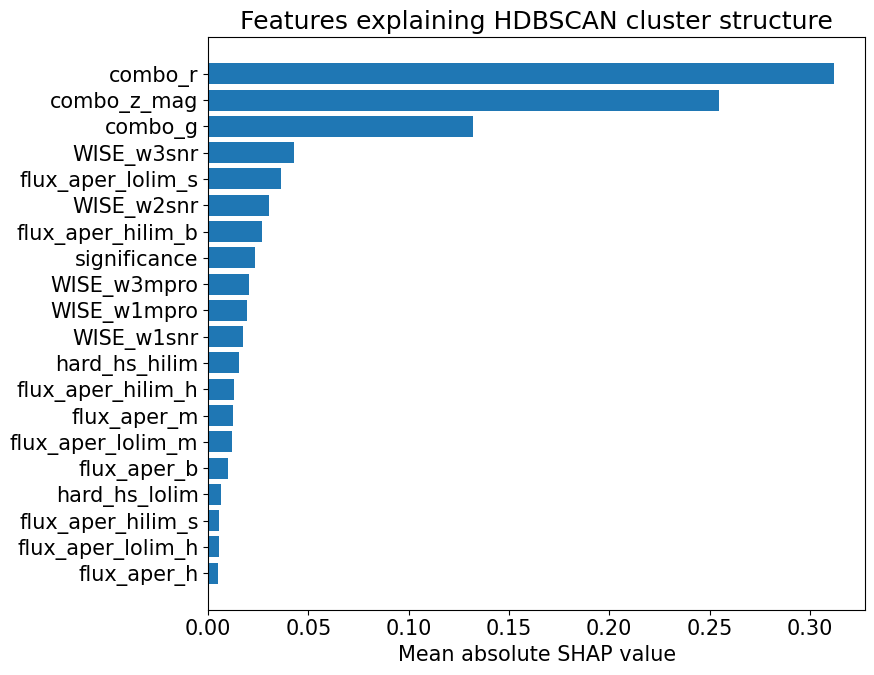

In [67]:
top_global = (
    global_shap_importance
    .head(20)
    .sort_values("mean_abs_shap")
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_global["feature"],
    top_global["mean_abs_shap"],
)

plt.xlabel("Mean absolute SHAP value")
plt.title(
    "Features explaining HDBSCAN cluster structure"
)

plt.tight_layout()
plt.show()

,feature,mean_abs_shap
0,combo_r,0.226707
1,combo_z_mag,0.194210
2,combo_g,0.078038
3,WISE_w2snr,0.077021
4,WISE_w3snr,0.025958
5,significance,0.022215
6,flux_aper_h,0.021970
7,flux_aper_hilim_h,0.021844
8,WISE_w1mpro,0.017207
9,WISE_w3mpro,0.012808


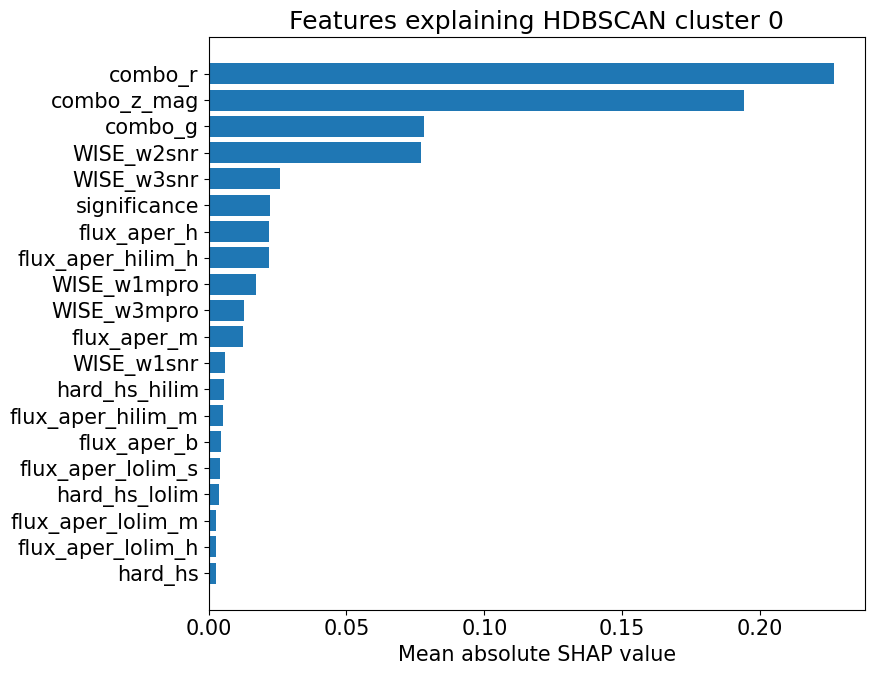

Target cluster: 0


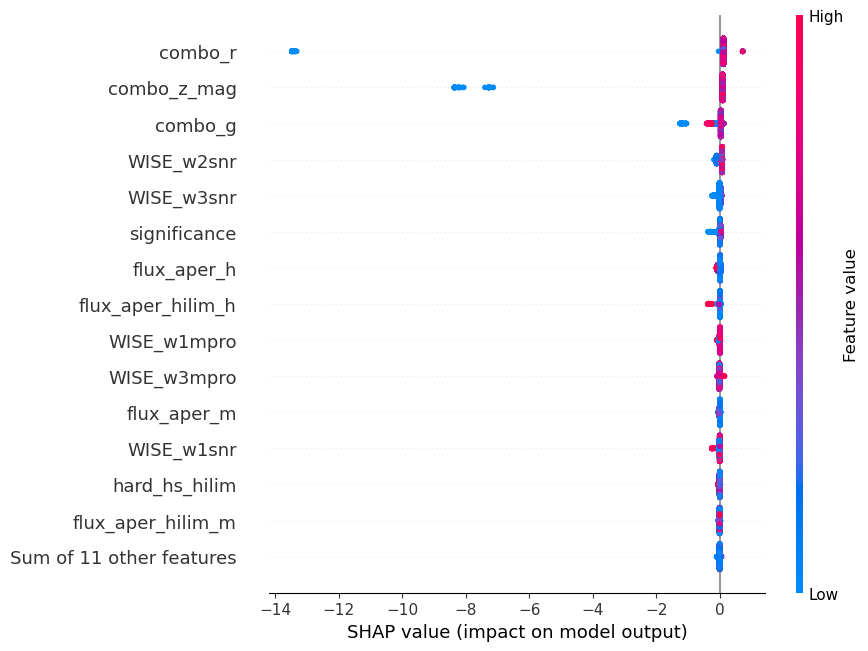

In [101]:
# Global SHAP importance table
target_cluster = 0

global_shap_importance = (
    pd.DataFrame({
        "feature": X_shap.columns,
        "mean_abs_shap": np.abs(
            shap_values.values
        ).mean(axis=0),
    })
    .sort_values(
        "mean_abs_shap",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(global_shap_importance.head(20))


# Bar plot
top_global = (
    global_shap_importance
    .head(20)
    .sort_values("mean_abs_shap")
)

plt.figure(figsize=(9, 7))

plt.barh(
    top_global["feature"],
    top_global["mean_abs_shap"],
)

plt.xlabel("Mean absolute SHAP value")
plt.title(
    f"Features explaining HDBSCAN cluster {target_cluster}"
)

plt.tight_layout()
plt.show()


# Beeswarm plot
print(f"Target cluster: {target_cluster}")

shap.plots.beeswarm(
    shap_values,
    max_display=15,
)

In [99]:
cluster_shap_table = (
    pd.DataFrame({
        "feature": X_shap.columns,
        "mean_abs_shap": np.abs(
            shap_values.values
        ).mean(axis=0),
    })
    .sort_values(
        "mean_abs_shap",
        ascending=False,
    )
    .reset_index(drop=True)
)

print(f"Top features for cluster {target_cluster}")

display(
    cluster_shap_table.head(10)
)

Top features for cluster 0


,feature,mean_abs_shap
0,combo_r,0.226707
1,combo_z_mag,0.194210
2,combo_g,0.078038
3,WISE_w2snr,0.077021
4,WISE_w3snr,0.025958
5,significance,0.022215
6,flux_aper_h,0.021970
7,flux_aper_hilim_h,0.021844
8,WISE_w1mpro,0.017207
9,WISE_w3mpro,0.012808


# PaCMAP

In [71]:
import pacmap
import matplotlib.pyplot as plt

neighbors_list = [15, 20, 50, 100]

pacmap_results = {}
pacmap_embeddings = {}

for n_neighbors in neighbors_list:
    print(f"Running PaCMAP: n_neighbors={n_neighbors}")

    reducer = pacmap.PaCMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        MN_ratio=0.5,
        FP_ratio=2.0,
        random_state=42,
    )

    embedding = reducer.fit_transform(
        X_pca,
        init="pca"
    )

    result = df_sample.copy()
    result["PaCMAP1"] = embedding[:, 0]
    result["PaCMAP2"] = embedding[:, 1]

    pacmap_embeddings[n_neighbors] = embedding
    pacmap_results[n_neighbors] = result

    print("Shape:", embedding.shape)

Running PaCMAP: n_neighbors=15


Shape: (28632, 2)
Running PaCMAP: n_neighbors=20


Shape: (28632, 2)
Running PaCMAP: n_neighbors=50


Shape: (28632, 2)
Running PaCMAP: n_neighbors=100
Shape: (28632, 2)


# Common Plots

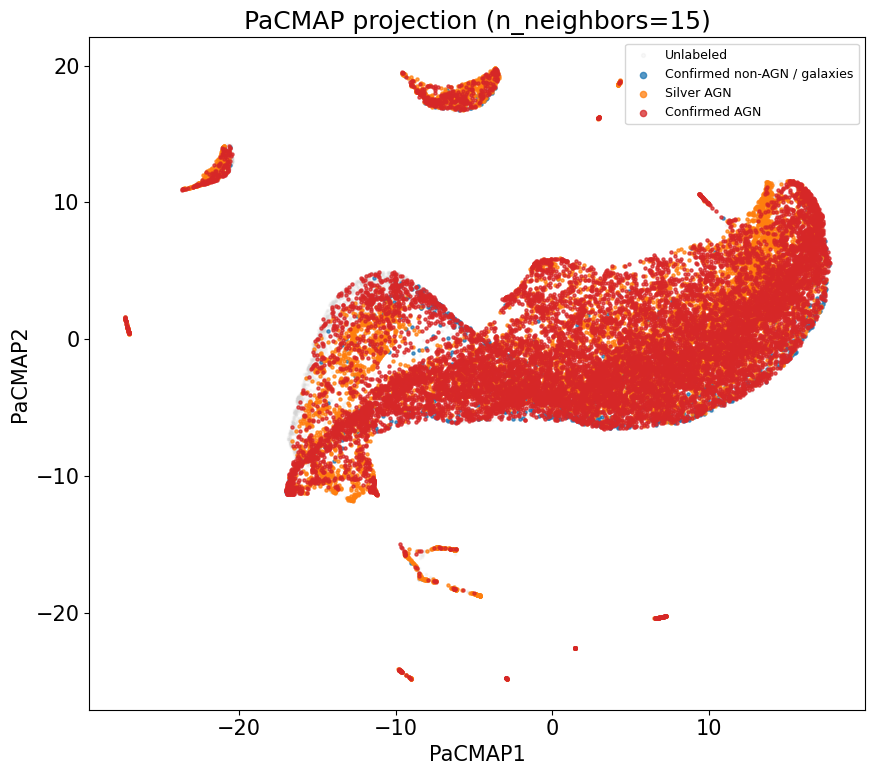

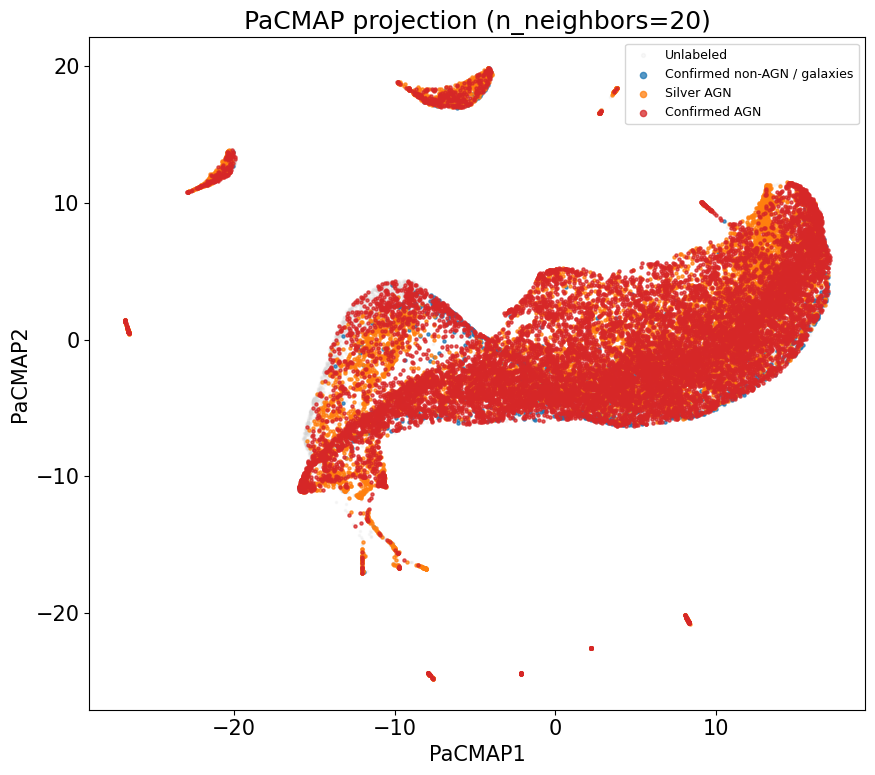

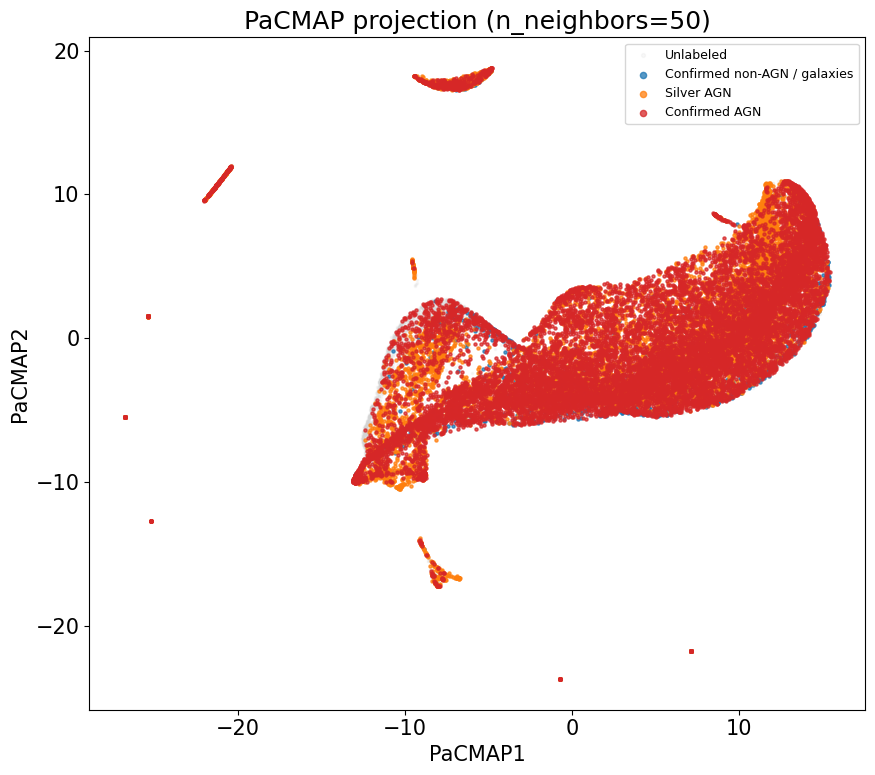

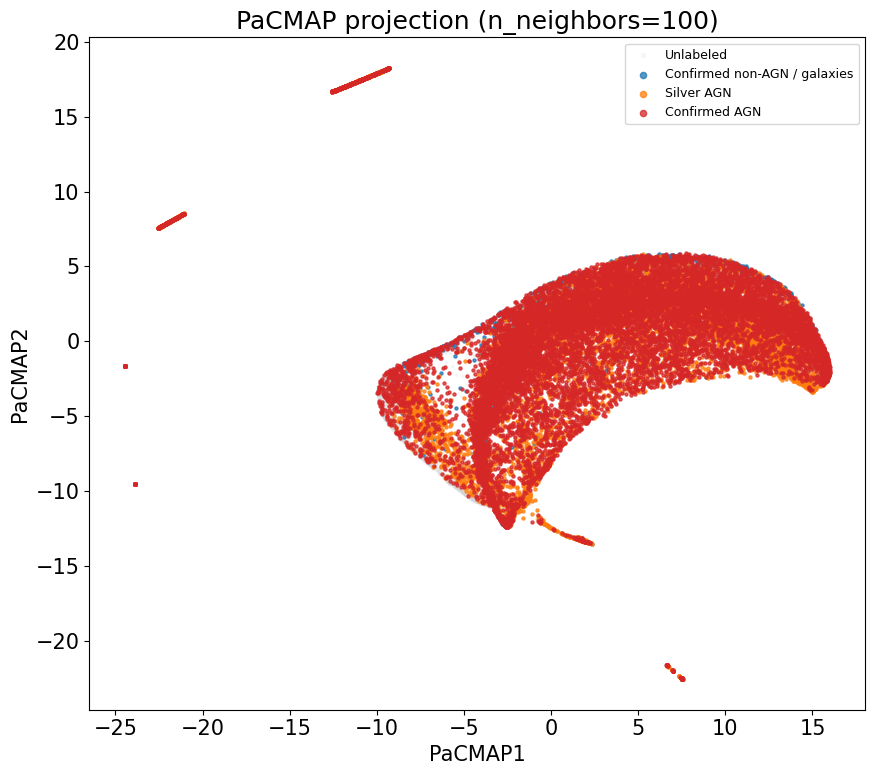

In [76]:
for n_neighbors in neighbors_list:
    result = pacmap_results[n_neighbors]

    mask_agn = result["label_3class"] == 2
    mask_nonagn = (result["label_3class"] == 0)
    mask_unlabeled = result["label_3class"] == -1
    mask_silver = result["label_3class"] == 1
    

    plt.figure(figsize=(9, 8))

    plt.scatter(
        result.loc[mask_unlabeled, "PaCMAP1"],
        result.loc[mask_unlabeled, "PaCMAP2"],
        s=2,
        alpha=0.15,
        color="lightgray",
        label="Unlabeled",
    )

    plt.scatter(
        result.loc[mask_nonagn, "PaCMAP1"],
        result.loc[mask_nonagn, "PaCMAP2"],
        s=5,
        alpha=0.75,
        color="tab:blue",
        label="Confirmed non-AGN / galaxies",
    )

    plt.scatter(
        result.loc[mask_silver, "PaCMAP1"],
        result.loc[mask_silver, "PaCMAP2"],
        s=5,
        alpha=0.75,
        color="tab:orange",
        label="Silver AGN",
    )

    plt.scatter(
        result.loc[mask_agn, "PaCMAP1"],
        result.loc[mask_agn, "PaCMAP2"],
        s=5,
        alpha=0.75,
        color="tab:red",
        label="Confirmed AGN",
    )

    plt.xlabel("PaCMAP1")
    plt.ylabel("PaCMAP2")

    plt.title(
        f"PaCMAP projection (n_neighbors={n_neighbors})"
    )

    plt.legend(
        fontsize=9,
        markerscale=2,
    )

    plt.tight_layout()
    plt.show()

# Individual Plots (AGNs, galaxies, silver sample)

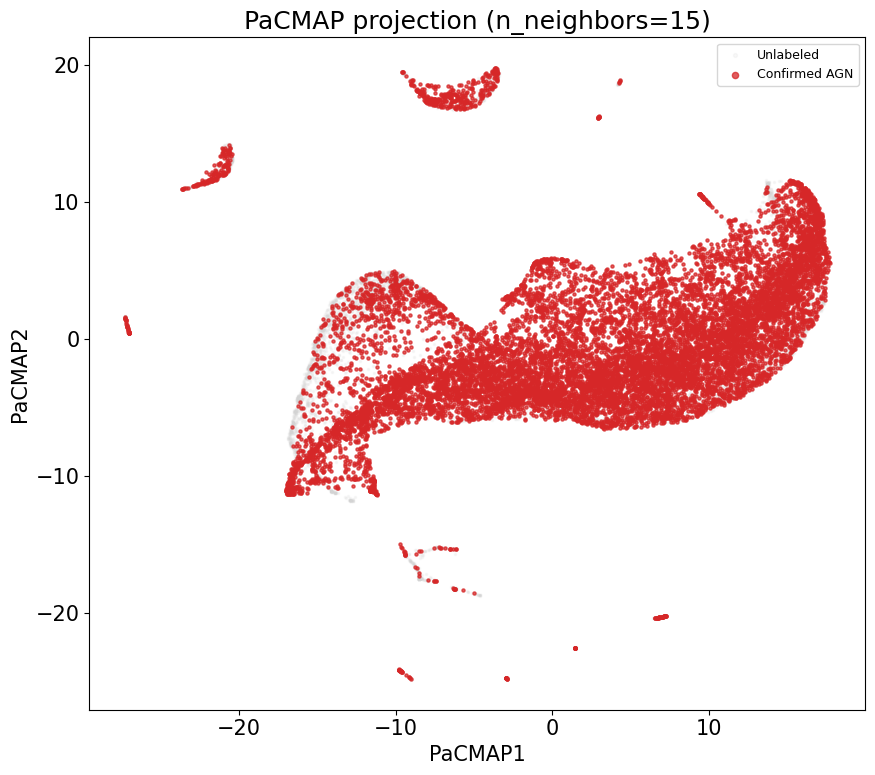

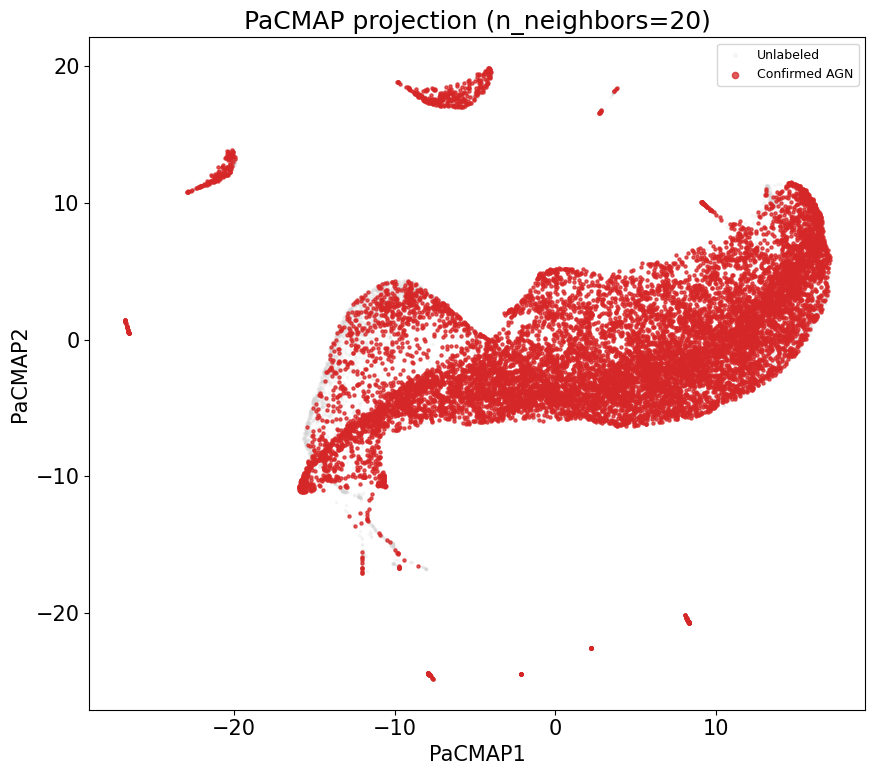

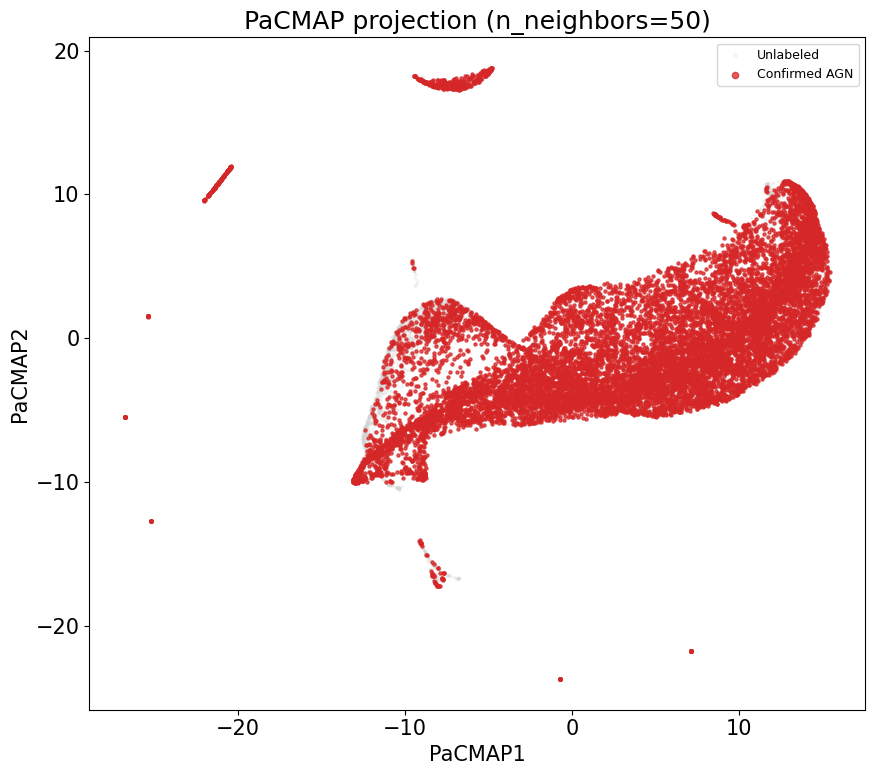

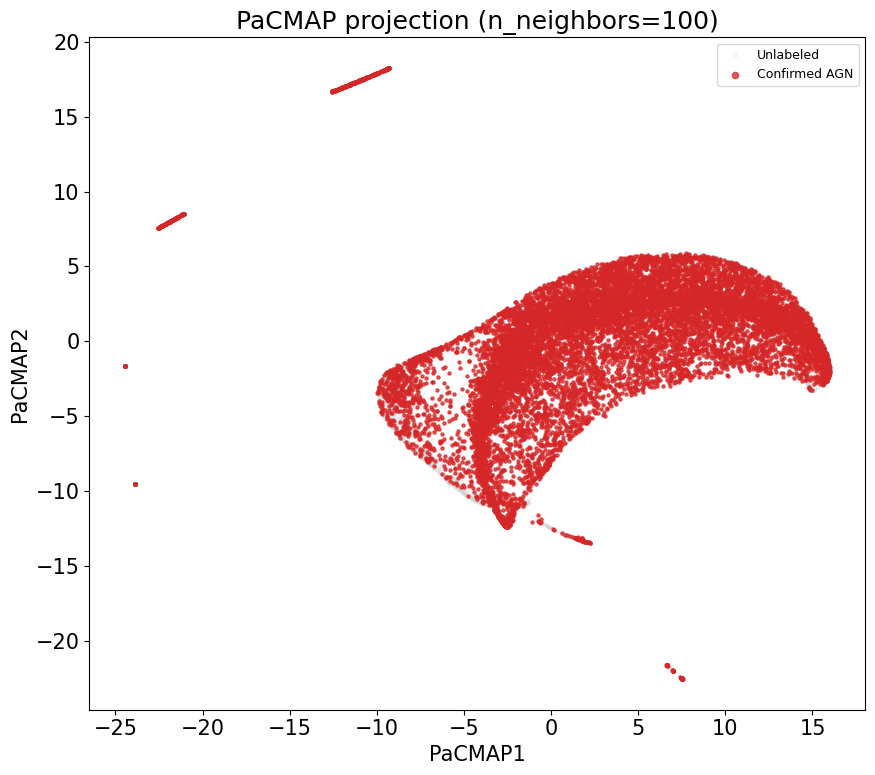

In [73]:
for n_neighbors in neighbors_list:
    result = pacmap_results[n_neighbors]

    mask_agn = result["label_3class"] == 2
    mask_unlabeled = result["label_3class"] == -1
    

    plt.figure(figsize=(9, 8))

    plt.scatter(
        result.loc[mask_unlabeled, "PaCMAP1"],
        result.loc[mask_unlabeled, "PaCMAP2"],
        s=2,
        alpha=0.15,
        color="lightgray",
        label="Unlabeled",
    )

    plt.scatter(
        result.loc[mask_agn, "PaCMAP1"],
        result.loc[mask_agn, "PaCMAP2"],
        s=5,
        alpha=0.75,
        color="tab:red",
        label="Confirmed AGN",
    )

    plt.xlabel("PaCMAP1")
    plt.ylabel("PaCMAP2")

    plt.title(
        f"PaCMAP projection (n_neighbors={n_neighbors})"
    )

    plt.legend(
        fontsize=9,
        markerscale=2,
    )

    plt.tight_layout()
    plt.show()

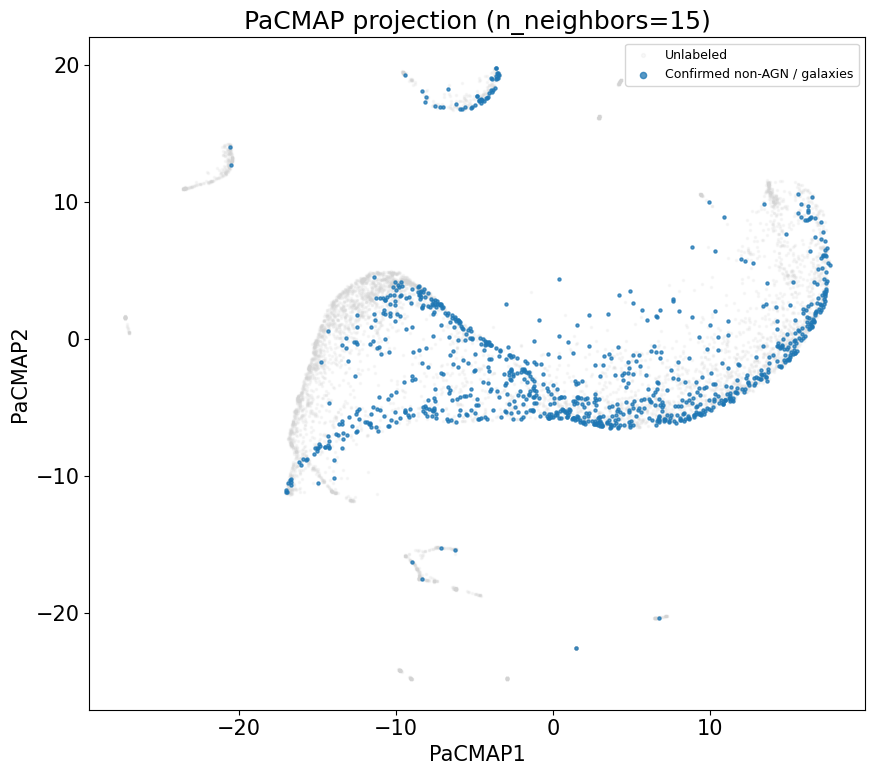

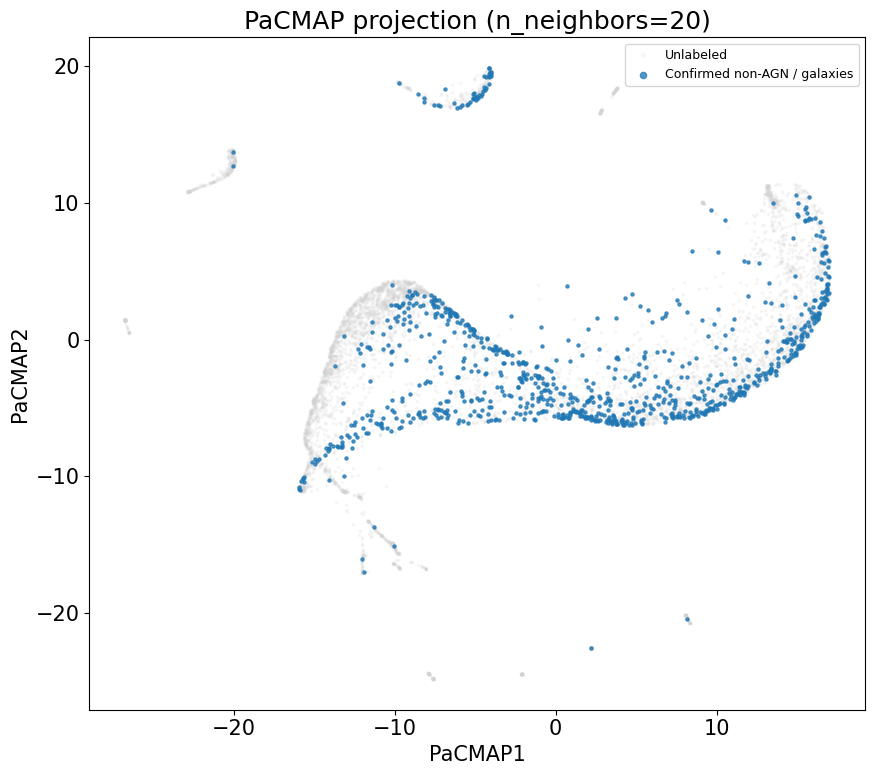

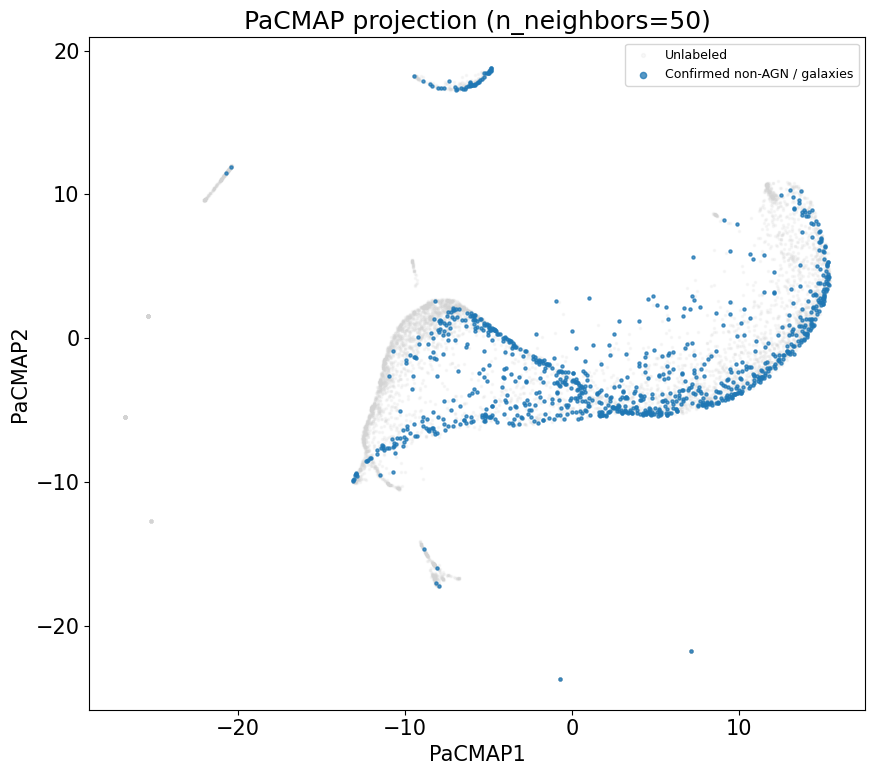

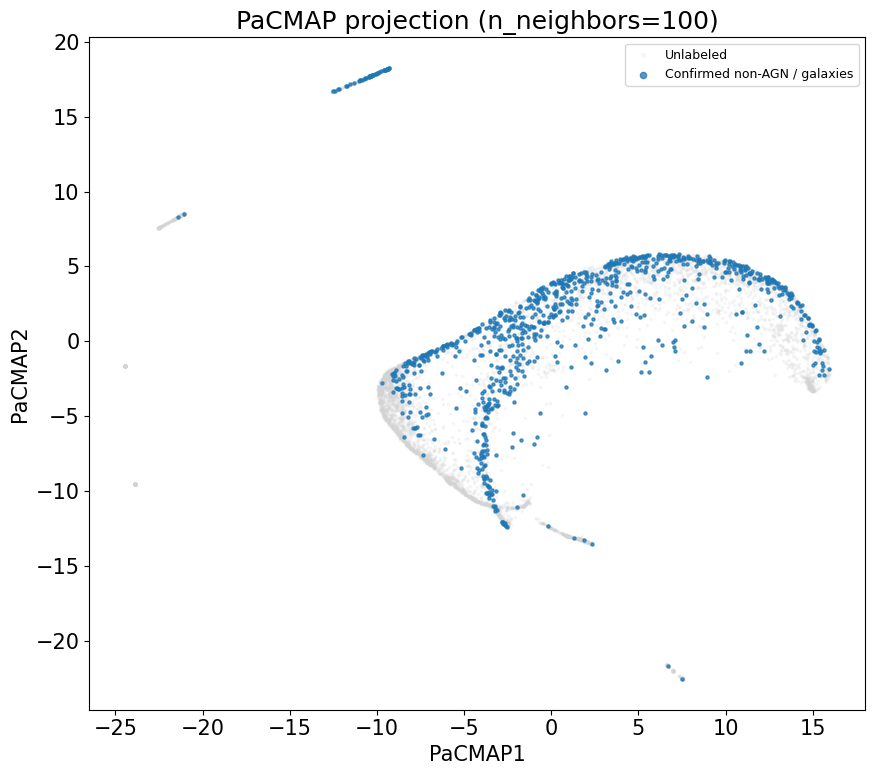

In [77]:
for n_neighbors in neighbors_list:
    result = pacmap_results[n_neighbors]

    mask_nonagn = (result["label_3class"] == 0)
    mask_unlabeled = result["label_3class"] == -1
    

    plt.figure(figsize=(9, 8))

    plt.scatter(
        result.loc[mask_unlabeled, "PaCMAP1"],
        result.loc[mask_unlabeled, "PaCMAP2"],
        s=2,
        alpha=0.15,
        color="lightgray",
        label="Unlabeled",
    )

    plt.scatter(
        result.loc[mask_nonagn, "PaCMAP1"],
        result.loc[mask_nonagn, "PaCMAP2"],
        s=5,
        alpha=0.75,
        color="tab:blue",
        label="Confirmed non-AGN / galaxies",
    )

    plt.xlabel("PaCMAP1")
    plt.ylabel("PaCMAP2")

    plt.title(
        f"PaCMAP projection (n_neighbors={n_neighbors})"
    )

    plt.legend(
        fontsize=9,
        markerscale=2,
    )

    plt.tight_layout()
    plt.show()

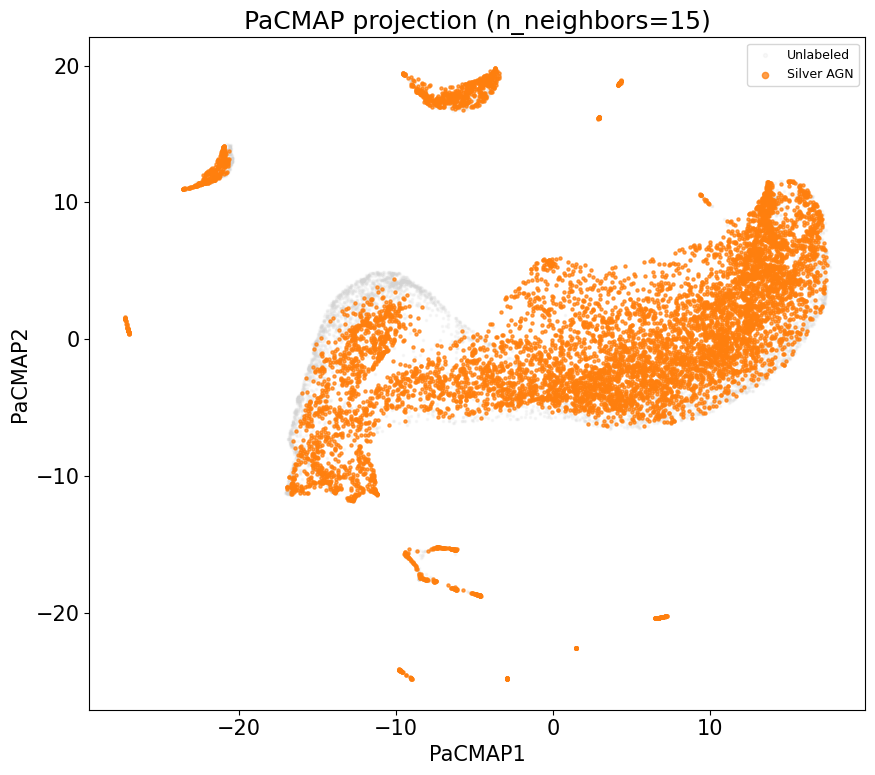

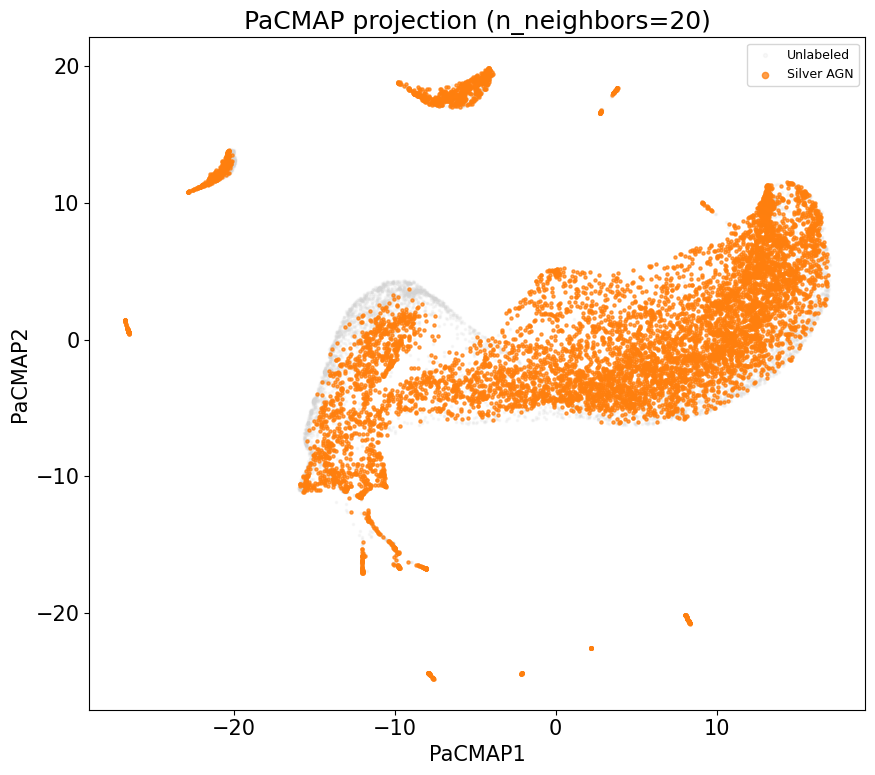

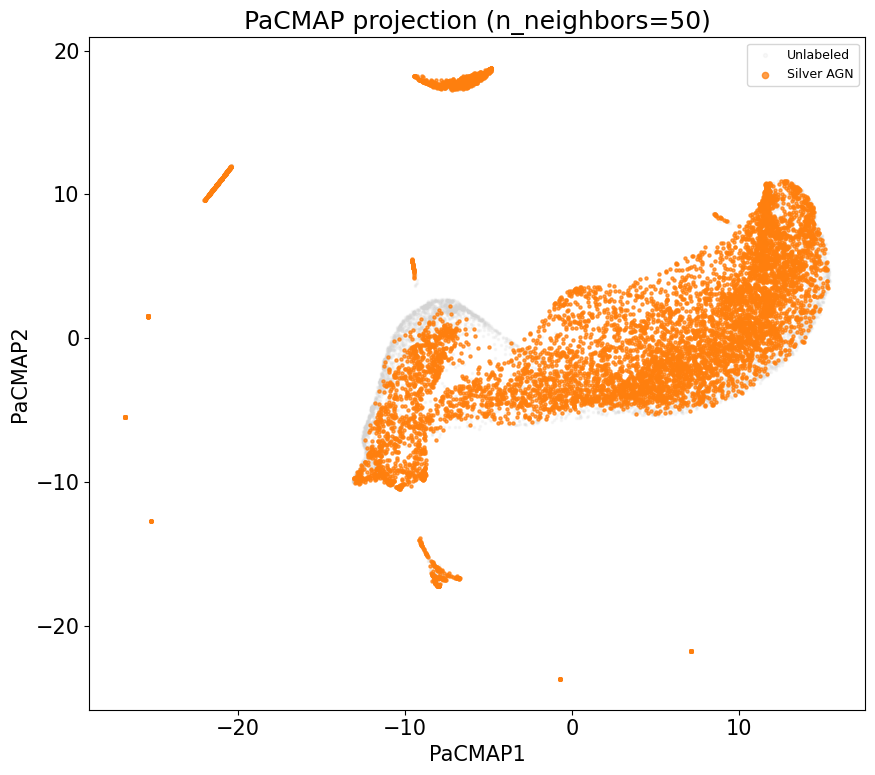

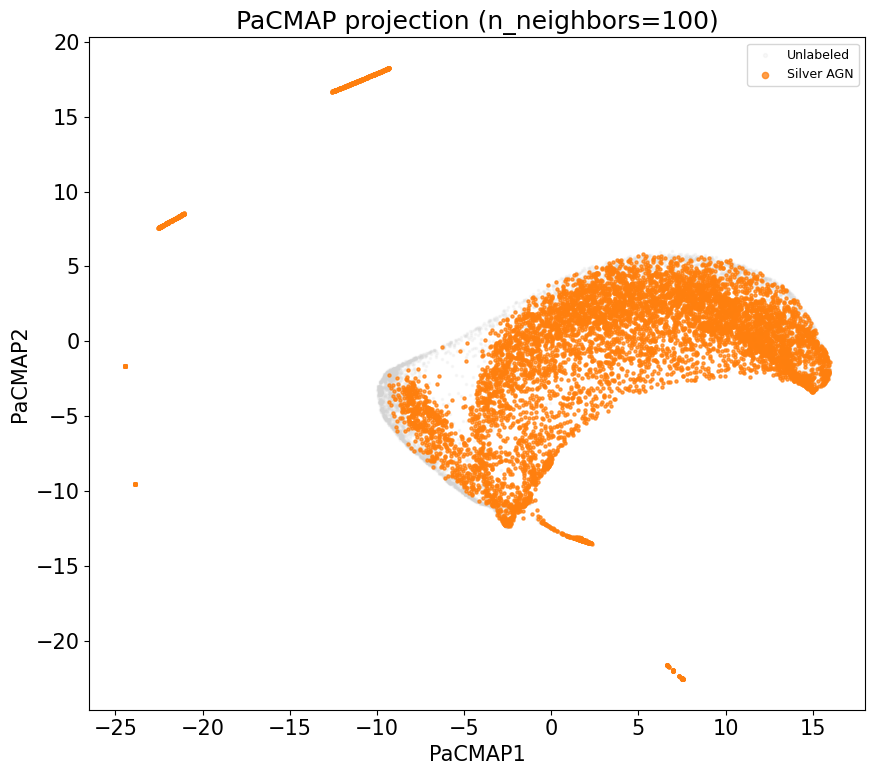

In [75]:
for n_neighbors in neighbors_list:
    result = pacmap_results[n_neighbors]

    mask_unlabeled = result["label_3class"] == -1
    mask_silver = result["label_3class"] == 1
    

    plt.figure(figsize=(9, 8))

    plt.scatter(
        result.loc[mask_unlabeled, "PaCMAP1"],
        result.loc[mask_unlabeled, "PaCMAP2"],
        s=2,
        alpha=0.15,
        color="lightgray",
        label="Unlabeled",
    )

    plt.scatter(
        result.loc[mask_silver, "PaCMAP1"],
        result.loc[mask_silver, "PaCMAP2"],
        s=5,
        alpha=0.75,
        color="tab:orange",
        label="Silver AGN",
    )

    plt.xlabel("PaCMAP1")
    plt.ylabel("PaCMAP2")

    plt.title(
        f"PaCMAP projection (n_neighbors={n_neighbors})"
    )

    plt.legend(
        fontsize=9,
        markerscale=2,
    )

    plt.tight_layout()
    plt.show()

# Clustering determination pipeline:
UMAP -> Clustering (HDBSCAN / KMeans) -> Cluster labels -> Classifiers (XGBoost / LightGBM) -> SHAP

In [ ]:
import hdbscan

clusterer = hdbscan.HDBSCAN(
    min_cluster_size=80,
    min_samples=20
)

clusters = clusterer.fit_predict(embedding)

umap_df["cluster"] = clusters

# Previous UMAP algorithm

In [ ]:
reducer15 = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="euclidean",
    random_state=42,
    n_jobs=-1,
    low_memory=True,
)

embedding = reducer15.fit_transform(X_pca)

print(embedding.shape)

umap_df = pd.DataFrame(
    {
        "UMAP1": embedding[:, 0],
        "UMAP2": embedding[:, 1]
    },
    index=df_sample.index
)

umap_df["label_3class"] = df_sample["label_3class"].values
umap_df["agn_positive"] = df_sample["agn_positive"].values
umap_df["agn_negative"] = df_sample["agn_negative"].values
umap_df["silver_agn"] = df_sample["silver_agn"].values
umap_df["significance"] = df_sample["significance"].values
umap_df["has_csc_spectral_fit"] = df_sample["has_csc_spectral_fit"].values
umap_df["has_high_quality_combo_z"] = df_sample["has_high_quality_combo_z"].values
umap_df["NaN_percent"] = df_sample.isna().mean(axis=1).values * 100

display(umap_df.head(20))

In [ ]:
# Additional
 
umap_df = pd.DataFrame(
    {
        "name": df_sample["name"].to_numpy(),
        "UMAP1": embedding[:, 0],
        "UMAP2": embedding[:, 1],

        "label_3class": df_sample["label_3class"].to_numpy(),
        "agn_positive": df_sample["agn_positive"].to_numpy(),
        "agn_negative": df_sample["agn_negative"].to_numpy(),
        "silver_agn": df_sample["silver_agn"].to_numpy(),

        "xray_agn": df_sample["xray_agn"].to_numpy(),
        "optical_agn": df_sample["optical_agn"].to_numpy(),
        "ir_agn": df_sample["ir_agn"].to_numpy(),

        "significance": df_sample["significance"].to_numpy(),
        "has_csc_spectral_fit": df_sample["has_csc_spectral_fit"].to_numpy(),
        "has_high_quality_combo_z": df_sample["has_high_quality_combo_z"].to_numpy(),
        "NaN_percent": (
            df_sample.isna().mean(axis=1).to_numpy() * 100
        ),
    },
    index=df_sample.index,
)

display(umap_df.head(20))

In [ ]:
# Plotting UMAP structure
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 8))

plt.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    s=2,
    alpha=0.5
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP projection of multiwavelength source features")
plt.show()

In [ ]:
plt.figure(figsize=(9, 8))

mask_unlabeled = umap_df["label_3class"] == -1
mask_significance = ((umap_df["significance"] >= 3) & (umap_df["label_3class"] == 0))
mask_gamma_sf = umap_df["has_csc_spectral_fit"] == 1
mask_high_quality_combo_z = umap_df["has_high_quality_combo_z"] == 1
mask_nonagn = ((umap_df["label_3class"] == 0) & (umap_df["significance"] < 3))
mask_agn = umap_df["label_3class"] == 2
mask_silver = umap_df["label_3class"] == 1


plt.scatter(
    umap_df.loc[mask_unlabeled, "UMAP1"],
    umap_df.loc[mask_unlabeled, "UMAP2"],
    s=2,
    alpha=0.15,
    color="lightgray",
    label="Unlabeled"
)

plt.scatter(
    umap_df.loc[mask_nonagn, "UMAP1"],
    umap_df.loc[mask_nonagn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="black",
    label="Confirmed non-AGN / galaxies"
)

plt.scatter(
    umap_df.loc[mask_significance , "UMAP1"],
    umap_df.loc[mask_significance, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:blue",
    label="Galaxies with significance >= 3"
)

"""
plt.scatter(
    umap_df.loc[mask_agn, "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:",
    label="Confirmed AGN"
)
"""


# candidate_mask = df_train["score_bagged_pseudo_lgbm"] > 0.8
"""
plt.scatter(
    umap_df.loc[mask_silver, "UMAP1"],
    umap_df.loc[mask_silver, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:orange",
    label="Objects from silver sample"
)
"""

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
plt.legend(markerscale=2)
plt.legend(fontsize=10)
plt.show()

umap_df["label_3class"].value_counts()

In [ ]:
plt.figure(figsize=(9, 8))

mask_unlabeled = umap_df["label_3class"] == -1
mask_significance = ((umap_df["significance"] >= 3) & (umap_df["label_3class"] == 0))
mask_gamma_sf = umap_df["has_csc_spectral_fit"] == 1
mask_high_quality_combo_z = umap_df["has_high_quality_combo_z"] == 1
mask_nonagn = ((umap_df["label_3class"] == 0) & (umap_df["significance"] < 3))
mask_agn = umap_df["label_3class"] == 2
mask_silver = umap_df["label_3class"] == 1


plt.scatter(
    umap_df.loc[mask_unlabeled, "UMAP1"],
    umap_df.loc[mask_unlabeled, "UMAP2"],
    s=2,
    alpha=0.15,
    color="lightgray",
    label="Unlabeled"
)

plt.scatter(
    umap_df.loc[mask_nonagn, "UMAP1"],
    umap_df.loc[mask_nonagn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="black",
    label="Confirmed non-AGN / galaxies"
)

plt.scatter(
    umap_df.loc[mask_agn , "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:red",
    label="Galaxies with significance >= 3"
)

"""
plt.scatter(
    umap_df.loc[mask_agn, "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:",
    label="Confirmed AGN"
)
"""


# candidate_mask = df_train["score_bagged_pseudo_lgbm"] > 0.8
"""
plt.scatter(
    umap_df.loc[mask_silver, "UMAP1"],
    umap_df.loc[mask_silver, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:orange",
    label="Objects from silver sample"
)
"""

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
plt.legend(markerscale=2)
plt.legend(fontsize=10)
plt.show()

umap_df["label_3class"].value_counts()

In [ ]:
plt.figure(figsize=(9, 8))

mask_unlabeled = umap_df["label_3class"] == -1
mask_significance = ((umap_df["significance"] >= 3) & (umap_df["label_3class"] == 0))
mask_gamma_sf = umap_df["has_csc_spectral_fit"] == 1
mask_high_quality_combo_z = umap_df["has_high_quality_combo_z"] == 1
mask_nonagn = (umap_df["label_3class"] == 0)
mask_agn = umap_df["label_3class"] == 2
mask_silver = umap_df["label_3class"] == 1


plt.scatter(
    umap_df.loc[mask_unlabeled, "UMAP1"],
    umap_df.loc[mask_unlabeled, "UMAP2"],
    s=2,
    alpha=0.15,
    color="lightgray",
    label="Unlabeled"
)

plt.scatter(
    umap_df.loc[mask_nonagn, "UMAP1"],
    umap_df.loc[mask_nonagn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:blue",
    label="Confirmed non-AGN / galaxies"
)

plt.scatter(
    umap_df.loc[mask_agn , "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:red",
    label="Confirmed AGN"
)

"""
plt.scatter(
    umap_df.loc[mask_agn, "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:",
    label="Confirmed AGN"
)
"""


# candidate_mask = df_train["score_bagged_pseudo_lgbm"] > 0.8
"""
plt.scatter(
    umap_df.loc[mask_silver, "UMAP1"],
    umap_df.loc[mask_silver, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:orange",
    label="Objects from silver sample"
)
"""

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
plt.legend(markerscale=2)
plt.legend(fontsize=10)
plt.show()

umap_df["label_3class"].value_counts()

In [ ]:
plt.figure(figsize=(9, 8))

mask_unlabeled = umap_df["label_3class"] == -1
mask_significance = ((umap_df["significance"] >= 3) & (umap_df["label_3class"] == 0))
mask_gamma_sf = umap_df["has_csc_spectral_fit"] == 1
mask_high_quality_combo_z = umap_df["has_high_quality_combo_z"] == 1
mask_nonagn = ((umap_df["label_3class"] == 0))
mask_agn = umap_df["label_3class"] == 2
mask_silver = umap_df["label_3class"] == 1


plt.scatter(
    umap_df.loc[mask_unlabeled, "UMAP1"],
    umap_df.loc[mask_unlabeled, "UMAP2"],
    s=2,
    alpha=0.15,
    color="lightgray",
    label="Unlabeled"
)

plt.scatter(
    umap_df.loc[mask_nonagn, "UMAP1"],
    umap_df.loc[mask_nonagn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:blue",
    label="Confirmed non-AGN / galaxies"
)
"""
plt.scatter(
    umap_df.loc[mask_agn , "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:red",
    label="Confirmed AGN"
)
"""
"""
plt.scatter(
    umap_df.loc[mask_agn, "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:",
    label="Confirmed AGN"
)
"""


# candidate_mask = df_train["score_bagged_pseudo_lgbm"] > 0.8
"""
plt.scatter(
    umap_df.loc[mask_silver, "UMAP1"],
    umap_df.loc[mask_silver, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:orange",
    label="Objects from silver sample"
)
"""

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
plt.legend(markerscale=2)
plt.legend(fontsize=10)
plt.show()

umap_df["label_3class"].value_counts()

In [ ]:
for label_col in ["xray_agn", "optical_agn", "ir_agn"]:
    if label_col in df.columns:
        label_values = df[label_col].fillna(False).astype(bool)
        plt.figure(figsize=(9, 8))

        plt.scatter(
            umap_df.loc[mask_unlabeled, "UMAP1"],
            umap_df.loc[mask_unlabeled, "UMAP2"],
            s=2,
            alpha=0.15,
            color="lightgray",
            label="Unlabeled"
        )

        """
        plt.scatter(
            umap_df.loc[mask_nonagn, "UMAP1"],
            umap_df.loc[mask_nonagn, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:blue",
            label="Confirmed non-AGN / galaxies"
        )
        """
        
        plt.scatter(
            umap_df.loc[label_values, "UMAP1"],
            umap_df.loc[label_values, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:red",
            label=f"{label_col} AGN"
        )

# variability flag to add (in infrared); 
# do corrections for formulas;
# ;

        plt.xlabel("UMAP1")
        plt.ylabel("UMAP2")
        plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
        plt.legend(markerscale=2)
        plt.legend(fontsize=10)
        plt.show()

In [ ]:
for label_col in ["mateos_wedge", "xray_opt_r_relation_legacy", "has_high_quality_combo_z", "has_csc_spectral_fit"]:
    if label_col in df.columns:
        label_values = df[label_col].fillna(False).astype(bool)
        plt.figure(figsize=(9, 8))

        plt.scatter(
            umap_df.loc[mask_unlabeled, "UMAP1"],
            umap_df.loc[mask_unlabeled, "UMAP2"],
            s=2,
            alpha=0.15,
            color="lightgray",
            label="Unlabeled"
        )

        """
        plt.scatter(
            umap_df.loc[mask_nonagn, "UMAP1"],
            umap_df.loc[mask_nonagn, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:blue",
            label="Confirmed non-AGN / galaxies"
        )
        """
        
        plt.scatter(
            umap_df.loc[label_values, "UMAP1"],
            umap_df.loc[label_values, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:red",
            label=f"{label_col} AGN"
        )

# variability flag to add (in infrared); 
# do corrections for formulas;
# ;

        plt.xlabel("UMAP1")
        plt.ylabel("UMAP2")
        plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
        plt.legend(markerscale=2)
        plt.legend(fontsize=10)
        plt.show()

# SHAP

In [ ]:
data=pd.read_csv('../data/raw/Multiwave_UMAP_6_26_26.csv')

print(len(data))
print(len(data))
print(len(data[data['CSC_b_lum']>=1e42]))
xlim_low=-12
xlim_high=-5
ylim_low=0
ylim_high=7

plt.figure(figsize=(9, 7))
        
plt.scatter(
    umap_df.loc[~label_values, "UMAP1"],
    umap_df.loc[~label_values, "UMAP2"],
    s=2,
    alpha=0.2,
    label="Unlabeled"
)
        
plt.scatter(
    umap_df.loc[label_values, "UMAP1"],
    umap_df.loc[label_values, "UMAP2"],
    s=5,
    alpha=0.8,
    label=label_col
)
        
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title(f"UMAP highlighted by {label_col}")
plt.legend(markerscale=4)
plt.xlim(xlim_low,xlim_high)
plt.ylim(ylim_low, ylim_high)

x=umap_df['UMAP1']
y=umap_df['UMAP2']
mask_sub=(x > xlim_low) & (x < xlim_high) & (y > ylim_low) & (y < ylim_high)
sub1=umap_df[mask_sub]
print(len(sub1))

umap_sub=data[data['name'].isin(sub1['name'])]
print(len(umap_sub))
print(list(umap_sub.columns))

umap_sub_agn=umap_sub[umap_sub['IR_agn']==True]
print('Subset AGN:', len(umap_sub_agn))
umap_sub_unc=umap_sub[~umap_sub['name'].isin(umap_sub_agn['name'])]
print('Subset Uncertain:', len(umap_sub_unc))

In [ ]:
plt.figure(figsize=(6.25,6.25))
print('Uncertain w/ WISE', len(umap_sub_unc.dropna(subset=['WISE_w1mpro'])))
print('Uncertain w/out WISE', (len(umap_sub_unc)-len(umap_sub_unc.dropna(subset=['WISE_w1mpro']))))
umap_sub_xray=umap_sub[umap_sub['xray_agn']==True]
umap_sub_opt=umap_sub[umap_sub['optical_agn']==True]
umap_nonx_z=umap_sub[~umap_sub['name'].isin(umap_sub_xray['name'])]
umap_nonx_z=umap_nonx_z.dropna(subset=['Rec_Z'])
mask_imbh=(umap_nonx_z['CSC_b_lum']>=1e39) & (umap_nonx_z['CSC_b_lum']<1e42)
umap_nonx_z=umap_nonx_z[mask_imbh]

plt.plot([1.855, 8.587], [1.380, 3.501], c='black', linestyle='--', linewidth=3.5)
# round(mask_wedge_Z.sum()/len(crossed_Z)*100, 2))
plt.plot([2.147, 8.587], [0.454, 2.483], c='black', linestyle='--', linewidth=3.5)
plt.plot([1.855, 2.147], [1.380, 0.454], c='black', linestyle='--', linewidth=3.5)
plt.scatter(umap_sub_unc['WISE_w2mpro']-umap_sub_unc['WISE_w3mpro'], umap_sub_unc['WISE_w1mpro']-umap_sub_unc['WISE_w2mpro'],
            s=3, color='gray', label='Uncertain Possible AGN')
plt.scatter(umap_sub_xray['WISE_w2mpro']-umap_sub_xray['WISE_w3mpro'], umap_sub_xray['WISE_w1mpro']-umap_sub_xray['WISE_w2mpro'],
            s=3, color='dodgerblue', label='X-ray in Unc pop')
plt.scatter(umap_nonx_z['WISE_w2mpro']-umap_nonx_z['WISE_w3mpro'], umap_nonx_z['WISE_w1mpro']-umap_nonx_z['WISE_w2mpro'],
            s=3, color='purple', label='b band 1e39<Lx<1e42')
plt.scatter(umap_sub_opt['WISE_w2mpro']-umap_sub_opt['WISE_w3mpro'], umap_sub_opt['WISE_w1mpro']-umap_sub_opt['WISE_w2mpro'],
            s=3, color='forestgreen', label='Optical in Unc pop')
plt.scatter(umap_sub_agn['WISE_w2mpro']-umap_sub_agn['WISE_w3mpro'], umap_sub_agn['WISE_w1mpro']-umap_sub_agn['WISE_w2mpro'], 
            s=3, color='orangered', label='IR AGN')

x=umap_sub_unc['WISE_w2mpro']-umap_sub_unc['WISE_w3mpro']
y=umap_sub_unc['WISE_w1mpro']-umap_sub_unc['WISE_w2mpro']
mask_wedge = (
    (y <= 0.315*x + 0.796) &
    (y >= 0.315*x - 0.222) &
    (y >= -3.172*x + 7.264)
) 
print('Uncertain in wedge:', mask_wedge.sum())

plt.xlabel('W2-W3 (Vega)')
plt.ylabel('W1-W2 (Vega)')
plt.legend(loc='upper left')
plt.xlim(-0.5, 6.5)
plt.ylim(-1, 3)

In [ ]:
fig, axes = plt.subplots(
    1, 4,
    figsize=(31, 6.5),
)

bins=np.linspace(umap_sub['significance'].min(), umap_sub['significance'].max(), 30)
axes[0].hist(umap_sub_agn['significance'], bins=bins, color='coral', label='IR AGN')
axes[0].hist(umap_sub_unc['significance'], bins=bins, color='silver', hatch='xxx', alpha=0.6, label='Unconfirmed')
axes[0].legend(loc='upper right')
axes[0].set_xlabel('Source Significance')
axes[0].set_ylabel('Number of Sources')

umap_sub_agn_z=umap_sub_agn.dropna(subset=['Rec_Z'])
umap_sub_unc_z=umap_sub_unc.dropna(subset=['Rec_Z'])
print('Subset w/ z:', len(umap_sub_unc_z))
bins=np.linspace(umap_sub['Rec_Z'].min(), umap_sub['Rec_Z'].max(), 30)
axes[1].hist(umap_sub_agn_z['Rec_Z'], bins=bins, color='coral', label='AGN')
axes[1].hist(umap_sub_unc_z['Rec_Z'], bins=bins, color='cornflowerblue', label='Uncertain')
axes[1].legend(loc='upper left')
axes[1].set_xlabel('Redshift')

bins=np.linspace(umap_sub['hard_hs'].min(), umap_sub['hard_hs'].max(), 30)
# axes[0].hist(umap_sub['hard_hs'], bins=bins, color='silver', label='AGN')
axes[2].hist(umap_sub_unc['hard_hs'], bins=bins, color='cornflowerblue', label='Uncertain')
axes[2].hist(umap_sub_agn['hard_hs'], bins=bins, color='coral', label='AGN')
axes[2].set_xlabel('Hardness Ratio Hard-Soft')
axes[2].legend(loc='upper right')

bins=np.linspace(umap_sub['hard_hm'].min(), umap_sub['hard_hm'].max(), 30)
# axes[1].hist(umap_sub['hard_hm'], bins=bins, color='silver', label='AGN')
axes[3].hist(umap_sub_unc['hard_hm'], bins=bins, color='cornflowerblue', label='Uncertain')
axes[3].hist(umap_sub_agn['hard_hm'], bins=bins, color='coral', label='AGN')
axes[3].legend(loc='upper right')
axes[3].set_xlabel('Hardness Ratio Hard-Medium')

In [ ]:
import shap
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report


umap_sub = umap_sub.copy()

umap_sub["target"] = (
    umap_sub["name"].isin(umap_sub_agn["name"])
).astype(int)

exclude_cols = {
    "name", "target", "IR_agn", "xray_agn", "opt_agn", 'Unnamed: 0', 'Unnamed: 0.1', 'Unnamed: 0.2'
}

exclude_patterns = ["_id","objID","OBJID","designation","source_id","SPECOBJID","Unnamed","_ra","_dec","_RA","_DEC", "Sep_", "Separation_"
]

from pandas.api.types import is_numeric_dtype

feature_cols = [
    c for c in umap_sub.columns
    if c not in exclude_cols
    and is_numeric_dtype(umap_sub[c])
]

feature_cols = [
    c for c in feature_cols
    if not any(p in c for p in exclude_patterns)
]

X = umap_sub[feature_cols].copy()
y = umap_sub["target"].copy()

print(f"Initial rows: {len(X):,}")
print(f"IR AGN: {y.sum():,}")
print(f"Non-AGN: {(y==0).sum():,}")

X = X.replace([np.inf, -np.inf], np.nan)

# Log-transform luminosity columns
for col in X.columns:
    if "lum" in col.lower():
        X[col] = np.where(
            X[col] > 0,
            np.log10(X[col]),
            np.nan
        )

X = X.dropna(axis=1, how="all")

# Remove columns >95% missing
missing_fraction = X.isna().mean()
X = X.loc[:, missing_fraction < 0.95]

feature_cols = X.columns.tolist()

# Remove rows with no usable data
mask = X.notna().any(axis=1)

X = X.loc[mask]
y = y.loc[mask]

# Median imputation
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=feature_cols,
    index=X.index
)

print("\nSanity checks")
print("------------------------")
print("NaNs:", np.isnan(X.values).sum())
print("Infs:", np.isinf(X.values).sum())
print("Largest value:", np.abs(X.values).max())

#Train the algorithm here
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# A random forest classifier, part of determining what drives importance, I'd read 
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# A performance test, lowkey copied lot of this from the shap documentation
pred = rf.predict(X_test)

print("\nClassification Report")
print("----------------------")
print(classification_report(
    y_test,
    pred,
    target_names=["Uncertain","IR AGN"]
))


# Calculate the importance
importance = (
    pd.Series(
        rf.feature_importances_,
        index=feature_cols
    )
    .sort_values(ascending=False)
)

print("\nTop 20 Features")
print("----------------")
print(importance.head(20))

plt.figure(figsize=(10,6))
importance.head(20).plot(kind="bar")
plt.ylabel("Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

# This is the actual SHAP modeling
explainer = shap.TreeExplainer(rf)

shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    shap_plot = shap_values[1]
elif shap_values.ndim == 3:
    shap_plot = shap_values[:, :, 1]
else:
    shap_plot = shap_values

shap.summary_plot(
    shap_plot,
    X_test,
    feature_names=feature_cols,
    plot_type="dot"
)

# MISSC


In [ ]:
plt.figure(figsize=(9, 8))

mask_unlabeled = umap_df["label_3class"] == -1
mask_nonagn = umap_df["label_3class"] == 0
mask_agn = umap_df["label_3class"] == 2
mask_silver = umap_df["label_3class"] == 1
candidate_mask = ((df_train["score_bagged_pseudo_lgbm"] > 0.8) & (~mask_agn))


plt.scatter(
    umap_df.loc[mask_unlabeled, "UMAP1"],
    umap_df.loc[mask_unlabeled, "UMAP2"],
    s=2,
    alpha=0.15,
    color="lightgray",
    label="Unlabeled"
)

plt.scatter(
    umap_df.loc[mask_nonagn, "UMAP1"],
    umap_df.loc[mask_nonagn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:blue",
    label="Confirmed non-AGN / galaxies"
)

plt.scatter(
    umap_df.loc[mask_agn, "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:red",
    label="Confirmed AGN"
)

plt.scatter(
    umap_df.loc[candidate_mask, "UMAP1"],
    umap_df.loc[candidate_mask, "UMAP2"],
    s=5,
    alpha=0.75,
    color="tab:orange",
    label="AGN candidates from ML"
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
plt.legend(markerscale=2)
plt.legend(fontsize=10)
plt.show()

In [ ]:
df["xray_opt_r_agn"] = df["xray_opt_r_relation_legacy"] >= q80_r
for label_col in ["mateos_wedge", "xray_opt_r_agn"]:
    if label_col in df.columns:
        label_values = df[label_col].fillna(False).astype(bool)
        plt.figure(figsize=(9, 8))

        plt.scatter(
            umap_df.loc[mask_unlabeled, "UMAP1"],
            umap_df.loc[mask_unlabeled, "UMAP2"],
            s=2,
            alpha=0.15,
            color="lightgray",
            label="Unlabeled"
        )

        plt.scatter(
            umap_df.loc[mask_nonagn, "UMAP1"],
            umap_df.loc[mask_nonagn, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:blue",
            label="Confirmed non-AGN / galaxies"
        )

        plt.scatter(
            umap_df.loc[mask_agn, "UMAP1"],
            umap_df.loc[mask_agn, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:red",
            label="Confirmed non-AGN / galaxies"
        )

        plt.scatter(
            umap_df.loc[label_values, "UMAP1"],
            umap_df.loc[label_values, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:orange",
            label=f"{label_col} AGN"
        )

# variability flag to add (in infrared); 
# do corrections for formulas;
# ;

        plt.xlabel("UMAP1")
        plt.ylabel("UMAP2")
        plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
        plt.legend(markerscale=2)
        plt.legend(fontsize=10)
        plt.show()

In [ ]:
for label_col in ["xray_agn", "optical_agn", "ir_agn"]:
    if label_col in df.columns:
        label_values = df[label_col].fillna(False).astype(bool)
        plt.figure(figsize=(9, 8))

        plt.scatter(
            umap_df.loc[mask_unlabeled, "UMAP1"],
            umap_df.loc[mask_unlabeled, "UMAP2"],
            s=2,
            alpha=0.15,
            color="lightgray",
            label="Unlabeled"
        )

        plt.scatter(
            umap_df.loc[mask_nonagn, "UMAP1"],
            umap_df.loc[mask_nonagn, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:blue",
            label="Confirmed non-AGN / galaxies"
        )

        plt.scatter(
            umap_df.loc[label_values, "UMAP1"],
            umap_df.loc[label_values, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:red",
            label=f"{label_col} AGN"
        )

        plt.scatter(
            umap_df.loc[mask_silver, "UMAP1"],
            umap_df.loc[mask_silver, "UMAP2"],
            s=5,
            alpha=0.75,
            color="tab:orange",
            label="Objects from silver sample"
        )  

# Take a look check different colour luminoscity: 10^42 -- 10^43 at WISE colour colour diagram. See where they are falling,
# if they are on the side.



        plt.xlabel("UMAP1")
        plt.ylabel("UMAP2")
        plt.title("UMAP: confirmed AGN, confirmed non-AGN, and unlabeled sources")
        plt.legend(markerscale=2)
        plt.legend(fontsize=10)
        plt.show()

In [ ]:
labeled_mask = umap_df["label_3class"].isin([0, 1])

plt.figure(figsize=(9, 7))

plt.scatter(
    umap_df.loc[mask_nonagn, "UMAP1"],
    umap_df.loc[mask_nonagn, "UMAP2"],
    s=6,
    alpha=0.7,
    color="tab:blue",
    label="Confirmed non-AGN / galaxies"
)

plt.scatter(
    umap_df.loc[mask_agn, "UMAP1"],
    umap_df.loc[mask_agn, "UMAP2"],
    s=6,
    alpha=0.7,
    color="tab:red",
    label="Confirmed AGN"
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP labeled subset: AGN vs non-AGN")
plt.legend(markerscale=4)
plt.show()

In [ ]:
plt.figure(figsize=(9, 7))

plt.scatter(
    umap_df["UMAP1"],
    umap_df["UMAP2"],
    c=umap_df["NaN_percent"],
    s=2,
    alpha=0.6,
    cmap="viridis"
)

plt.colorbar(label="NaN percent per row")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("UMAP colored by missing-value percentage")
plt.show()

# Machine Learning Part

It is divided into 2 approaches, since we have ~30K of labeled observations and ~140K of unlabeled (where we mostly expect to see AGNs): 
1) Supervised -- we train model on 30K observations and use it to predict 
2) Unsupervised -- we use unlabeled observations for self-training/propagation and increase model's performance

# Training on reduced dataset

We use only the mostly covered columns (11-dimensional space)

In [ ]:
display(df_train.shape)

df_train['combo_g']=df_train['PS21P_g'].combine_first(df_train['LEG21P_G'])
df_train['combo_r']=df_train['PS21P_r'].combine_first(df_train['LEG21P_R'])
df_train['combo_z_mag']=df_train['PS21P_z'].combine_first(df_train['LEG21P_Z'])


df_train = df_train.dropna(subset=['significance', 'flux_aper_b', 'flux_aper_lolim_b', 'flux_aper_hilim_b', 'flux_aper_h','flux_aper_lolim_h',
'flux_aper_hilim_h','flux_aper_s','flux_aper_lolim_s','flux_aper_hilim_s','flux_aper_m','flux_aper_lolim_m','flux_aper_hilim_m','combo_g','combo_r','combo_z_mag','WISE_w1mpro', 
'WISE_w1snr','WISE_w2mpro', 'WISE_w2snr','WISE_w3mpro', 'WISE_w3snr'])

display(df_train.shape)

In [ ]:
df_train["binary_target"] = np.select(
    [
        df_train["label_3class"] == 2,
        df_train["label_3class"] == 0,
    ],
    [
        1,
        0,
    ],
    default=-1
).astype("int8")

# Supervised learning 
df_labeled = df_train[df_train["binary_target"].isin([0, 1])].copy()
y_labeled = df_labeled["binary_target"].astype("int8").to_numpy()

LABEL_COL = "binary_target"

positive_mask = df_train[LABEL_COL] == 1
negative_mask = df_train[LABEL_COL] == 0
unlabeled_mask = df_train[LABEL_COL] == -1

print("Confirmed AGN:", positive_mask.sum())
print("Confirmed non-AGN:", negative_mask.sum())
print("Unlabeled:", unlabeled_mask.sum())

X_aug = df_train.copy()

# Regular Training Procedure

We use initial approach for training on gold sample, with imputation of NaN values, 100% missing feature cut-off, using robustly confirmed labels.

In [ ]:
# Data Cleaning & Pre-processing
feature_missing_percent_train = df_train.isna().mean() * 100
display(feature_missing_percent_train.sort_values(ascending=False).head(20))

max_feature_missing_train = 100

keep_cols_train = feature_missing_percent_train[feature_missing_percent_train < max_feature_missing_train].index
X_train = df_train[keep_cols_train].copy()

X_train.shape

In [ ]:
# Imputing and encoding missing data
from sklearn.impute import SimpleImputer

sample_size = len(df_train) # we can adjust however we want

df_sample = df_train.sample(
    n=min(sample_size, len(df_train)),
    random_state=42
).copy()

X_train = X.loc[df_sample.index].copy()

print(df_sample.shape)
print(X_train.shape)

missing_indicators = X_train.isna().astype("int8")
missing_indicators.columns = [f"{col}_missing" for col in X_train.columns]

imputer = SimpleImputer(strategy="median")
X_clean_train = imputer.fit_transform(X_train)

X_umap_input = np.hstack([
    X_imputed,
    missing_indicators.values
]).astype("float32")

print(X_umap_input.shape)

In [ ]:
df_train["binary_target"] = np.select(
    [
        df_train["label_3class"] == 2,
        df_train["label_3class"] == 0,
    ],
    [
        1,
        0,
    ],
    default=-1
).astype("int8")

# Supervised learning 
df_labeled = df_train[df_train["binary_target"].isin([0, 1])].copy()
y_labeled = df_labeled["binary_target"].astype("int8").to_numpy()

LABEL_COL = "binary_target"

positive_mask = df_train[LABEL_COL] == 1
negative_mask = df_train[LABEL_COL] == 0
unlabeled_mask = df_train[LABEL_COL] == -1

print("Confirmed AGN:", positive_mask.sum())
print("Confirmed non-AGN:", negative_mask.sum())
print("Unlabeled:", unlabeled_mask.sum())

In [ ]:
metadata_cols = [
    "name",
    "col1",
    
    # AGN labels
    "xray_agn",
    "optical_agn",
    "ir_agn",
    "agn_class",
    "agn_positive",
    
    # non-AGN labels
    "non_agn",
    "agn_negative",
    
    # derived labels
    "label_3class",
    "label_conflict",
    "silver_score",
    "silver_agn",
    "binary_target",
    
    # training info
    "train_label", "train_weight", "label_source", "sample_weight",
    
    # masks
    "mateos_wedge",
    "wise_stern",

    # class / metadata columns
    "likelihood_class",
    "SDSS_CLASS",
    "SDSS_SUBCLASS",
    "2MASS21P_designation"
]

coords = ["ra", "dec", "gal_l", "gal_b"]


# Model may learn sky coverage -> do an experiment with coords and without coords
exclude_cols_train = [c for c in metadata_cols + coords if c in df_train.columns]


# Drop columns and select numerical features
X_all = df_train.drop(columns=exclude_cols_train, errors="ignore")
print(X_all.shape)

X_all = X_all.select_dtypes(include=[np.number, "bool"]).copy()
print(X_all.shape)

X_all = X_all.replace([np.inf, -np.inf], np.nan)

display(X_all.head(20))


In [ ]:
# Adding missing flags as indicators
missing_flags = X_all.isna().astype("int8")
missing_flags.columns = [f"{c}_missing" for c in X_all.columns]

X_aug = pd.concat([X_all, missing_flags], axis=1)

X_aug.shape

In [ ]:
# Small check for other random-labeled bad columns
bad_keywords = [
    "redshift", "spec", "spectro",
    "class", "subclass",
    "label",
    "likelihood", "prob"
]

clean_cols = [
    c for c in X_aug.columns
    if not any(k in c.lower() for k in bad_keywords)
]


X_aug_clean = X_aug[clean_cols]

X_aug = X_aug_clean.copy()

# Common ML training algorithm

In [ ]:
# ML here
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)
from sklearn.base import clone

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Labeled
labeled_mask = df_train[LABEL_COL].isin([0, 1])

X_labeled = X_aug.loc[labeled_mask].copy()
y_labeled = (
    df_train.loc[labeled_mask, LABEL_COL]
    .astype("int8")
    .to_numpy()
)

print(X_labeled.shape)
print(pd.Series(y_labeled).value_counts())

In [ ]:
# Models
base_models = {
    "lightgbm": LGBMClassifier(
        n_estimators=700,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),

    "catboost": CatBoostClassifier(
        iterations=700,
        learning_rate=0.03,
        depth=7,
        l2_leaf_reg=5,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    ),
}

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

unlabeled_idx = df_train.index[
    df_train[LABEL_COL] == -1
]

X_unlabeled = X_aug.loc[unlabeled_idx]

oof_predictions = {}
unlabeled_fold_predictions = {}

for model_name, base_model in base_models.items():
    print(f"\nMODEL: {model_name}")

    oof = np.zeros(len(X_labeled))
    u_fold_preds = []

    for fold, (train_pos, valid_pos) in enumerate(
        cv.split(X_labeled, y_labeled),
        start=1,
    ):
        model = clone(base_model)

        X_tr = X_labeled.iloc[train_pos]
        X_va = X_labeled.iloc[valid_pos]

        y_tr = y_labeled[train_pos]
        y_va = y_labeled[valid_pos]

        model.fit(X_tr, y_tr)

        valid_pred = model.predict_proba(X_va)[:, 1]
        oof[valid_pos] = valid_pred

        unlabeled_pred = model.predict_proba(X_unlabeled)[:, 1]
        u_fold_preds.append(unlabeled_pred)

        print(
            f"Fold {fold}:",
            "ROC-AUC =", round(
                roc_auc_score(y_va, valid_pred), 5
            ),
            "PR-AUC =", round(
                average_precision_score(y_va, valid_pred), 5
            ),
        )

    oof_predictions[model_name] = oof
    unlabeled_fold_predictions[model_name] = np.vstack(
        u_fold_preds
    )

    print(
        "OOF ROC-AUC:",
        roc_auc_score(y_labeled, oof)
    )
    print(
        "OOF PR-AUC:",
        average_precision_score(y_labeled, oof)
    )

In [ ]:
from scipy.special import expit, logit

eps = 1e-6

lgbm_u = unlabeled_fold_predictions["lightgbm"]
cat_u = unlabeled_fold_predictions["catboost"]

# Средний прогноз каждого алгоритма по folds
lgbm_mean = lgbm_u.mean(axis=0)
cat_mean = cat_u.mean(axis=0)

# Ensemble
ensemble_score = expit(
    (
        logit(np.clip(lgbm_mean, eps, 1 - eps))
        +
        logit(np.clip(cat_mean, eps, 1 - eps))
    ) / 2
)

# Неопределённость между folds и моделями
all_u_predictions = np.vstack([
    lgbm_u,
    cat_u,
])

ensemble_std = all_u_predictions.std(axis=0)

df_train.loc[
    unlabeled_idx,
    "score_stage1"
] = ensemble_score

df_train.loc[
    unlabeled_idx,
    "score_stage1_std"
] = ensemble_std

In [ ]:
u_results = pd.DataFrame(
    {
        "lgbm_score": lgbm_mean,
        "cat_score": cat_mean,
        "ensemble_score": ensemble_score,
        "score_std": ensemble_std,
    },
    index=unlabeled_idx,
)

u_results["model_disagreement"] = (
    u_results["lgbm_score"]
    - u_results["cat_score"]
).abs()

display(u_results.describe())

In [ ]:
pseudo_positive_fraction = 0.20

score_cutoff = u_results["ensemble_score"].quantile(
    1 - pseudo_positive_fraction
)

std_cutoff = u_results["score_std"].quantile(0.50)
disagreement_cutoff = u_results[
    "model_disagreement"
].quantile(0.50)

pseudo_positive_mask = (
    (u_results["ensemble_score"] >= score_cutoff)
    &
    (u_results["score_std"] <= std_cutoff)
    &
    (
        u_results["model_disagreement"]
        <= disagreement_cutoff
    )
)

pseudo_positive_idx = u_results.index[
    pseudo_positive_mask
]

print("Pseudo-positive candidates:", len(pseudo_positive_idx))

In [ ]:
def pseudo_positive_bagging(
    X,
    labels,
    candidate_positive_idx,
    base_model,
    n_bags=30,
    candidate_fraction=0.7,
    pseudo_weight=0.2,
    seed=42,
):
    rng = np.random.default_rng(seed)

    positive_idx = np.flatnonzero(labels == 1)
    negative_idx = np.flatnonzero(labels == 0)

    candidate_positions = X.index.get_indexer(
        candidate_positive_idx
    )
    candidate_positions = candidate_positions[
        candidate_positions >= 0
    ]

    predictions = []

    for bag in range(n_bags):
        # Bootstrap confirmed labels
        bag_pos = rng.choice(
            positive_idx,
            size=len(positive_idx),
            replace=True
        )

        bag_neg = rng.choice(
            negative_idx,
            size=len(negative_idx),
            replace=True
        )

        n_candidates = max(
            1,
            int(
                len(candidate_positions)
                * candidate_fraction
            )
        )

        bag_pseudo = rng.choice(
            candidate_positions,
            size=n_candidates,
            replace=False
        )

        train_positions = np.concatenate([
            bag_pos,
            bag_neg,
            bag_pseudo,
        ])

        y_train = np.concatenate([
            np.ones(len(bag_pos), dtype="int8"),
            np.zeros(len(bag_neg), dtype="int8"),
            np.ones(len(bag_pseudo), dtype="int8"),
        ])

        sample_weight = np.concatenate([
            np.ones(len(bag_pos)),
            np.ones(len(bag_neg)),
            np.full(len(bag_pseudo), pseudo_weight),
        ])

        model = clone(base_model)

        if model.__class__.__name__.startswith("LGBM"):
            model.set_params(random_state=seed + bag)

        model.fit(
            X.iloc[train_positions],
            y_train,
            sample_weight=sample_weight,
        )

        predictions.append(
            model.predict_proba(X)[:, 1]
        )

    predictions = np.vstack(predictions)

    return (
        predictions.mean(axis=0),
        predictions.std(axis=0),
        predictions,
    )

In [ ]:
labels_all = df_train[LABEL_COL].to_numpy()

bag_score_lgbm, bag_std_lgbm, _ = (
    pseudo_positive_bagging(
        X=X_aug,
        labels=labels_all,
        candidate_positive_idx=pseudo_positive_idx,
        base_model=base_models["lightgbm"],
        n_bags=30,
        candidate_fraction=0.7,
        pseudo_weight=0.20,
        seed=42,
    )
)

df_train["score_bagged_pseudo_lgbm"] = (
    bag_score_lgbm
)

df_train["score_bagged_pseudo_lgbm_std"] = (
    bag_std_lgbm
)

In [ ]:
candidate_mask = df_train["score_bagged_pseudo_lgbm"] > 0.8

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.base import clone
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import numpy as np

train_mask = df["train_label"].isin([0, 1])
df_sup = df.loc[train_mask].copy()

X = df_sup[feature_cols]
y = df_sup["train_label"].astype(int)
w = df_sup["train_weight"].astype(float)

models = {
    "lgbm": LGBMClassifier(
        n_estimators=2000,
        learning_rate=0.015,
        num_leaves=31,
        min_child_samples=80,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=1.0,
        reg_lambda=5.0,
        objective="binary",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ),
    "cat": CatBoostClassifier(
        iterations=1500,
        learning_rate=0.02,
        depth=6,
        l2_leaf_reg=8,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        verbose=False,
        allow_writing_files=False
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = {}

for name, base_model in models.items():
    print("\nMODEL:", name)
    oof = np.zeros(len(df_sup))

    for fold, (tr, va) in enumerate(cv.split(X, y), 1):
        model = clone(base_model)

        model.fit(
            X.iloc[tr], y.iloc[tr],
            sample_weight=w.iloc[tr]
        )

        pred = model.predict_proba(X.iloc[va])[:, 1]
        oof[va] = pred

        print(
            fold,
            "ROC:", round(roc_auc_score(y.iloc[va], pred), 4),
            "PR:", round(average_precision_score(y.iloc[va], pred), 4),
            "Brier:", round(brier_score_loss(y.iloc[va], pred), 4)
        )

    oof_preds[name] = oof
    print("OOF ROC:", round(roc_auc_score(y, oof), 4))
    print("OOF PR:", round(average_precision_score(y, oof), 4))

In [ ]:
missing_cols = [c for c in X_aug.columns if c.endswith("_missing")]
X_missing_only = X_aug[missing_cols]

In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

X_labeled = X_aug.loc[df_labeled.index].copy()

# Подготовка таргета: сбрасываем индексы и переводим в numpy-массив
y_labeled_arr = y_labeled.values if hasattr(y_labeled, 'values') else np.array(y_labeled)
X_labeled_reset = X_labeled.reset_index(drop=True)

unique_classes = np.unique(y_labeled_arr)
n_classes = len(unique_classes) # Будет равно 3

models = {
    "lightgbm": LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        class_weight="balanced", # Отлично работает и для мультикласса
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
    "catboost": CatBoostClassifier(
        iterations=1000,
        learning_rate=0.03,
        depth=7,
        l2_leaf_reg=5,
        loss_function="MultiClass",     # <-- ИЗМЕНЕНО: Для 3 классов вместо Logloss
        eval_metric="MultiClass",       # <-- ИЗМЕНЕНО: AUC в мультиклассе на валидации ведет себя капризно
        auto_class_weights="Balanced",  # Поддерживает балансировку мультикласса
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Создаем oof-массив размерностью (количество_строк, 3_класса)
# Каждая ячейка будет хранить матрицу вероятностей для каждого класса
oof = {name: np.zeros((len(df_labeled), n_classes)) for name in models}

for name, base_model in models.items():
    print("\nMODEL:", name)

    for fold, (tr, va) in enumerate(cv.split(X_labeled_reset, y_labeled_arr), 1):
        X_tr, X_va = X_labeled_reset.iloc[tr], X_labeled_reset.iloc[va]
        y_tr, y_va = y_labeled_arr[tr], y_labeled_arr[va]

        # Создаем чистую копию модели, чтобы веса не накапливались от фолда к фолду
        model = clone(base_model)
        model.fit(X_tr, y_tr)
        
        # Получаем матрицу вероятностей размера (len(va), 3)
        pred = model.predict_proba(X_va)
        oof[name][va] = pred

        # Считаем ROC-AUC по стратегии One-vs-Rest (Один против всех)
        fold_roc = roc_auc_score(y_va, pred, multi_class='ovr', labels=unique_classes)
        
        # PR-AUC (Average Precision) из коробки не поддерживает мультикласс.
        # Считаем среднее бинарных PR-AUC для каждого из 3-х классов.
        fold_pr = np.mean([
            average_precision_score((y_va == c).astype(int), pred[:, i]) 
            for i, c in enumerate(unique_classes)
        ])

        print(f"fold {fold} | ROC-AUC (OVR): {round(fold_roc, 4)} | PR-AUC (Macro): {round(fold_pr, 4)}")

    # Итоговый скор по всей выборке (Out-of-Fold)
    oof_roc = roc_auc_score(y_labeled_arr, oof[name], multi_class='ovr', labels=unique_classes)
    oof_pr = np.mean([
        average_precision_score((y_labeled_arr == c).astype(int), oof[name][:, i]) 
        for i, c in enumerate(unique_classes)
    ])
    
    print(f"--- FINAL OOF ROC-AUC: {round(oof_roc, 4)}")
    print(f"--- FINAL OOF PR-AUC: {round(oof_pr, 4)}")


In [ ]:
# CatBoost / LightGBM for BINARY Classes
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_fscore_support,
    confusion_matrix,
)
import numpy as np

from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


X_labeled = X_aug.loc[df_labeled.index].copy()

models = {
    "lightgbm": LGBMClassifier(
        n_estimators=1000,
        learning_rate=0.03,
        num_leaves=31,
        min_child_samples=50,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
        verbosity=-1,
    ),
    "catboost": CatBoostClassifier(
        iterations=1000,
        learning_rate=0.03,
        depth=7,
        l2_leaf_reg=5,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof = {name: np.zeros(len(df_labeled)) for name in models}

for name, model in models.items():
    print("\nMODEL:", name)

    for fold, (tr, va) in enumerate(cv.split(X_labeled, y_labeled), 1):
        X_tr, X_va = X_labeled.iloc[tr], X_labeled.iloc[va]
        y_tr, y_va = y_labeled[tr], y_labeled[va]

        model.fit(X_tr, y_tr)
        pred = model.predict_proba(X_va)[:, 1]
        oof[name][va] = pred

        print(
            "fold", fold,
            "ROC-AUC", round(roc_auc_score(y_va, pred), 4),
            "PR-AUC", round(average_precision_score(y_va, pred), 4)
        )

    print("OOF ROC-AUC:", roc_auc_score(y_labeled, oof[name]))
    print("OOF PR-AUC:", average_precision_score(y_labeled, oof[name]))

In [ ]:
df_unknown = df[df["label_3class"] == -1].copy()

X_unknown = X_aug.loc[df_unknown.index].copy()

# LightGBM
final_lgbm = models["lightgbm"]
final_lgbm.fit(X_labeled, y_labeled)

unknown_score_lgbm = final_lgbm.predict_proba(X_unknown)[:, 1]

# CatBoost
final_cat = models["catboost"]
final_cat.fit(X_labeled, y_labeled)

unknown_score_cat = final_cat.predict_proba(X_unknown)[:, 1]


# Defragmentate memory
df = df.copy()

df.loc[df_unknown.index, "score_supervised_lgbm"] = unknown_score_lgbm
df.loc[df_unknown.index, "score_supervised_cat"] = unknown_score_cat
df.loc[df_unknown.index, "score_supervised_mean"] = (unknown_score_lgbm + unknown_score_cat) / 2

In [ ]:
unknown_mask = df["label_3class"] == -1

display((df.loc[unknown_mask, "score_supervised_lgbm"] > 0.7).value_counts())
display((df.loc[unknown_mask, "score_supervised_cat"] > 0.7).value_counts())

check_mask = (
    unknown_mask
    & ((df["score_supervised_lgbm"] > 0.7)
    | (df["score_supervised_cat"] > 0.7))
)

display(len(df.loc[check_mask]))

In [ ]:
# Multi-iterative model

final_lgbm = models["lightgbm"]
final_cat = models["catboost"]

for i in range(0, 10):
    # LightGBM
    final_lgbm.fit(X_labeled, y_labeled)
    unknown_score_lgbm = final_lgbm.predict_proba(X_unknown)[:, 1]

    # CatBoost
    final_cat.fit(X_labeled, y_labeled)
    unknown_score_cat = final_cat.predict_proba(X_unknown)[:, 1]


    # Defragmentate memory
    X_labeled = df.copy()

    X_labeled.loc[df_unknown.index, "score_supervised_lgbm"] = unknown_score_lgbm
    X_labeled.loc[df_unknown.index, "score_supervised_cat"] = unknown_score_cat
    X_labeled.loc[df_unknown.index, "score_supervised_mean"] = (unknown_score_lgbm + unknown_score_cat) / 2
        

In [ ]:
df.groupby("label_3class")["score_supervised_lgbm"].describe()

In [ ]:
# PNU Learning 

from sklearn.base import clone

def bagging_pnu_scores(
    X_aug,
    labels,
    base_model,
    n_bags=30,
    unlabeled_ratio=1.0,
    unlabeled_weight=0.25,
    seed=42,
):
    rng = np.random.default_rng(seed)

    pos_idx = np.flatnonzero(labels == 1)
    neg_idx = np.flatnonzero(labels == 0)
    unl_idx = np.flatnonzero(labels == -1)

    score_sum = np.zeros(len(labels), dtype="float64")
    score_sq = np.zeros(len(labels), dtype="float64")
    score_count = np.zeros(len(labels), dtype="int32")

    n_temp_u = min(
        int((len(pos_idx) + len(neg_idx)) * unlabeled_ratio),
        len(unl_idx)
    )

    for b in range(n_bags):
        temp_u = rng.choice(unl_idx, size=n_temp_u, replace=False)

        train_idx = np.concatenate([pos_idx, neg_idx, temp_u])

        y_train = np.concatenate([
            np.ones(len(pos_idx), dtype=int),
            np.zeros(len(neg_idx), dtype=int),
            np.zeros(len(temp_u), dtype=int),
        ])

        sample_weight = np.concatenate([
            np.ones(len(pos_idx)),
            np.ones(len(neg_idx)),
            np.full(len(temp_u), unlabeled_weight),
        ])

        model = clone(base_model)
        if hasattr(model, "set_params") and "random_state" in model.get_params():
            model.set_params(random_state=seed + b)

        model.fit(
            X_aug.iloc[train_idx],
            y_train,
            sample_weight=sample_weight
        )

        pred = model.predict_proba(X_aug)[:, 1]

        # Для unlabeled делаем honest/OOB:
        # не считаем прогноз для тех unlabeled, которые были временными negatives
        honest = np.ones(len(labels), dtype=bool)
        honest[temp_u] = False

        score_sum[honest] += pred[honest]
        score_sq[honest] += pred[honest] ** 2
        score_count[honest] += 1

    valid = score_count > 0

    mean_score = np.full(len(labels), np.nan)
    std_score = np.full(len(labels), np.nan)

    mean_score[valid] = score_sum[valid] / score_count[valid]

    var = score_sq[valid] / score_count[valid] - mean_score[valid] ** 2
    std_score[valid] = np.sqrt(np.maximum(var, 0))

    return mean_score, std_score, score_count

In [ ]:
labels_all = df["label_3class"].to_numpy()

base_lgbm = LGBMClassifier(
    n_estimators=700,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=2.0,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

score_pnu, score_pnu_std, score_pnu_count = bagging_pnu_scores(
    X_aug=X_aug,
    labels=labels_all,
    base_model=base_lgbm,
    n_bags=30,
    unlabeled_ratio=0.5,
    unlabeled_weight=0.15,
    seed=42,
)

df["score_pnu_lgbm"] = score_pnu
df["score_pnu_lgbm_std"] = score_pnu_std
df["score_pnu_lgbm_count"] = score_pnu_count

In [ ]:
display((df["score_pnu_lgbm"] > 0.99).value_counts())

df["score_pnu_lgbm"].describe()

In [ ]:
df.groupby("label_3class")["score_pnu_lgbm"].describe()

In [ ]:
pseudo_pos_mask = (
    (df["label_3class"] == -1)
    & (df["score_pnu_lgbm"] > 0.95)
    & (df["score_pnu_lgbm_std"] < 0.05)
)

pseudo_neg_mask = (
    (df["label_3class"] == -1)
    & (df["score_pnu_lgbm"] < 0.05)
    & (df["score_pnu_lgbm_std"] < 0.05)
)

In [ ]:
# Unsupervised learning

y_ssl = df["label_3class"].copy()

print(df["label_3class"].value_counts().sort_index())
